# Vicon `vicon_0` / `trial_09` visualisation

The file is a Visual3D-style tab-separated export. Each step below explains what it does:

1. **Config**: path, sampling rates, which force plate is which foot.
2. **Load**: parse the 5 header rows into column names like `Rknee_angle_X`.
3. **Inspect and clean**: sample counts per signal, and removal of impossible values (marker dropouts / angle wrap-around).
4. **Figure 1**: whole-trial overview.
5. **Figure 2**: left and right on one common stride axis (gait diagram, step timing, joint angles / torques).
6. **Onboard knee log** (5b-5d): load `vicon_0.csv`, sync it to Vicon, find the prosthetic side, and compare the onboard thigh / knee / shank angles with Vicon.
7. **Hip torque vs parameters**: prosthetic-side **swing-phase** hip ID torque (peak max / peak min) per stride against the knee parameters the RL agent was changing.

7b. **Stance-phase hip torque** (section 12b): the same analysis on the stance phase.

8. **MuJoCo check**: fixed-hip MuJoCo inverse dynamics from the onboard knee/shank angles, compared with the Vicon swing hip torque (min and max-after-min features, and their parameter correlations).

9. **Propulsion** (sections 17-18): max forward AP ground reaction force of each foot, and its relationship with the knee parameters.

10. **Loads per parameter set** (section 19): onboard A / P load cells, Vicon vertical and AP GRF, and overground-emulated COP, averaged over the gait cycles of each parameter set.

**Units:** joint angles in deg, inverse-dynamics joint torques in **Nm/kg** (`TORQUE_UNIT`).

**Assumptions (change in the config cell if wrong):** kinematics/torques are 100 Hz, force plates 1000 Hz, FP2 = left foot, FP1 = right foot (checked against knee swing timing).

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIGS = {}  # every figure is stored here so the last cell can save them

TRIAL = "trial_09.txt"
FS_KIN = 100.0      # Hz, angles / torques / pelvis / COP
FS_FP = 1000.0      # Hz, force plates
LEFT_FP, RIGHT_FP = "FP2", "FP1"   # verified: FP1 is loaded while the LEFT knee swings, so FP1 = right foot
FZ_ON, FZ_OFF = 50.0, 15.0  # N, hysteresis for heel-strike detection (avoids double triggers on noise)
MIN_STRIDE_S, MAX_STRIDE_S = 0.7, 1.6   # keep only plausible gait cycles
ANGLE_OUTLIER_DEG = 90.0  # |angle - median| above this is treated as a dropout
TORQUE_UNIT = "Nm/kg"     # inverse-dynamics joint moments, normalised by body mass

# Colour map for parameter / time colouring: plasma cut at 85 % so the top end is orange, not pale yellow
from matplotlib.colors import LinearSegmentedColormap
CMAP = LinearSegmentedColormap.from_list("plasma_dark", plt.cm.plasma(np.linspace(0.0, 0.85, 256)))

## 1. Load the file
Header rows: row 1 = signal name, row 2 = type (`LINK_MODEL_BASED` / `FORCE`), row 4 = axis (X/Y/Z). Data starts at row 6.
The force plates `FP1`/`FP2` appear **twice** in the file (columns 28-33 and 61-66, with different lengths), so the second set gets a `_b` suffix.
Each column is stored as its own series with NaNs dropped and its own time axis (`index / fs`), because the groups have different lengths.

In [139]:
def load_v3d_txt(path):
    hdr = pd.read_csv(path, sep="\t", header=None, nrows=5, dtype=str)
    seen, names = {}, ["item"]
    for i in range(1, hdr.shape[1]):
        base = f"{hdr.iat[1, i]}_{hdr.iat[4, i]}"
        seen[base] = seen.get(base, 0) + 1
        names.append(base if seen[base] == 1 else base + "_b")
    df = pd.read_csv(path, sep="\t", header=None, skiprows=5, names=names)
    return df.drop(columns="item")

raw = load_v3d_txt(TRIAL)
print(raw.shape)
raw.iloc[:3, :8]

(191940, 66)


,Ab_angle_X,Ab_angle_Y,Ab_angle_Z,Lankle_angle_X,Lankle_angle_Y,Lankle_angle_Z,Lhip_angle_X,Lhip_angle_Y
0,-10.074632,4.221466,4.300436,-5.931233,2.513643,-2.416989,-14.591103,-2.621984
1,-10.341712,3.737745,4.408133,-5.792228,4.112008,-2.076375,-13.939317,-2.905695
2,-10.479897,3.156468,4.406962,-5.949610,3.454606,-2.189604,-13.324057,-3.307850


## 2. Inspect and clean
For every column: number of valid samples, duration, and range. Angles with a value far from the column median (e.g. right hip Z reaching -156 deg) are set to NaN. The table is printed **after** cleaning so you can see what is left.

In [140]:
def fs_of(col):
    return FS_FP if col.startswith(("FP1", "FP2")) else FS_KIN

def series(df, col):
    s = df[col].dropna()
    return s.index.to_numpy() / fs_of(col), s.to_numpy()

df = raw.copy()
removed = {}
for c in df.columns:
    if "_angle_" in c:
        med = df[c].median()
        bad = (df[c] - med).abs() > ANGLE_OUTLIER_DEG
        if bad.any():
            removed[c] = int(bad.sum())
            df.loc[bad, c] = np.nan
print("outlier samples removed:", removed or "none")

summary = pd.DataFrame({
    "n_valid": df.count(),
    "duration_s": [df[c].count() / fs_of(c) for c in df.columns],
    "min": df.min(), "max": df.max(),
}).round(2)
summary

outlier samples removed: {'Rhip_angle_Z': 1, 'Rknee_angle_Z': 1}


,n_valid,duration_s,min,max
Ab_angle_X,17433,174.33,-17.08,-0.28
Ab_angle_Y,17433,174.33,-10.72,16.61
Ab_angle_Z,17433,174.33,-6.83,20.78
Lankle_angle_X,17433,174.33,-37.97,5.09
Lankle_angle_Y,17433,174.33,-2.29,81.41
...,...,...,...,...
FP1_Y_b,191940,191.94,-144.41,155.50
FP1_Z_b,191940,191.94,0.00,791.22
FP2_X_b,191940,191.94,-65.22,119.34
FP2_Y_b,191940,191.94,-247.52,138.53


## 3. Figure 1: whole-trial overview
Sagittal-plane (X) hip, knee and ankle angles for both legs, pelvis position, and vertical ground reaction force of both plates (set A, which matches the kinematics duration).
Note: Vicon sign conventions differ between sides (left knee flexion is positive in X, right is negative), so left and right are shown in separate columns.

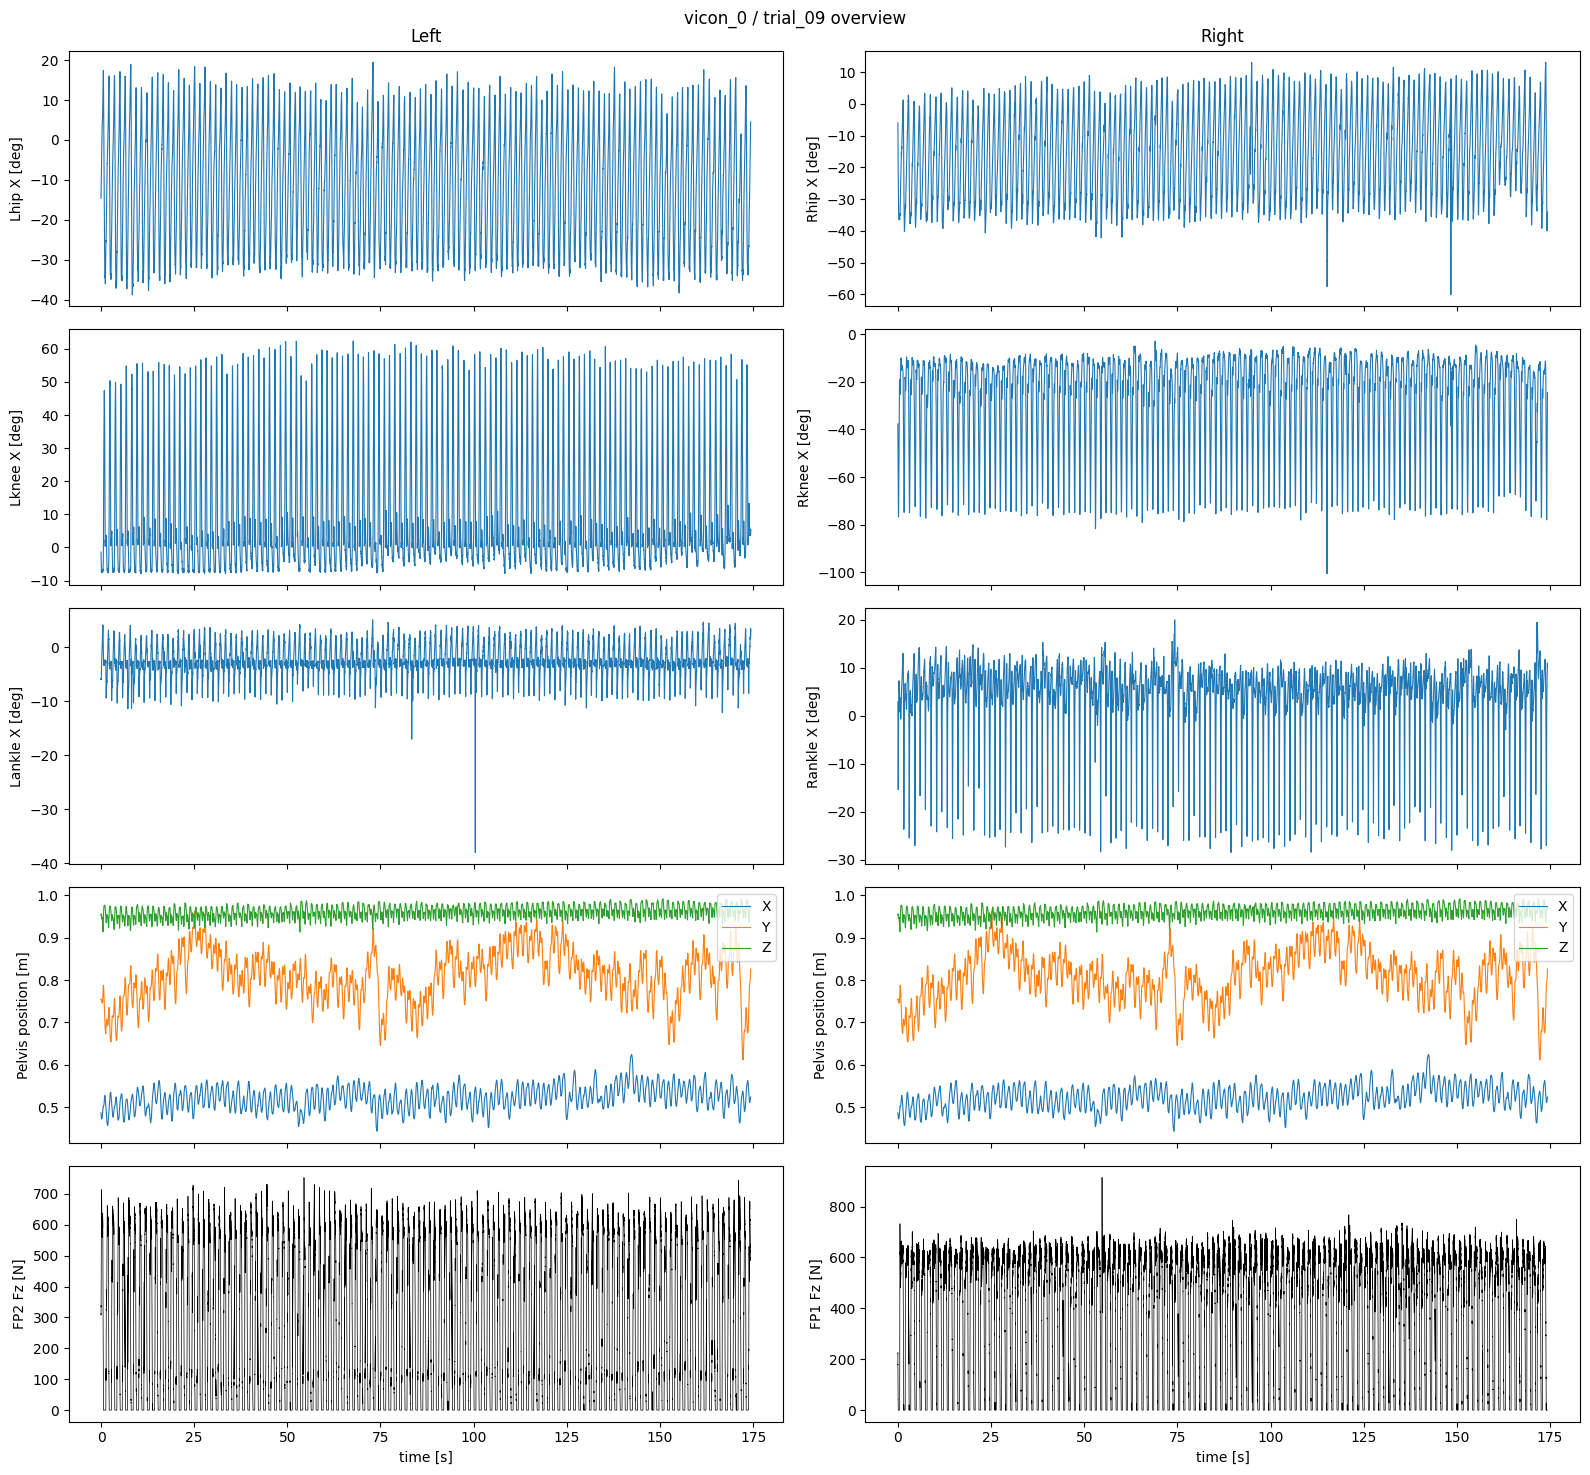

In [141]:
fig, ax = plt.subplots(5, 2, figsize=(16, 15), sharex="col")
for r, joint in enumerate(["hip", "knee", "ankle"]):
    for k, side in enumerate(["L", "R"]):
        t, y = series(df, f"{side}{joint}_angle_X")
        ax[r, k].plot(t, y, lw=0.8)
        ax[r, k].set_ylabel(f"{side}{joint} X [deg]")
for k, side in enumerate(["L", "R"]):
    for a in "XYZ":
        t, y = series(df, f"Pelvis_position_{a}")
        ax[3, k].plot(t, y, lw=0.8, label=a)
    ax[3, k].set_ylabel("Pelvis position [m]"); ax[3, k].legend(loc="upper right")
    fp = LEFT_FP if side == "L" else RIGHT_FP
    t, y = series(df, f"{fp}_Z")
    ax[4, k].plot(t, y, lw=0.5, color="k")
    ax[4, k].set_ylabel(f"{fp} Fz [N]"); ax[4, k].set_xlabel("time [s]")
    ax[0, k].set_title("Left" if side == "L" else "Right")
fig.suptitle("vicon_0 / trial_09 overview"); fig.tight_layout(); FIGS["fig1_overview"] = fig
plt.show()

## 4. Gait cycles
1. **Heel strike** = vertical force rising above `FZ_ON` (50 N); it re-arms only after dropping below `FZ_OFF` (15 N), so noise during swing is not counted.
2. A cycle runs from one heel strike to the next of the same foot. Cycles outside 0.7-1.6 s or containing NaNs are dropped.
3. Each cycle is resampled to 101 points (0-100 %).

In [142]:
def heel_strikes(fz, fs, on=FZ_ON, off=FZ_OFF):
    loaded, out = False, []
    for i, v in enumerate(fz):
        if not loaded and v > on:
            loaded = True; out.append(i)
        elif loaded and v < off:
            loaded = False
    return np.array(out) / fs

def cut_cycles(col, strikes):
    t, y = series(df, col)
    out = []
    for t0, t1 in zip(strikes[:-1], strikes[1:]):
        if not (MIN_STRIDE_S <= t1 - t0 <= MAX_STRIDE_S):
            continue
        m = (t >= t0) & (t <= t1)
        if m.sum() < 10 or np.isnan(y[m]).any():
            continue
        out.append(np.interp(np.linspace(t0, t1, 101), t[m], y[m]))
    return np.array(out)

strikes = {}
for side, fp in (("L", LEFT_FP), ("R", RIGHT_FP)):
    _, fz = series(df, f"{fp}_Z")
    strikes[side] = heel_strikes(fz, FS_FP)
    d = np.diff(strikes[side])
    print(f"{side}: {len(strikes[side])} heel strikes, median stride {np.median(d):.2f} s")

L: 159 heel strikes, median stride 1.39 s
R: 124 heel strikes, median stride 1.41 s


## 5. Figure 2: how the left and right leg work together
Every panel uses **one common time axis: the stride of the left foot** (0 % = left heel strike, 100 % = next left heel strike), so left and right can be read against each other at the same instant. The right leg is **not** re-normalised to its own heel strike: it is cut over the same time window, so it starts mid-stride and its heel strike falls where it really happens (about 46 %). Only strides of the left foot that contain exactly one right heel strike are used.
- **Gait diagram (top):** when each foot is on the ground (median timing); the gap is swing. Double support is where both bars overlap.
- **Signal panels:** thin lines = single strides, thick = mean, band = +/- 1 SD. Vertical lines: **dashed = right heel strike, dotted = toe-offs** (red = right, blue = left).
- **Step timing (bottom right):** where the right heel strike falls in the left stride; 50 % would be perfectly alternating steps.
- **Outlier cycles:** a gait cycle is deleted from a signal when any of its 101 points lies outside the pointwise mean +/- 3 SD of all the cycles of that signal (`CYCLE_SD_LIMIT`, one pass; `None` keeps everything). The number deleted per signal is printed. Figure 2b and the later sections are not filtered.
- **Sign alignment:** if the correlation of the left and right mean curves of a signal (computed over each foot's own stride) is negative, the right side is multiplied by -1 (printed, and noted in the panel title). Joint torques are inverse-dynamics moments in **Nm/kg**; set `REF_SIDE = "R"` to use the right foot as the reference.

In [143]:
rows = [("hip_angle_X", "Hip angle X [deg]"), ("knee_angle_X", "Knee angle X [deg]"),
        ("ankle_angle_X", "Ankle angle X [deg]"), ("knee_torque_X", f"Knee torque X [{TORQUE_UNIT}]"),
        ("hip_torque_lp", f"Hip torque X [{TORQUE_UNIT}] (ID, 6 Hz low-pass)"),
        ("ankle_torque_X", f"Ankle torque X [{TORQUE_UNIT}]")]
# 6 Hz zero-phase low-pass of the hip ID torque (raw signal has single-frame spikes); gaps stay NaN
from scipy.signal import butter, filtfilt
b_lp, a_lp = butter(2, 6.0 / (FS_KIN / 2))
for side in "LR":
    raw_t = df[f"{side}hip_torque_X"]
    ok = raw_t.notna()
    filled = np.interp(np.arange(len(raw_t)), np.flatnonzero(ok), raw_t[ok])
    df[f"{side}hip_torque_lp"] = np.where(ok, filtfilt(b_lp, a_lp, filled), np.nan)

REF_SIDE = "L"                       # every panel is normalised to the stride of this foot (heel strike -> next heel strike)
OTHER = "R" if REF_SIDE == "L" else "L"
COLORS = {"L": "C0", "R": "C3"}
FP_OF = {"L": LEFT_FP, "R": RIGHT_FP}
SIDE_NAME = {"L": "Left", "R": "Right"}

def toe_offs(side):
    """Toe-off time after every heel strike of `side` (first time the plate unloads), NaN if none."""
    tf_, fz_ = series(df, f"{FP_OF[side]}_Z")
    out = []
    for t0_ in strikes[side]:
        k = np.flatnonzero((tf_ >= t0_) & (fz_ < FZ_OFF))
        out.append(tf_[k[0]] if len(k) else np.nan)
    return np.array(out)

TO_T = {s: toe_offs(s) for s in "LR"}

# strides of the reference foot that contain exactly one heel strike of the other foot, with all events as % of the stride
strides = []
for i, (t0_, t1_) in enumerate(zip(strikes[REF_SIDE][:-1], strikes[REF_SIDE][1:])):
    if not (MIN_STRIDE_S <= t1_ - t0_ <= MAX_STRIDE_S):
        continue
    j = np.flatnonzero((strikes[OTHER] > t0_) & (strikes[OTHER] < t1_))
    if len(j) != 1 or np.isnan(TO_T[REF_SIDE][i]) or np.isnan(TO_T[OTHER][j[0]]):
        continue
    d_ = t1_ - t0_
    ev = dict(t0=t0_, t1=t1_, c_hs=100 * (strikes[OTHER][j[0]] - t0_) / d_, r_to=100 * (TO_T[REF_SIDE][i] - t0_) / d_,
              c_to=100 * (TO_T[OTHER][j[0]] - t0_) / d_)
    if 35 <= ev["r_to"] <= 85 and ev["c_to"] > ev["c_hs"]:
        strides.append(ev)
EV = pd.DataFrame(strides)
print(f"{len(EV)} strides of the {SIDE_NAME[REF_SIDE]} foot with one {SIDE_NAME[OTHER]} heel strike inside")
print(f"{SIDE_NAME[OTHER]} heel strike at {EV.c_hs.median():.0f} % (SD {EV.c_hs.std():.1f}) of the {SIDE_NAME[REF_SIDE]} stride "
      f"(50 % = perfectly alternating); {SIDE_NAME[REF_SIDE]} toe-off {EV.r_to.median():.0f} %, {SIDE_NAME[OTHER]} toe-off {EV.c_to.median() % 100:.0f} %")

CYCLE_SD_LIMIT = 3.0               # a gait cycle is deleted if any of its points lies outside the pointwise mean +/- this many SD of the cycles of that signal (None = keep all)
REJECTED = {}

def stride_curves(col, reject=True):
    """Signal `col` over every stride in EV, resampled to 101 points of the reference stride; strides with gaps are skipped, and so are strides
    with any point outside the pointwise mean +/- CYCLE_SD_LIMIT x SD of all the strides of this signal (one pass)."""
    t, y = series(df, col)
    out = np.full((len(EV), 101), np.nan)
    for k, e in enumerate(EV.itertuples()):
        m = (t >= e.t0) & (t <= e.t1)
        if m.sum() < 10 or np.diff(t[m]).max() > 0.05:
            continue
        out[k] = np.interp(np.linspace(e.t0, e.t1, 101), t[m], y[m])
    out = out[~np.isnan(out).any(axis=1)]
    if reject and CYCLE_SD_LIMIT is not None:
        bad = (np.abs(out - out.mean(0)) > CYCLE_SD_LIMIT * out.std(0)).any(axis=1)
        REJECTED[col] = (int(bad.sum()), len(out))
        out = out[~bad]
    return out

pct = np.arange(101)
fig = plt.figure(figsize=(15, 15))
gs = fig.add_gridspec(4, 2, height_ratios=[0.5, 1, 1, 1], hspace=0.42, wspace=0.18)
ax_g = fig.add_subplot(gs[0, 0])                                   # gait diagram (top left), step timing (top right)
ax_h = fig.add_subplot(gs[0, 1])
axs = [fig.add_subplot(gs[1 + k // 2, k % 2]) for k in range(len(rows))]   # one panel per signal in `rows`
med = EV.median()
c_to_w = med.c_to % 100

# gait diagram: stance of each foot over the reference stride (median timing); swing = gap
for y_, side, segs_ in ((1, REF_SIDE, [(0, med.r_to)]),
                        (0, OTHER, [(med.c_hs, min(med.c_to, 100))] + ([(0, c_to_w)] if med.c_to > 100 else []))):
    for a0, a1 in segs_:
        ax_g.barh(y_, a1 - a0, left=a0, height=0.6, color=COLORS[side], alpha=0.8)
        ax_g.text((a0 + a1) / 2, y_, f"stance {a1 - a0:.0f} %" if a1 - a0 > 15 else "", ha="center", va="center", color="w", fontsize=9)
ax_g.set_yticks([0, 1], [f"{SIDE_NAME[OTHER]} foot", f"{SIDE_NAME[REF_SIDE]} foot"])
ax_g.set_xlim(0, 100); ax_g.set_title(f"gait diagram, median over {len(EV)} strides (coloured = foot on the ground)")
ax_g.set_xlabel(f"stride of the {SIDE_NAME[REF_SIDE]} foot [%] (0 = {SIDE_NAME[REF_SIDE]} heel strike)")

for a, (suffix, label) in zip(axs, rows):
    cyc_o = {s: cut_cycles(f"{s}{suffix}", strikes[s]) for s in "LR"}          # own-heel-strike cycles: only used to decide the sign
    r = np.corrcoef(cyc_o["L"].mean(0), cyc_o["R"].mean(0))[0, 1]
    flip = r < 0
    print(f"{suffix:15s} corr(mean L, mean R) = {r:+.2f} -> {'flip R' if flip else 'no flip'}")
    for side in (REF_SIDE, OTHER):
        c = stride_curves(f"{side}{suffix}")
        if flip and side == "R":
            c = -c
        a.plot(pct, c.T, color=COLORS[side], alpha=0.12, lw=0.7)
        m, sd = c.mean(0), c.std(0)
        a.fill_between(pct, m - sd, m + sd, color=COLORS[side], alpha=0.18)
        a.plot(pct, m, color=COLORS[side], lw=3, label=f"{SIDE_NAME[side]} (n={len(c)})")
    ylo, yhi = a.get_ylim()
    a.axvline(med.c_hs, color=COLORS[OTHER], ls="--", lw=1.2)                    # contralateral heel strike
    a.axvline(c_to_w, color=COLORS[OTHER], ls=":", lw=1.2)                       # contralateral toe-off
    a.axvline(med.r_to, color=COLORS[REF_SIDE], ls=":", lw=1.2)                  # reference toe-off
    a.set_xlim(0, 100); a.set_ylim(ylo, yhi)
    a.set_title(label + ("  (R flipped)" if flip else "")); a.set_ylabel(label); a.grid(alpha=0.3)
    a.set_xlabel(f"stride of the {SIDE_NAME[REF_SIDE]} foot [%]")
axs[0].legend(loc="best")
if REJECTED:
    print(f"gait cycles deleted for lying outside mean +/- {CYCLE_SD_LIMIT:g} SD (deleted / before):", {k: f"{a}/{b}" for k, (a, b) in REJECTED.items()})
axs[1].text(0.99, 0.02, f"dashed = {SIDE_NAME[OTHER]} heel strike, dotted = toe-offs", transform=axs[1].transAxes, ha="right", va="bottom", fontsize=9)

ax_h.hist(EV.c_hs, bins=15, color=COLORS[OTHER], alpha=0.8)
ax_h.axvline(50, color="k", ls="--", lw=1)
ax_h.set_xlabel(f"{SIDE_NAME[OTHER]} heel strike [% of the {SIDE_NAME[REF_SIDE]} stride]"); ax_h.set_ylabel("strides")
ax_h.set_title(f"step timing: median {med.c_hs:.0f} %, SD {EV.c_hs.std():.1f} % (dashed = 50 %, symmetric)"); ax_h.grid(alpha=0.3)
FIGS["fig2_gait_cycles"] = fig
plt.show()


## 5a. Figure 2b: orientation of the ground reaction force vs the centre of pressure
Stance of both feet (heel strike to toe-off), from the force plates and the exported COP only (no onboard data needed). It uses the heel strikes and toe-offs of section 5.
- **GRF orientation** = `atan2(F_AP, Fz)`, the angle of the force vector in the sagittal plane from vertical, in degrees: **positive = the force points forward** (propulsion), negative = backward (braking). The angle is only defined while the plate carries at least `FZ_MIN_FRAC` (10 %) of the peak vertical force of that stance, and the first / last 5 % of stance are left out.
- **COP** = the exported `COP_LFT` / `COP_RFT`, Y = anterior-posterior in the foot frame, increasing from heel to toe, in mm (100 Hz, interpolated to the force-plate samples).
- **Panels:** COP over stance; GRF orientation over stance (thin = single stances, thick = mean); and the **mean GRF angle against the mean COP** per foot, a path from heel strike to toe-off (fill colour = stance phase, outline colour = foot).

In [ ]:
# Orientation of the ground reaction force in the sagittal plane vs the centre of pressure, both feet, stance only.
# GRF angle = atan2(F_AP, Fz) [deg] from vertical; positive = the force vector points forward (AP axis `AP_GRF`, + = forward, as in section 17).
# COP = exported COP of the foot (Y = AP, foot frame; it increases heel -> toe), taken at its 100 Hz rate; the plates run at 1000 Hz.
AP_GRF = "Y"                  # force-plate axis along the walking direction
FZ_MIN_FRAC = 0.10            # angle is only defined while the plate carries at least this fraction of the peak vertical force of the stance
COP_OF = {"L": "COP_LFT", "R": "COP_RFT"}
stance_grf = {}
for side in "LR":
    tz, fz_ = series(df, f"{FP_OF[side]}_Z"); ty, fy_ = series(df, f"{FP_OF[side]}_{AP_GRF}")
    n_ = min(len(fz_), len(fy_)); tz, fz_, fy_ = tz[:n_], fz_[:n_], fy_[:n_]
    tc_, cy_ = series(df, f"{COP_OF[side]}_Y")
    rows_c = []
    for t0_, to_ in zip(strikes[side], TO_T[side]):
        if np.isnan(to_) or not (0.4 <= to_ - t0_ <= 1.3):
            continue
        m_ = (tz >= t0_) & (tz <= to_)
        if m_.sum() < 200:
            continue
        fz_s, fy_s = fz_[m_], fy_[m_]
        keep = fz_s >= FZ_MIN_FRAC * fz_s.max()
        ph = (tz[m_] - t0_) / (to_ - t0_)
        cop = np.interp(tz[m_], tc_, cy_) * 1000                                 # mm
        ang = np.degrees(np.arctan2(fy_s, fz_s))
        grid = np.linspace(0.05, 0.95, 91)
        ok = keep & (ph >= 0.05) & (ph <= 0.95)
        if ok.sum() < 100:
            continue
        rows_c.append((np.interp(grid, ph[ok], cop[ok]), np.interp(grid, ph[ok], ang[ok])))
    stance_grf[side] = (np.array([r[0] for r in rows_c]), np.array([r[1] for r in rows_c]))
    print(f"{SIDE_NAME[side]}: {len(rows_c)} stances; mean GRF angle {stance_grf[side][1].mean():+.1f} deg, COP travel {np.mean(stance_grf[side][0][:, -1] - stance_grf[side][0][:, 0]):+.0f} mm")

grid = np.linspace(5, 95, 91)
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for side in "LR":
    cop_, ang_ = stance_grf[side]; col = COLORS[side]; nm = SIDE_NAME[side]
    ax[0].plot(grid, cop_.T, color=col, alpha=0.08, lw=0.6); ax[0].plot(grid, cop_.mean(0), color=col, lw=3, label=f"{nm} (n={len(cop_)})")
    ax[1].plot(grid, ang_.T, color=col, alpha=0.08, lw=0.6); ax[1].plot(grid, ang_.mean(0), color=col, lw=3, label=nm)
    ax[2].plot(cop_.mean(0), ang_.mean(0), color=col, lw=1.5, alpha=0.5)
    sc = ax[2].scatter(cop_.mean(0), ang_.mean(0), c=grid, cmap=CMAP, s=28, edgecolors=col, linewidths=1.2, zorder=3, label=nm)
    ax[2].scatter(np.median(cop_, axis=0)[::1], np.median(ang_, axis=0)[::1], s=0)
ax[0].set_ylabel("COP, AP [mm] (foot frame, heel -> toe)"); ax[1].set_ylabel("GRF angle from vertical [deg] (+ = forward)")
for a in ax[:2]:
    a.set_xlabel("stance [%]"); a.grid(alpha=0.3); a.legend(fontsize=8)
ax[1].axhline(0, color="k", lw=0.8)
ax[2].axhline(0, color="k", lw=0.8); ax[2].set_xlabel("COP, AP [mm]"); ax[2].set_ylabel("GRF angle [deg]"); ax[2].grid(alpha=0.3)
fig.colorbar(sc, ax=ax[2], label="stance [%] (fill = phase, outline = foot)")
ax[0].set_title("COP over stance"); ax[1].set_title("GRF orientation over stance"); ax[2].set_title("GRF orientation vs COP (mean per foot)")
fig.tight_layout(); FIGS["fig2b_grf_angle_vs_cop"] = fig
plt.show()


## 5b. Load the onboard knee log (`vicon_0.csv`)
- `TIME_MILLI` is in **seconds** despite its name (~20 ms steps, i.e. ~50 Hz).
- The log has a long gap: the session was paused between Nexus trials `vicon_0_001` and `vicon_0_002` (see the Nexus log printed below). The log is split into **segments** at gaps > 5 s.
- **Time-stamp filter:** `TIME_MILLI` is the time the PC *received* a sample, while the firmware samples at a fixed 20 ms. When the PC is busy it stalls (one long step) and then reads the backlog at once (a burst of ~4 ms steps), so those samples carry a late time stamp. Samples whose step from the previous one is shorter than `DT_MIN` (15 ms) or longer than `DT_MAX` (30 ms) are flagged (`ob["ts_ok"]`) and left out of the sync and of every resampled onboard signal (`onboard_at`); holes up to `MAX_BRIDGE` (0.2 s) are interpolated, longer ones become NaN gaps and are excluded downstream like logging gaps. The parameters are still read from all rows.
- The tuned parameters are logged on every row; they change roughly every 7 gait cycles (one RL iteration).

In [144]:
ONBOARD = "/Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0.csv"
NEXUS_LOG = "/Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0_nexus_log.csv"
PARAMS = ["stance_flexion_level", "swing_flexion_angle", "toa_torque_level", "fr_kp_offset", "fr_angle_offset"]

ob = pd.read_csv(ONBOARD)
ob["t"] = ob["TIME_MILLI"]  # seconds
t_ob = ob["t"].to_numpy()
dt = np.diff(t_ob)
cuts = np.flatnonzero(dt > 5.0)
segments = [(t_ob[a], t_ob[b]) for a, b in zip(np.r_[0, cuts + 1], np.r_[cuts, len(ob) - 1])]
print(f"{len(ob)} rows, median dt {np.median(dt) * 1000:.1f} ms")
for k, (a, b) in enumerate(segments):
    print(f"segment {k}: {a:.1f} - {b:.1f} s ({b - a:.1f} s)")

# --- Clean the PC time stamps. TIME_MILLI is the time the PC RECEIVED a sample; the firmware samples at a fixed ~50 Hz (20 ms).
# Most of the time the delay firmware -> PC is constant, but when the PC is busy it stalls (a long step) and then reads the backlog in one go
# (a burst of very short steps, ~4 ms). The stall sample and the burst samples carry a late time stamp, so they are flagged and not used to place
# the signal in time. A sample is flagged when the step from the previous sample is shorter than DT_MIN or longer than DT_MAX.
DT_NOM = 0.020                      # s, firmware sample period
DT_MIN, DT_MAX = 0.015, 0.030       # s, accepted step between consecutive time stamps (nominal +/- ~25-50 %)
MAX_BRIDGE = 0.20                   # s, longest hole left by removed samples that is still interpolated (a stall + its burst leaves 0.1-0.15 s);
                                    # longer = real logging gap (~1.25 s at every parameter update) -> NaN
dt_prev = np.r_[np.nan, np.diff(t_ob)]
ts_ok = ~((dt_prev < DT_MIN) | (dt_prev > DT_MAX))      # first row (NaN) stays valid
ob["ts_ok"] = ts_ok
t_ob_g, ob_g = t_ob[ts_ok], ob[ts_ok].reset_index(drop=True)   # clean samples only: used for syncing / resampling
print(f"time-stamp filter: {(~ts_ok).sum()} of {len(ob)} samples flagged ({100 * (~ts_ok).mean():.1f} %): "
      f"{int((dt_prev < DT_MIN).sum())} too fast (burst, step < {DT_MIN * 1000:.0f} ms), {int((dt_prev > DT_MAX).sum())} after a stall (step > {DT_MAX * 1000:.0f} ms); "
      f"clean median step {np.median(np.diff(t_ob_g)) * 1000:.1f} ms")

PARAMS_VARYING = [p for p in PARAMS if ob[p].nunique() > 1]
print("parameters that change:", PARAMS_VARYING)
print("constant:", {p: ob[p].iloc[0] for p in PARAMS if p not in PARAMS_VARYING})
pd.read_csv(NEXUS_LOG)

20719 rows, median dt 20.0 ms
segment 0: 1.1 - 194.7 s (193.6 s)
segment 1: 386.4 - 620.2 s (233.9 s)
time-stamp filter: 5403 of 20719 samples flagged (26.1 %): 4568 too fast (burst, step < 15 ms), 835 after a stall (step > 30 ms); clean median step 20.0 ms
parameters that change: ['stance_flexion_level', 'swing_flexion_angle', 'toa_torque_level', 'fr_angle_offset']
constant: {'fr_kp_offset': np.float64(40.0)}


,event,trial,host_time_iso,host_monotonic_s,arduino_millis,note
0,START,vicon_0_001,2026-09-21T12:36:51.288,2237.221623,1880.0,NaN
1,STOP,vicon_0_001,2026-09-21T12:40:04.928,2430.860727,195671.0,pause
2,PAUSE,vicon_0_001,2026-09-21T12:40:04.928,2430.860957,NaN,NaN
3,START,vicon_0_002,2026-09-21T12:43:16.548,2622.480850,387457.0,NaN
4,RESUME,vicon_0_002,2026-09-21T12:43:16.549,2622.481635,NaN,NaN
5,STOP,vicon_0_002,2026-09-21T12:47:10.468,2856.400184,621548.0,pause
6,PAUSE,vicon_0_002,2026-09-21T12:47:10.469,2856.400260,NaN,NaN


## 5c. Synchronise Vicon and onboard
**Why not use the Nexus log?** It stores the Arduino's `millis()`, which is a different clock from the knee's `TIME_MILLI`, and the software start has a variable delay (see `src/nexus/README_sync_setup.md` §7).

**What this does instead:** find the time offset `LAG` such that `t_onboard = t_vicon + LAG` by maximising the correlation between the knee's `ACTUATOR_POSITION` and the Vicon knee flexion angle.
1. Try both legs and every onboard segment, with a coarse 0.1 s grid followed by a fine 5 ms grid. The leg that correlates best is the **prosthetic side**.
2. Repeat the fine search in 30 s windows. If the clocks drift, the window lags will trend; a flat line means a single offset is enough.

In [145]:
MIN_VALID_FRAC = 0.6                # a lag is scored only if at least this fraction of the Vicon samples has clean onboard data
KNEE_SIGN = {"L": 1.0, "R": -1.0}   # Vicon sign convention: + = flexion after this flip
T_VICON = df["Lknee_angle_X"].last_valid_index() / FS_KIN   # kinematics duration (force plates run longer)

def onboard_at(col, t_vicon, lag):
    """Onboard signal sampled at Vicon times (t_onboard = t_vicon + lag), from the clean-time-stamp samples only (ob_g).
    Samples with a late PC time stamp (stall / burst, see 5b) are skipped and bridged by interpolation if the hole is shorter than
    MAX_BRIDGE; longer holes (logging gaps) and anything outside the log are NaN."""
    tq = t_vicon + lag
    y = np.interp(tq, t_ob_g, ob_g[col].to_numpy(), left=np.nan, right=np.nan)
    i = np.clip(np.searchsorted(t_ob_g, tq), 1, len(t_ob_g) - 1)
    y[(t_ob_g[i] - t_ob_g[i - 1]) > MAX_BRIDGE] = np.nan
    return y

def corr_at_lags(side, lags, t_range=None):
    t, y = series(df, f"{side}knee_angle_X")
    y = KNEE_SIGN[side] * y
    if t_range is not None:
        m = (t >= t_range[0]) & (t < t_range[1]); t, y = t[m], y[m]
    r = np.full(len(lags), np.nan)
    for k, L in enumerate(lags):
        o = onboard_at("ACTUATOR_POSITION", t, L)
        m = ~np.isnan(o) & ~np.isnan(y)
        if m.sum() > MIN_VALID_FRAC * len(t):          # enough clean samples (the time-stamp filter removes ~20 % of the onboard samples)
            r[k] = np.corrcoef(o[m], y[m])[0, 1]
    return r

def search(side, lo, hi, t_range=None):
    coarse = np.arange(lo, hi, 0.1)
    rc = corr_at_lags(side, coarse, t_range)
    if np.all(np.isnan(rc)):
        return np.nan, np.nan
    c = coarse[np.nanargmax(rc)]
    fine = np.arange(c - 0.15, c + 0.15, 0.005)
    rf = corr_at_lags(side, fine, t_range)
    k = np.nanargmax(rf)
    return fine[k], rf[k]

sync = []
for side in "LR":
    for k, (a, b) in enumerate(segments):
        if b - a < 0.8 * T_VICON:
            continue
        lag, r = search(side, a - 0.5, b - 0.8 * T_VICON + 0.5)
        sync.append({"side": side, "segment": k, "lag_s": lag, "r": r})
sync = pd.DataFrame(sync)
best = sync.loc[sync["r"].idxmax()]
PROSTHETIC_SIDE, LAG = best["side"], float(best["lag_s"])
SOUND_SIDE = "R" if PROSTHETIC_SIDE == "L" else "L"
PROSTHETIC_FP = LEFT_FP if PROSTHETIC_SIDE == "L" else RIGHT_FP
print(f"prosthetic side = {PROSTHETIC_SIDE}, LAG = {LAG:.3f} s (r = {best['r']:.3f}), plate {PROSTHETIC_FP}")
sync.round(3)

prosthetic side = L, LAG = 1.118 s (r = 0.992), plate FP2


,side,segment,lag_s,r
0,L,0,1.118,0.992
1,L,1,476.231,0.152
2,R,0,1.783,0.914
3,R,1,475.506,0.133


window lag spread: 0 ms


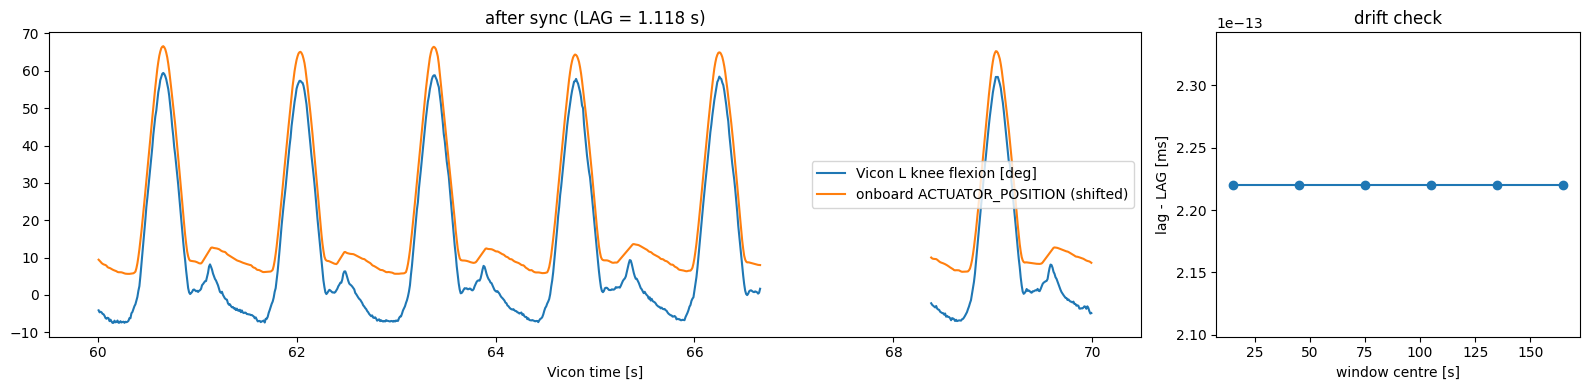

In [146]:
# drift check: fine lag in 30 s windows
win = []
for w0 in np.arange(0, T_VICON - 10, 30):
    lags = np.arange(LAG - 0.3, LAG + 0.3, 0.005)
    r = corr_at_lags(PROSTHETIC_SIDE, lags, (w0, w0 + 30))
    k = np.nanargmax(r)
    win.append({"window_start_s": w0, "lag_s": lags[k], "r": r[k]})
win = pd.DataFrame(win)
print(f"window lag spread: {(win.lag_s.max() - win.lag_s.min()) * 1000:.0f} ms")

t, y = series(df, f"{PROSTHETIC_SIDE}knee_angle_X")
o = onboard_at("ACTUATOR_POSITION", t, LAG)
y = np.where(np.isnan(o), np.nan, y)      # Vicon is taken out wherever the onboard data is missing (logging gap / filtered time stamps)
fig, ax = plt.subplots(1, 2, figsize=(16, 4), gridspec_kw={"width_ratios": [3, 1]})
m = (t > 60) & (t < 70)
ax[0].plot(t[m], KNEE_SIGN[PROSTHETIC_SIDE] * y[m], label=f"Vicon {PROSTHETIC_SIDE} knee flexion [deg]")
ax[0].plot(t[m], o[m], label="onboard ACTUATOR_POSITION (shifted)")
ax[0].set_xlabel("Vicon time [s]"); ax[0].legend(); ax[0].set_title(f"after sync (LAG = {LAG:.3f} s)")
ax[1].plot(win.window_start_s + 15, (win.lag_s - LAG) * 1000, "o-")
ax[1].set_xlabel("window centre [s]"); ax[1].set_ylabel("lag - LAG [ms]"); ax[1].set_title("drift check")
fig.tight_layout(); FIGS["fig3_sync"] = fig
plt.show()

## 5d. Onboard shank / thigh / knee angles vs Vicon (ground truth)
How well do the angles measured by the knee agree with Vicon, in the **prosthetic** leg? All angles are flexion-positive, in degrees, on the Vicon 100 Hz clock (onboard resampled with the sync offset `LAG`).
- **Onboard:** knee = `ACTUATOR_POSITION`, shank = `SHANK_ANGLE`, thigh = knee - shank (the repo's `HIP_ANGLE`, `src/utils/utils.py`). **`SHANK_ANGLE` is read `SHANK_DELAY` = 35 ms later than the knee** (its IMU signal lags `ACTUATOR_POSITION`; the best delay is 30-40 ms in every 60 s window). Without it the thigh velocity / acceleration match Vicon at only r = 0.68 / 0.55, with it 0.99 / 0.89. Set `SHANK_DELAY = 0` to switch it off.
- **Vicon:** knee = prosthetic-side knee angle X (sign-aligned), thigh = -hip angle X - pelvis tilt (thigh from vertical), shank = knee - thigh. The shank is therefore *derived*, not measured, and the thigh definition is the one (of 6 sign/pelvis combinations tried) that best matches the onboard thigh, so its agreement is slightly flattering. The printed check shows all candidates.
- **Swing** = from toe-off to the next heel strike of the prosthetic side.
- **Logging gaps:** the knee log pauses for ~1.25 s at every parameter update. Those samples (plus 0.3 s either side, because of the filtering) are interpolated, so they are **excluded** from all numbers and plots in this section, for the onboard *and* the Vicon signal (the Vicon samples at those times are taken out as well). `SYNCED` holds the paired onboard / Vicon angles with NaN at the removed samples; `only_valid(x)` does the same for any 100 Hz array.
- **Columns:** `r` correlation, `offset` = mean(onboard - Vicon), `RMSE`, `RMSE no offset` (= SD of the difference), `slope` of onboard against Vicon (1 = same range), and the correlation of the **velocity** and **acceleration** (4 Hz low-pass, then differentiated), which is what inverse dynamics actually uses.

In [147]:
from scipy import stats
from scipy.signal import butter, filtfilt

# common 100 Hz grid on the Vicon clock
N = df["Lknee_angle_X"].last_valid_index() + 1
tg = np.arange(N) / FS_KIN

def fill_nan(y):
    ok = ~np.isnan(y)
    return np.interp(np.arange(len(y)), np.flatnonzero(ok), y[ok])

def vicon_grid(col):
    t_, y_ = series(df, col)
    return np.interp(tg, t_, y_)

ob_knee = onboard_at("ACTUATOR_POSITION", tg, LAG)
# SHANK_ANGLE (IMU) is delayed relative to ACTUATOR_POSITION: measured against Vicon, the shank matches best when the onboard signal is read
# SHANK_DELAY later (30-40 ms in every 60 s window, i.e. about 2 samples). Without this the onboard thigh (= knee - shank) has the right
# angle (r 0.92) but a wrong velocity / acceleration (r 0.68 / 0.55), which ruins the inverse-dynamics torque. 0 = no correction.
SHANK_DELAY = 0.035   # s
ob_shank = onboard_at("SHANK_ANGLE", tg, LAG + SHANK_DELAY)
gap = np.isnan(ob_knee) | np.isnan(ob_shank)
print("onboard NaN samples filled (logging gaps):", int(gap.sum()))
ob_knee, ob_shank = fill_nan(ob_knee), fill_nan(ob_shank)
# samples near a logging gap are interpolated and unreliable: exclude them (gap dilated by 0.3 s) from every comparison below
from scipy.ndimage import binary_dilation
valid = ~binary_dilation(gap, iterations=int(0.3 * FS_KIN))
print(f"valid (gap-free) samples: {valid.sum() / FS_KIN:.0f} s of {N / FS_KIN:.0f} s")
ob_thigh = ob_knee - ob_shank          # repo definition of HIP_ANGLE

# Vicon counterparts (same convention: flexion positive, thigh angle from vertical)
v_knee = KNEE_SIGN[PROSTHETIC_SIDE] * vicon_grid(f"{PROSTHETIC_SIDE}knee_angle_X")
hipX, pelX = vicon_grid(f"{PROSTHETIC_SIDE}hip_angle_X"), vicon_grid("Pelvis_ang_pos_X")

# swing mask of the prosthetic side: toe-off (plate unloads) -> next heel strike
tf_, fz_ = series(df, f"{PROSTHETIC_FP}_Z")
sw = np.zeros(N, bool)
hs_ = strikes[PROSTHETIC_SIDE]
for t0_, t1_ in zip(hs_[:-1], hs_[1:]):
    if not (MIN_STRIDE_S <= t1_ - t0_ <= MAX_STRIDE_S) or t1_ * FS_KIN >= N:
        continue
    m_ = (tf_ > t0_) & (tf_ < t1_)
    below = np.flatnonzero(fz_[m_] < FZ_OFF)
    if len(below) == 0:
        continue
    to_ = tf_[m_][below[0]]
    if 0.4 <= (to_ - t0_) / (t1_ - t0_) <= 0.8:
        sw[int(to_ * FS_KIN):int(t1_ * FS_KIN)] = True
sw_ok = sw & valid   # swing samples with real (non-interpolated) onboard data
print(f"swing samples: {sw.sum() / FS_KIN:.0f} s, of which gap-free: {sw_ok.sum() / FS_KIN:.0f} s")

print("\nSIGN CHECK, swing phase only:")
print(f"  knee  onboard vs Vicon: r = {np.corrcoef(ob_knee[sw_ok], v_knee[sw_ok])[0, 1]:+.3f}")
cands = {f"{sh}hip {sp}pelvis": sh_v * hipX + sp_v * pelX
         for sh, sh_v in (("+", 1), ("-", -1)) for sp, sp_v in (("+", 1), ("-", -1))}
cands.update({"+hip": hipX, "-hip": -hipX})
rs = {k_: np.corrcoef(ob_thigh[sw_ok], v_[sw_ok])[0, 1] for k_, v_ in cands.items()}
for k_, r_ in sorted(rs.items(), key=lambda kv: -kv[1]):
    print(f"  thigh onboard vs Vicon [{k_:>12s}]: r = {r_:+.3f}")
best_cand = max(rs, key=rs.get)
v_thigh = cands[best_cand]
v_shank = v_knee - v_thigh
print(f"  -> Vicon thigh used: {best_cand} (best match to the onboard thigh)")

# Vicon data at the times where the onboard data is missing or was interpolated (logging gaps, filtered time stamps, 0.3 s margin) is taken out as well.
# The filled arrays above stay as they are because the filters below cannot take NaN; `only_valid` gives the NaN version for plots / export.
def only_valid(x):
    return np.where(valid, x, np.nan)
SYNCED = pd.DataFrame({"t_vicon": tg, "t_onboard": tg + LAG, "swing": sw_ok})
for k_, o_, v_ in (("thigh", ob_thigh, v_thigh), ("knee", ob_knee, v_knee), ("shank", ob_shank, v_shank)):
    SYNCED[f"onboard_{k_}"], SYNCED[f"vicon_{k_}"] = only_valid(o_), only_valid(v_)
print(f"SYNCED: {int(valid.sum())} of {N} samples ({valid.sum() / FS_KIN:.0f} s) have valid onboard AND Vicon data; the other {int((~valid).sum())} are NaN in both")


onboard NaN samples filled (logging gaps): 3271
valid (gap-free) samples: 130 s of 174 s
swing samples: 66 s, of which gap-free: 51 s

SIGN CHECK, swing phase only:
  knee  onboard vs Vicon: r = +0.999
  thigh onboard vs Vicon [-hip -pelvis]: r = +0.995
  thigh onboard vs Vicon [        -hip]: r = +0.990
  thigh onboard vs Vicon [-hip +pelvis]: r = +0.966
  thigh onboard vs Vicon [+hip -pelvis]: r = -0.966
  thigh onboard vs Vicon [        +hip]: r = -0.990
  thigh onboard vs Vicon [+hip +pelvis]: r = -0.995
  -> Vicon thigh used: -hip -pelvis (best match to the onboard thigh)
SYNCED: 12992 of 17433 samples (130 s) have valid onboard AND Vicon data; the other 4441 are NaN in both


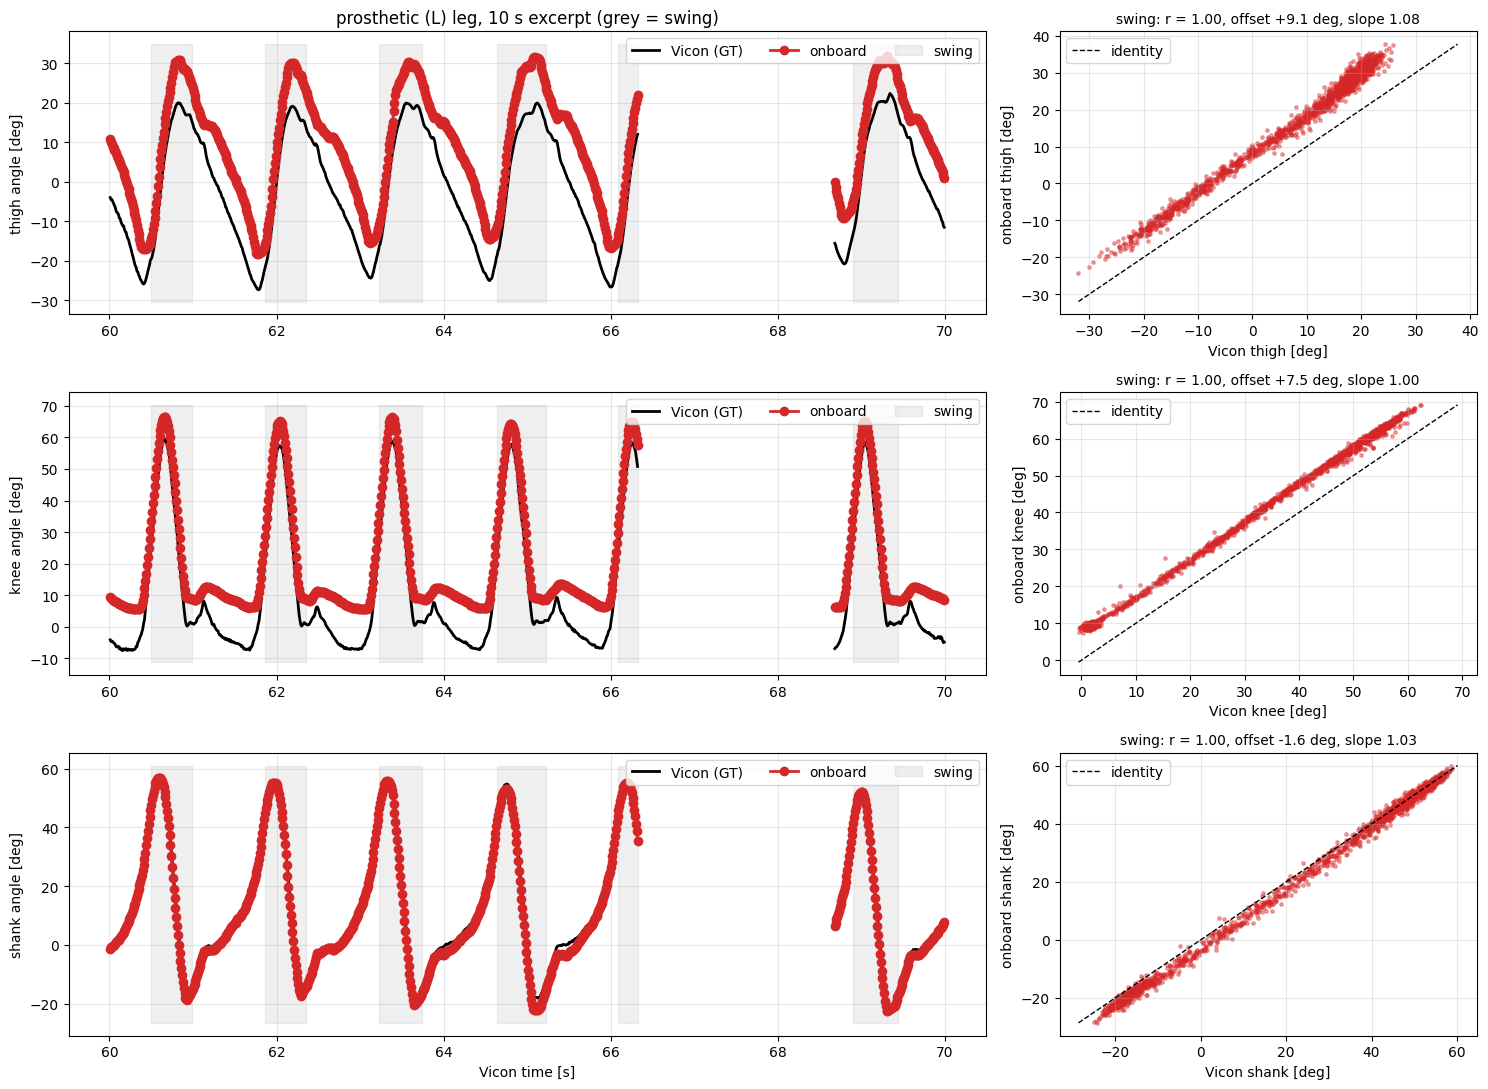

,angle,phase,r,offset [deg],RMSE [deg],RMSE no offset [deg],slope,velocity r,acceleration r
0,thigh,whole trial,0.98,10.48,10.83,2.73,0.97,0.97,0.92
1,thigh,swing,1.00,9.08,9.25,1.78,1.08,0.99,0.96
2,knee,whole trial,0.99,9.22,9.60,2.67,0.93,0.99,0.98
3,knee,swing,1.00,7.51,7.55,0.77,1.00,1.00,1.00
4,shank,whole trial,1.00,-1.26,1.95,1.48,1.03,1.00,0.99
5,shank,swing,1.00,-1.56,2.33,1.73,1.03,1.00,1.00


In [148]:
b_a, a_a = butter(2, 4.0 / (FS_KIN / 2))
d1 = lambda x: np.gradient(filtfilt(b_a, a_a, x), 1 / FS_KIN)
d2 = lambda x: np.gradient(d1(x), 1 / FS_KIN)
ANGLES = {"thigh": (ob_thigh, v_thigh), "knee": (ob_knee, v_knee), "shank": (ob_shank, v_shank)}
rows_a = []
for name, (o_, v_) in ANGLES.items():
    for phase, m_ in (("whole trial", valid), ("swing", sw_ok)):
        d_ = o_[m_] - v_[m_]
        rows_a.append({"angle": name, "phase": phase,
                       "r": np.corrcoef(o_[m_], v_[m_])[0, 1], "offset [deg]": d_.mean(),
                       "RMSE [deg]": np.sqrt((d_ ** 2).mean()), "RMSE no offset [deg]": d_.std(),
                       "slope": np.polyfit(v_[m_], o_[m_], 1)[0],
                       "velocity r": np.corrcoef(d1(o_)[m_], d1(v_)[m_])[0, 1],
                       "acceleration r": np.corrcoef(d2(o_)[m_], d2(v_)[m_])[0, 1]})
angle_table = pd.DataFrame(rows_a).round(2)

fig, ax = plt.subplots(3, 2, figsize=(15, 11), gridspec_kw={"width_ratios": [2.2, 1]})
w_ = (tg > 60) & (tg < 70) 
for i, (name, (o_, v_)) in enumerate(ANGLES.items()):
    r_sw = angle_table[(angle_table.angle == name) & (angle_table.phase == "swing")].iloc[0]
    a = ax[i, 0]
    a.plot(tg[w_], only_valid(v_)[w_], "k", lw=2, label="Vicon (GT)")          # both taken out where the onboard data is missing
    a.plot(tg[w_], only_valid(o_)[w_], "C3", lw=2, label="onboard", marker = "o")
    a.fill_between(tg[w_], a.get_ylim()[0], a.get_ylim()[1], where=sw_ok[w_], color="gray", alpha=0.12, step="mid", label="swing")
    a.set_ylabel(f"{name} angle [deg]"); a.grid(alpha=0.3); a.legend(loc="upper right", ncol=3)
    b = ax[i, 1]
    b.scatter(v_[sw_ok][::3], o_[sw_ok][::3], s=6, alpha=0.4, color="C3")
    lim = [min(v_[sw_ok].min(), o_[sw_ok].min()), max(v_[sw_ok].max(), o_[sw_ok].max())]
    b.plot(lim, lim, "k--", lw=1, label="identity")
    b.set_xlabel(f"Vicon {name} [deg]"); b.set_ylabel(f"onboard {name} [deg]")
    b.set_title(f"swing: r = {r_sw['r']:.2f}, offset {r_sw['offset [deg]']:+.1f} deg, slope {r_sw['slope']:.2f}", fontsize=10)
    b.grid(alpha=0.3); b.legend(loc="upper left")
ax[0, 0].set_title(f"prosthetic ({PROSTHETIC_SIDE}) leg, 10 s excerpt (grey = swing)")
ax[-1, 0].set_xlabel("Vicon time [s]")
fig.tight_layout(); FIGS["fig3b_angles_vs_vicon"] = fig
plt.show()
angle_table

## 9. Swing-phase hip torque per prosthetic gait cycle
- A stride runs from one **prosthetic-side heel strike** to the next (Vicon force plate).
- **Swing** = from **toe-off** (the plate unloads, Fz < `FZ_OFF`) to the next heel strike. Strides whose stance fraction is outside 40-80 % are dropped as detection errors.
- Hip torque: `{side}hip_torque_{HIP_AXIS}`, X = sagittal plane, **low-pass filtered at 6 Hz** (zero phase) because the raw inverse-dynamics signal has single-frame spikes. Units: **Nm/kg** (body-mass normalised).
- **Features:** `swing_peak_min` = minimum of the hip torque inside swing. `swing_peak_max` = **maximum after that minimum** (the late-swing rise before heel strike), not the maximum of the whole swing, which would just pick up the torque carried over from stance at toe-off. `*_at_pct` records where in swing (0 = toe-off, 100 = heel strike) each peak occurred; a max sitting at 100 % means the torque is still rising at heel strike (no turning point inside swing).
- Each stride's parameters are read from the onboard log at `t + LAG`. A stride is **dropped if the parameters changed during it**. Consecutive strides with the same parameters form a **block** (one RL iteration). The first `ADAPT_CYCLES` strides of each block are excluded from the block means.

In [149]:
from scipy.signal import butter, filtfilt
HIP_AXIS = "X"
ADAPT_CYCLES = 2
HIP_LP_HZ = 6.0   # low-pass cut-off for the inverse-dynamics torque (removes single-frame spikes)
hip_col = f"{PROSTHETIC_SIDE}hip_torque_{HIP_AXIS}"
th, yh_raw = series(df, hip_col)
bad = np.isnan(yh_raw)
yh_fill = np.interp(th, th[~bad], yh_raw[~bad])           # fill the few NaNs so the filter can run
b_lp, a_lp = butter(2, HIP_LP_HZ / (FS_KIN / 2))             # 2nd order, applied forward+backward = zero phase
yh = filtfilt(b_lp, a_lp, yh_fill)
yh[bad] = np.nan                                              # keep the original gaps (cycles with gaps are dropped)
print(f"hip torque filtered at {HIP_LP_HZ} Hz; largest change from filtering: {np.nanmax(np.abs(yh - yh_raw)):.2f}")

def params_at(t_vicon):
    i = np.clip(np.searchsorted(t_ob, t_vicon + LAG, side="right") - 1, 0, len(ob) - 1)
    return ob.iloc[i]

tf, fz = series(df, f"{PROSTHETIC_FP}_Z")

def toe_off(t0, t1):
    """First time after heel strike t0 at which the plate unloads = start of swing."""
    m = (tf > t0) & (tf < t1)
    below = np.flatnonzero(fz[m] < FZ_OFF)
    return tf[m][below[0]] if len(below) else np.nan

hs = strikes[PROSTHETIC_SIDE]
rows, curves = [], []
for t0, t1 in zip(hs[:-1], hs[1:]):
    if not (MIN_STRIDE_S <= t1 - t0 <= MAX_STRIDE_S):
        continue
    p0, p1 = params_at(t0), params_at(t1)
    if not np.allclose(p0[PARAMS].astype(float), p1[PARAMS].astype(float)):
        continue
    to = toe_off(t0, t1)
    if np.isnan(to) or not (0.4 <= (to - t0) / (t1 - t0) <= 0.8):
        continue
    m = (th >= to) & (th <= t1)
    if m.sum() < 10 or np.isnan(yh[m]).any():
        continue
    c = np.interp(np.linspace(to, t1, 101), th[m], yh[m])   # swing, resampled to 0-100 %
    curves.append(c)
    rows.append({"t0": t0, "stride_s": t1 - t0, "swing_s": t1 - to, "onboard_cycle": int(p0["CYCLE_INDEX"]),
                 **{p: float(p0[p]) for p in PARAMS_VARYING},
                 "swing_peak_min": c.min(), "min_at_pct": int(c.argmin()),
                 "swing_peak_max": c[c.argmin():].max(),                      # max AFTER the swing minimum
                 "max_at_pct": int(c.argmin() + c[c.argmin():].argmax())})
cyc = pd.DataFrame(rows)
curves = np.array(curves)
cyc["block"] = (cyc[PARAMS_VARYING].diff().abs().sum(axis=1) > 0).cumsum()
cyc["n_in_block"] = cyc.groupby("block").cumcount()
METRICS = ["swing_peak_max", "swing_peak_min"]

steady = cyc["n_in_block"] >= ADAPT_CYCLES
blk = cyc[steady].groupby("block").agg({**{p: "first" for p in PARAMS_VARYING}, **{m: "mean" for m in METRICS},
                                        "t0": "first", "onboard_cycle": "count"}).rename(columns={"onboard_cycle": "n_cycles"})
blk_curves = np.array([curves[(cyc.block == b).to_numpy() & steady.to_numpy()].mean(0) for b in blk.index])
print(f"{len(cyc)} clean strides, median swing {cyc.swing_s.median():.2f} s, {cyc.block.nunique()} parameter blocks, "
      f"{steady.sum()} strides after dropping {ADAPT_CYCLES}/block")
edge = lambda x: 100 * ((x <= 2) | (x >= 98)).mean()
print(f"where the peaks fall in swing (pct of swing): max median {cyc.max_at_pct.median():.0f}, min median {cyc.min_at_pct.median():.0f}; "
      f"peak at an edge (<=2 or >=98): max {edge(cyc.max_at_pct):.0f} pct of strides, min {edge(cyc.min_at_pct):.0f} pct")
blk.round(3)

hip torque filtered at 6.0 Hz; largest change from filtering: 3.75
105 clean strides, median swing 0.55 s, 18 parameter blocks, 69 strides after dropping 2/block
where the peaks fall in swing (pct of swing): max median 99, min median 79; peak at an edge (<=2 or >=98): max 94 pct of strides, min 0 pct


,stance_flexion_level,swing_flexion_angle,toa_torque_level,fr_angle_offset,swing_peak_max,swing_peak_min,t0,n_cycles
block,,,,,,,,
0,0.700,0.700,0.700,0.000,0.091,-0.229,2.779,4
1,0.665,0.665,0.600,3.800,0.047,-0.250,12.973,2
2,0.630,0.631,0.530,7.600,0.011,-0.314,20.115,5
3,0.595,0.666,0.505,11.400,0.030,-0.234,31.398,3
4,0.560,0.685,0.410,15.200,0.012,-0.227,39.886,5
5,0.547,0.720,0.510,19.000,0.019,-0.219,51.330,5
6,0.512,0.685,0.410,15.200,0.038,-0.192,62.361,3
7,0.477,0.650,0.310,19.000,0.038,-0.248,70.817,4
8,0.501,0.685,0.410,22.800,0.058,-0.211,80.674,5


## 10. Figure 4: timeline of hip torque and parameters
Top: swing hip-torque peaks per stride (dots) and block means (lines). Bottom: the parameters the knee was running. Read top and bottom together to see whether a parameter change shows up in the hip.

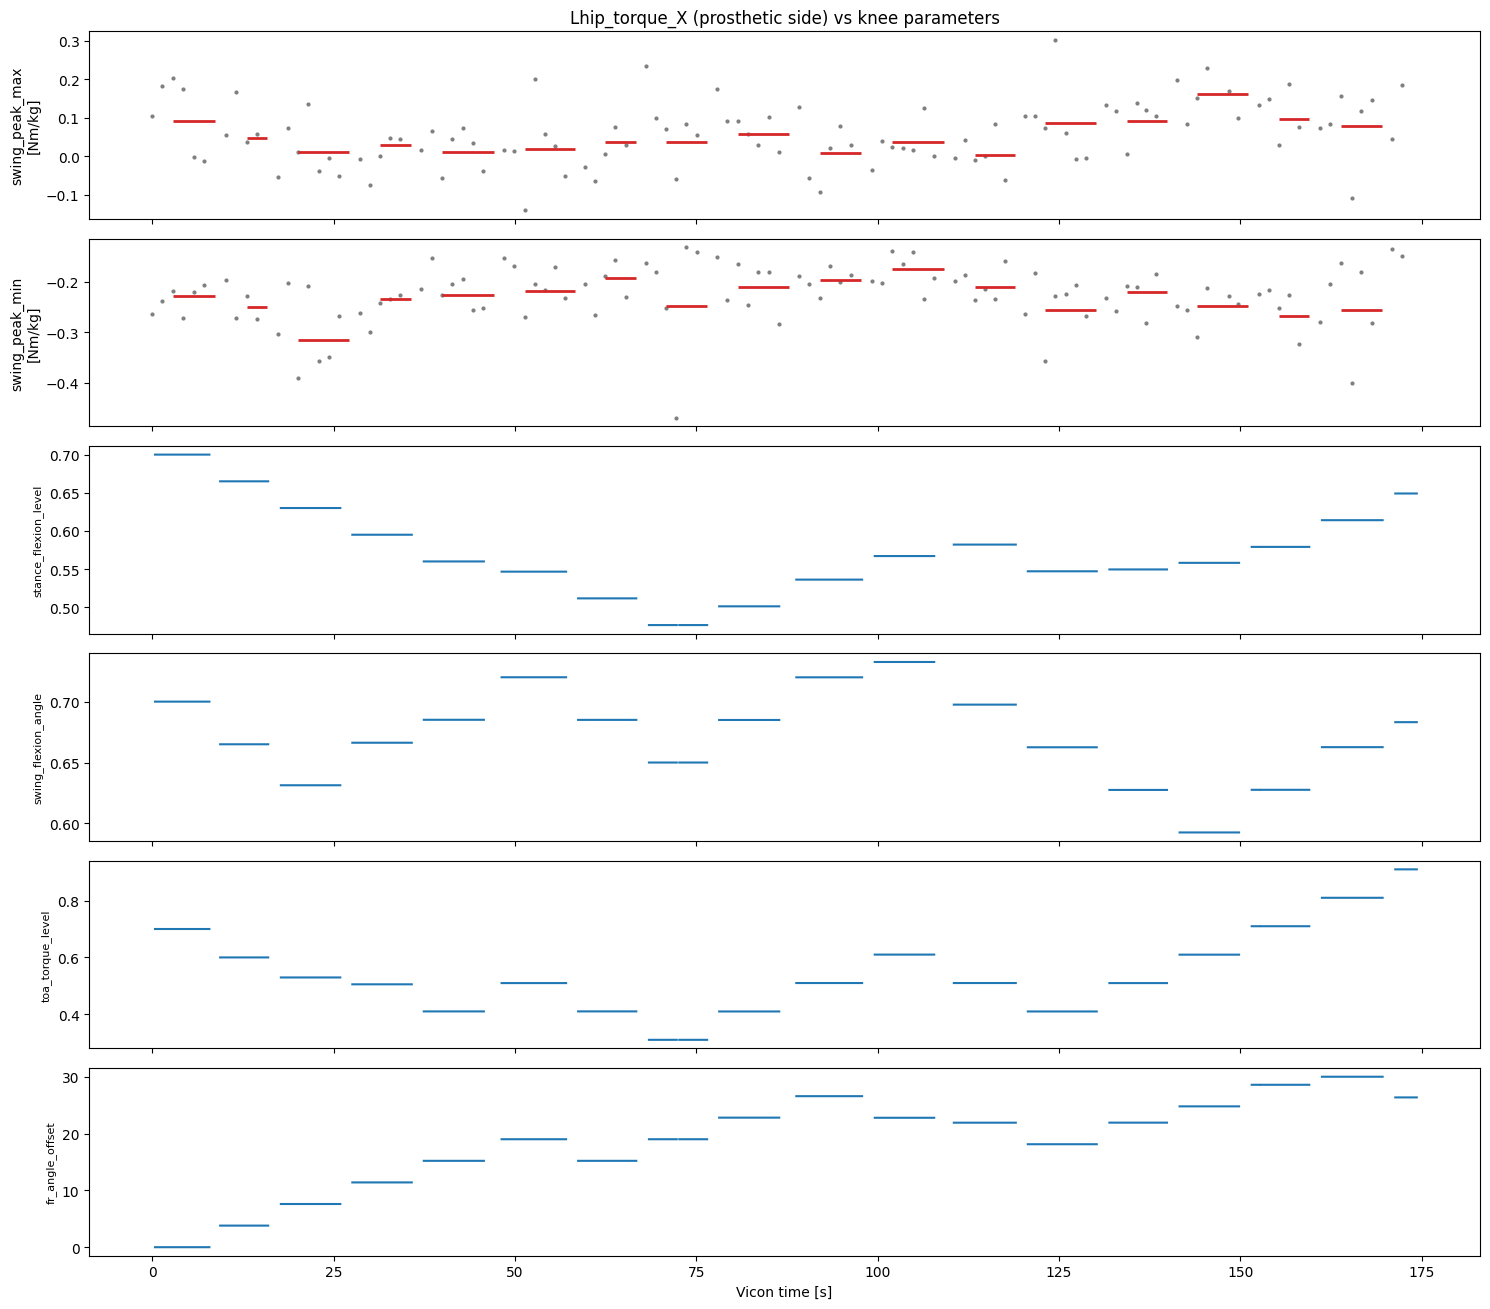

In [150]:
fig, ax = plt.subplots(len(METRICS) + len(PARAMS_VARYING), 1, figsize=(15, 2.2 * (len(METRICS) + len(PARAMS_VARYING))), sharex=True)
for i, mtr in enumerate(METRICS):
    ax[i].plot(cyc.t0, cyc[mtr], ".", color="gray", ms=4)
    for b, g in cyc[steady].groupby("block"):
        ax[i].hlines(g[mtr].mean(), g.t0.min(), g.t0.max() + g.stride_s.iloc[-1], color="C3", lw=2)
    ax[i].set_ylabel(f"{mtr}\n[{TORQUE_UNIT}]")
ax[0].set_title(f"{hip_col} (prosthetic side) vs knee parameters")
for j, p in enumerate(PARAMS_VARYING):
    a = ax[len(METRICS) + j]
    tt = np.linspace(0, T_VICON, 2000)
    a.step(tt, onboard_at(p, tt, LAG), where="post", color="C0")
    a.set_ylabel(p, fontsize=8)
ax[-1].set_xlabel("Vicon time [s]")
fig.tight_layout(); FIGS["fig4_timeline"] = fig
plt.show()

## 11. Figure 5: swing hip-torque profile coloured by parameter value
Each line is one block's mean hip-torque curve over the prosthetic **swing phase** (0 % = toe-off, 100 % = heel strike), coloured by that block's value of one parameter. If a parameter matters, the colours should sort into an order somewhere in the cycle.

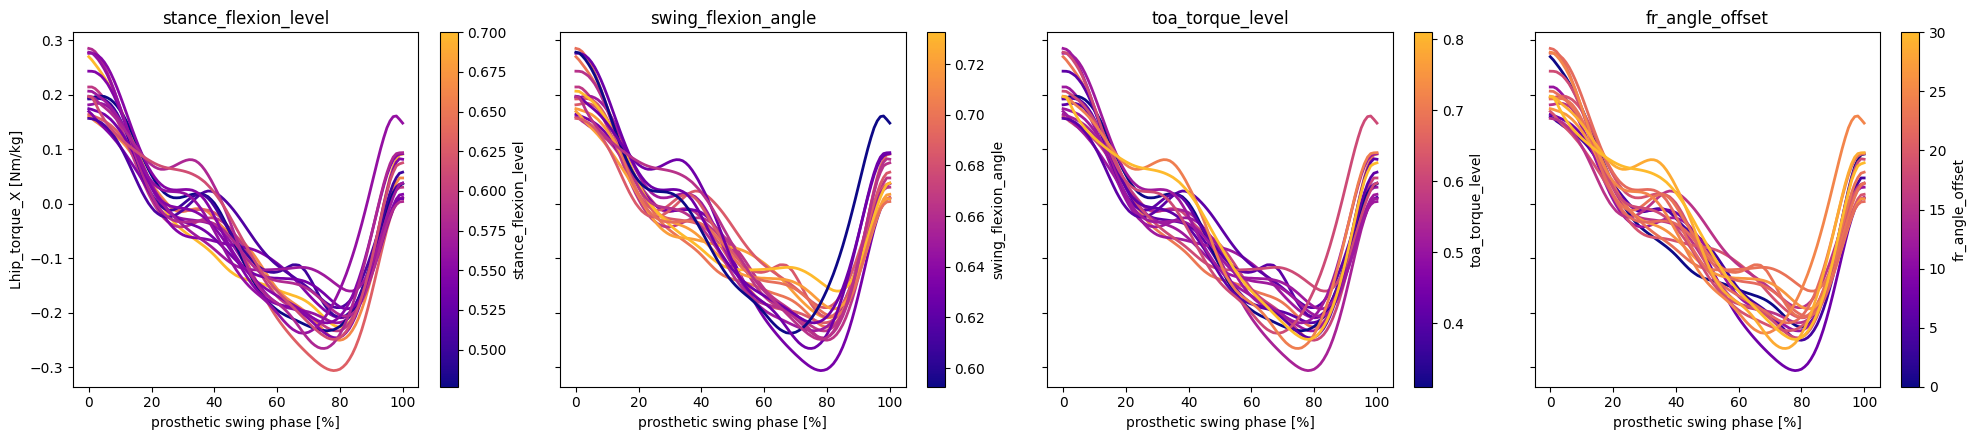

In [151]:
pct = np.arange(101)
fig, ax = plt.subplots(1, len(PARAMS_VARYING), figsize=(5 * len(PARAMS_VARYING), 4.5), sharey=True)
for a, p in zip(np.atleast_1d(ax), PARAMS_VARYING):
    vals = blk[p].to_numpy()
    norm = plt.Normalize(vals.min(), vals.max())
    for c, v in zip(blk_curves, vals):
        a.plot(pct, c, color=CMAP(norm(v)), lw=2)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=CMAP), ax=a, label=p)
    a.set_xlabel("prosthetic swing phase [%]"); a.set_title(p)
np.atleast_1d(ax)[0].set_ylabel(f"{hip_col} [{TORQUE_UNIT}]")
fig.tight_layout(); FIGS["fig5_profiles"] = fig
plt.show()

## 12. Figure 6: block means vs each parameter
One dot per block. `r` and `p` are Pearson correlations across blocks.
**Caution:** the RL agent changes several parameters at once, so the parameters are correlated with each other (matrix printed below). A correlation with one parameter can actually come from another. The regression in the next cell estimates each parameter's effect while holding the others fixed, but with this few blocks it is only indicative.

**Multiple comparisons:** this figure shows 2 features x 4 parameters = 8 tests. At p < 0.05 you expect about 0.4 false positives by chance, and a Bonferroni-corrected threshold would be p < 0.006. Treat any single p between 0.003 and 0.05 as a lead to confirm with more data, not as a result.

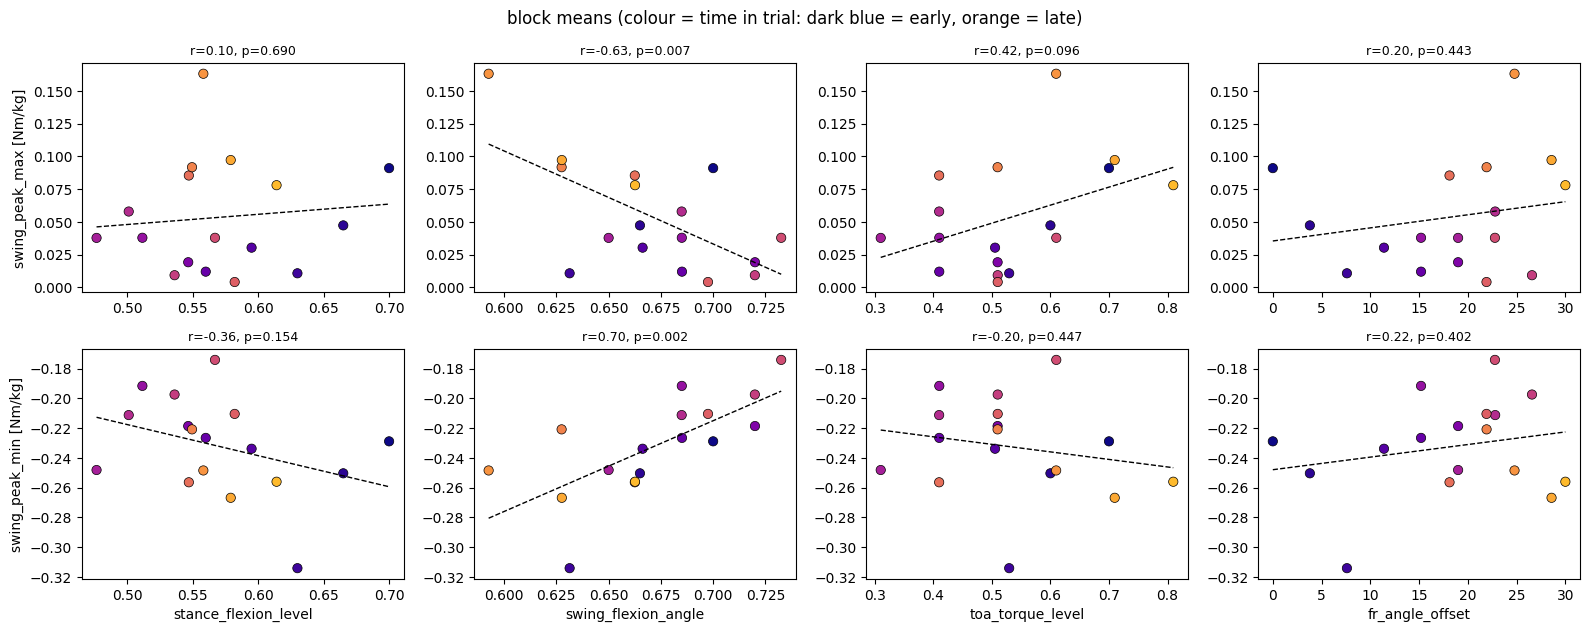

parameter correlation across blocks:


,stance_flexion_level,swing_flexion_angle,toa_torque_level,fr_angle_offset
stance_flexion_level,1.00,-0.02,0.7,-0.59
swing_flexion_angle,-0.02,1.00,-0.1,-0.08
toa_torque_level,0.70,-0.10,1.0,0.10
fr_angle_offset,-0.59,-0.08,0.1,1.00


In [152]:
from scipy import stats
fig, ax = plt.subplots(len(METRICS), len(PARAMS_VARYING), figsize=(4 * len(PARAMS_VARYING), 3.2 * len(METRICS)), squeeze=False)
for i, mtr in enumerate(METRICS):
    for j, p in enumerate(PARAMS_VARYING):
        a = ax[i, j]
        a.scatter(blk[p], blk[mtr], c=blk.t0, cmap=CMAP, s=45, edgecolors="k", linewidths=0.5)
        r, pv = stats.pearsonr(blk[p], blk[mtr])
        k, b0 = np.polyfit(blk[p], blk[mtr], 1)
        xx = np.linspace(blk[p].min(), blk[p].max(), 10)
        a.plot(xx, k * xx + b0, "k--", lw=1)
        a.set_title(f"r={r:.2f}, p={pv:.3f}", fontsize=9)
        if i == len(METRICS) - 1: a.set_xlabel(p)
        if j == 0: a.set_ylabel(f"{mtr} [{TORQUE_UNIT}]")
fig.suptitle("block means (colour = time in trial: dark blue = early, orange = late)"); fig.tight_layout(); FIGS["fig6_scatter"] = fig
plt.show()
print("parameter correlation across blocks:")
blk[PARAMS_VARYING].corr().round(2)

In [153]:
import statsmodels.api as sm
X = blk[PARAMS_VARYING]
X = sm.add_constant((X - X.mean()) / X.std())  # standardised: coefficient = change per 1 SD of the parameter
for mtr in METRICS:
    fit = sm.OLS(blk[mtr], X).fit()
    print(f"--- {mtr}  (R^2 = {fit.rsquared:.2f}, n = {len(blk)} blocks)")
    print(pd.DataFrame({"coef_per_SD": fit.params, "p": fit.pvalues}).round(4).to_string(), "\n")

--- swing_peak_max  (R^2 = 0.62, n = 17 blocks)
                      coef_per_SD       p
const                      0.0536  0.0000
stance_flexion_level      -0.0453  0.1244
swing_flexion_angle       -0.0248  0.0067
toa_torque_level           0.0494  0.0472
fr_angle_offset           -0.0252  0.2255 

--- swing_peak_min  (R^2 = 0.65, n = 17 blocks)
                      coef_per_SD       p
const                     -0.2326  0.0000
stance_flexion_level      -0.0294  0.1781
swing_flexion_angle        0.0234  0.0014
toa_torque_level           0.0174  0.3200
fr_angle_offset           -0.0100  0.5144 



## 12b. Stance-phase hip torque per prosthetic gait cycle (sections 9-12 again, for stance)
Same recipe as sections 9-12, but on the **stance phase** (heel strike to toe-off of the prosthetic side, resampled to 0-100 %) instead of swing. The same filtered hip torque (`yh`, 6 Hz), the same stride filters, the same parameter blocks and the same `ADAPT_CYCLES`; the swing variables (`cyc`, `blk`, `curves`) are not changed.
- **Features:** `stance_early_max` = maximum in the first half of stance (loading response, median at about 20 %); `stance_late_max` = maximum in the second half (push-off, median at about 80 %). The torque has a clear peak inside each half, so, unlike the swing maximum, neither sits on the edge of the window (the printout gives the share of strides with the peak at 0-2 % or 98-100 %).
- **Tests:** block-mean Pearson and Spearman correlation with each varying parameter, 2 features x 4 parameters = 8 tests (Bonferroni p < 0.006). Treat anything between 0.006 and 0.05 as a lead, as in section 12: the parameters are correlated with each other and drift over the trial.
- **Figures:** timeline of the two features and the parameters (as Figure 4), and the block-mean stance profile coloured by each parameter (as Figure 5)

In [154]:
# Stance-phase hip torque per prosthetic stride (same rules as section 9, but heel strike -> toe-off instead of toe-off -> heel strike).
# Re-uses the filtered torque `yh` / `th`, `hs`, `params_at` and `toe_off` of section 9; the swing variables are left untouched.
rows_s, curves_st = [], []
for t0, t1 in zip(hs[:-1], hs[1:]):
    if not (MIN_STRIDE_S <= t1 - t0 <= MAX_STRIDE_S):
        continue
    p0, p1 = params_at(t0), params_at(t1)
    if not np.allclose(p0[PARAMS].astype(float), p1[PARAMS].astype(float)):
        continue
    to = toe_off(t0, t1)
    if np.isnan(to) or not (0.4 <= (to - t0) / (t1 - t0) <= 0.8):
        continue
    m = (th >= t0) & (th <= to)
    if m.sum() < 10 or np.isnan(yh[m]).any():
        continue
    c = np.interp(np.linspace(t0, to, 101), th[m], yh[m])        # stance, resampled to 0-100 %
    curves_st.append(c)
    rows_s.append({"t0": t0, "stride_s": t1 - t0, "stance_s": to - t0, "onboard_cycle": int(p0["CYCLE_INDEX"]),
                   **{p: float(p0[p]) for p in PARAMS_VARYING},
                   "stance_early_max": c[:50].max(), "early_at_pct": int(c[:50].argmax()),     # loading response (first half)
                   "stance_late_max": c[50:].max(), "late_at_pct": int(50 + c[50:].argmax())})  # push-off (second half)
cyc_st = pd.DataFrame(rows_s)
curves_st = np.array(curves_st)
cyc_st["block"] = (cyc_st[PARAMS_VARYING].diff().abs().sum(axis=1) > 0).cumsum()
cyc_st["n_in_block"] = cyc_st.groupby("block").cumcount()
METRICS_ST = ["stance_late_max", "stance_early_max"]
steady_st = cyc_st["n_in_block"] >= ADAPT_CYCLES
blk_st = cyc_st[steady_st].groupby("block").agg({**{p: "first" for p in PARAMS_VARYING}, **{m: "mean" for m in METRICS_ST},
                                                 "t0": "first", "onboard_cycle": "count"}).rename(columns={"onboard_cycle": "n_cycles"})
blk_curves_st = np.array([curves_st[(cyc_st.block == b).to_numpy() & steady_st.to_numpy()].mean(0) for b in blk_st.index])
print(f"{len(cyc_st)} clean strides, median stance {cyc_st.stance_s.median():.2f} s, {cyc_st.block.nunique()} parameter blocks, "
      f"{steady_st.sum()} strides after dropping {ADAPT_CYCLES}/block")
print(f"where the peaks fall in stance (pct of stance): early median {cyc_st.early_at_pct.median():.0f}, late median {cyc_st.late_at_pct.median():.0f}; "
      f"peak at an edge (<=2 or >=98): early {edge(cyc_st.early_at_pct):.0f} pct of strides, late {edge(cyc_st.late_at_pct):.0f} pct")
# parameter effect, same tests as section 12 (block means; Pearson and Spearman, 8 tests -> Bonferroni p < 0.006)
rows_t = []
for mtr in METRICS_ST:
    for p in PARAMS_VARYING:
        r_, p_ = stats.pearsonr(blk_st[p], blk_st[mtr]); rho, ps_ = stats.spearmanr(blk_st[p], blk_st[mtr])
        rows_t.append({"feature": mtr, "parameter": p, "r": r_, "p": p_, "Spearman p": ps_, "slope": np.polyfit(blk_st[p], blk_st[mtr], 1)[0]})
stance_table = pd.DataFrame(rows_t)
print("block-mean correlation with each parameter (n = %d blocks):" % len(blk_st))
stance_table.round(3)


105 clean strides, median stance 0.87 s, 18 parameter blocks, 69 strides after dropping 2/block
where the peaks fall in stance (pct of stance): early median 20, late median 80; peak at an edge (<=2 or >=98): early 9 pct of strides, late 0 pct
block-mean correlation with each parameter (n = 17 blocks):


,feature,parameter,r,p,Spearman p,slope
0,stance_late_max,stance_flexion_level,-0.192,0.462,0.729,-0.161
1,stance_late_max,swing_flexion_angle,-0.413,0.099,0.110,-0.525
2,stance_late_max,toa_torque_level,0.012,0.965,0.896,0.004
3,stance_late_max,fr_angle_offset,0.407,0.104,0.194,0.002
4,stance_early_max,stance_flexion_level,-0.125,0.632,0.541,-0.072
5,stance_early_max,swing_flexion_angle,0.563,0.019,0.003,0.491
6,stance_early_max,toa_torque_level,-0.504,0.039,0.227,-0.129
7,stance_early_max,fr_angle_offset,-0.399,0.112,0.283,-0.002


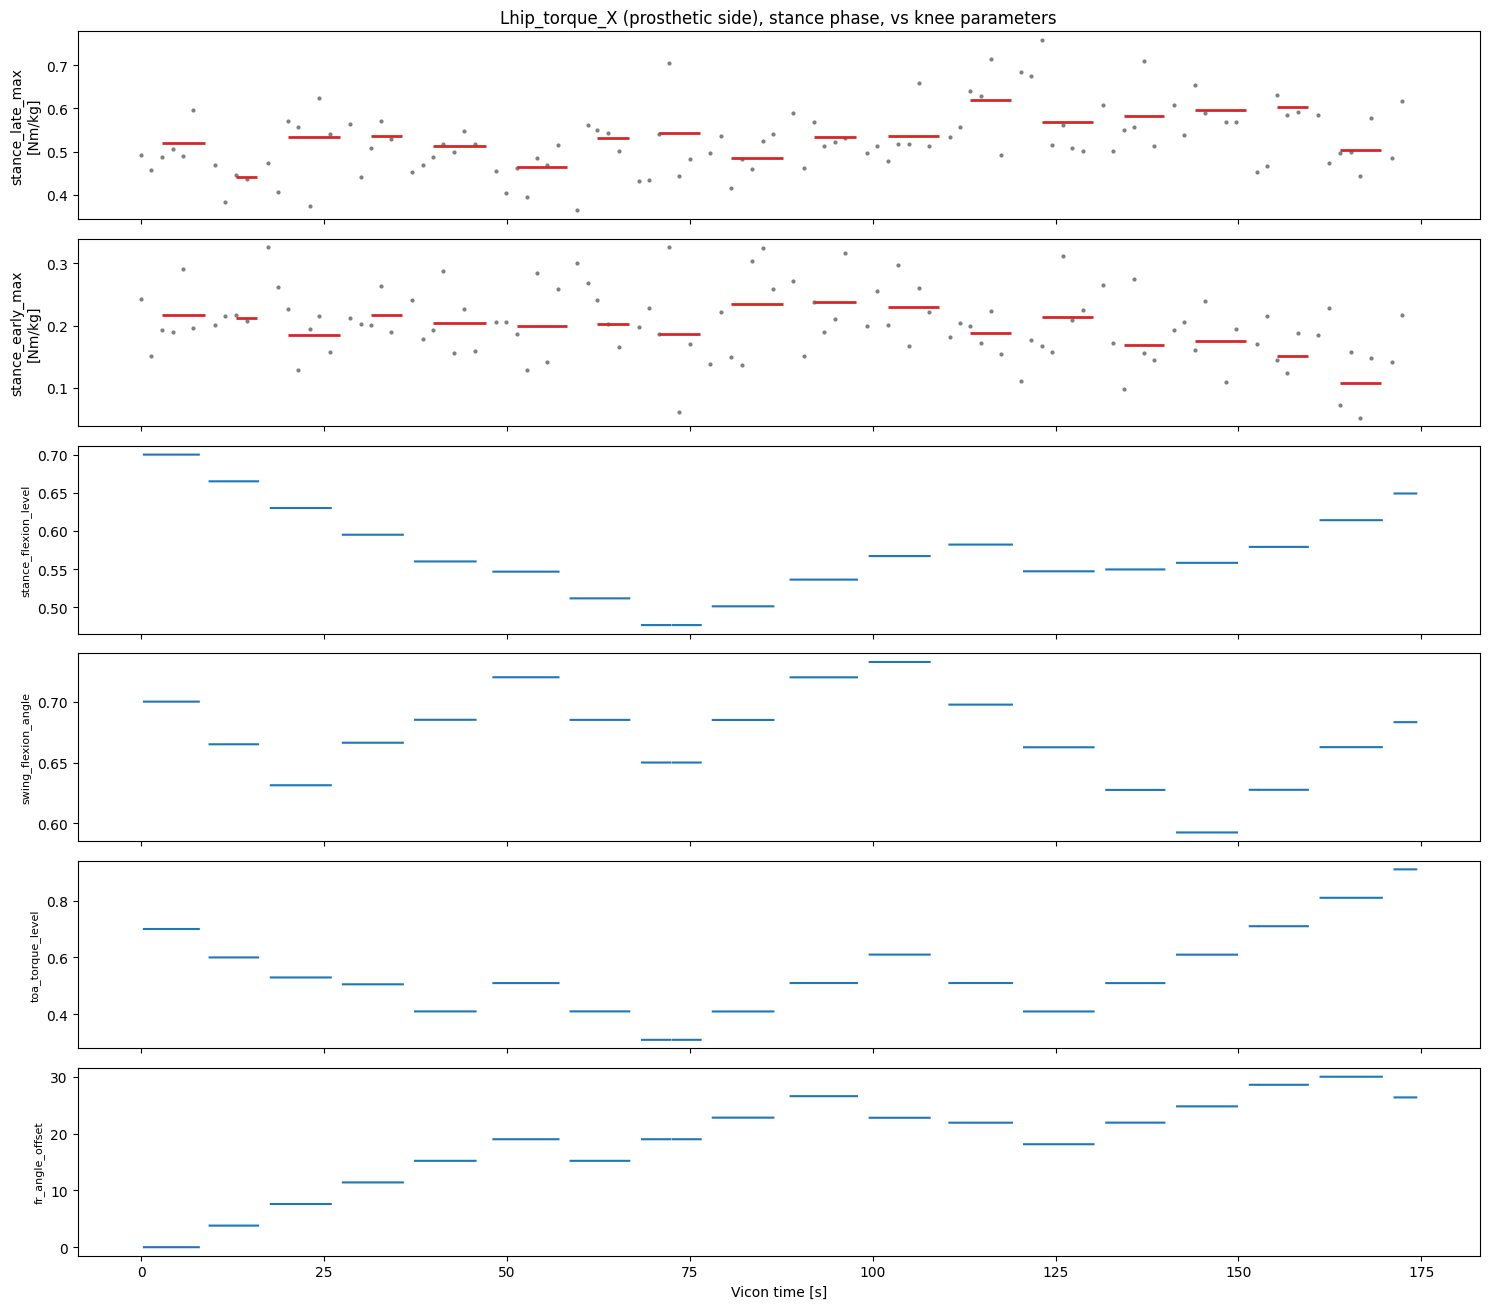

In [155]:
fig, ax = plt.subplots(len(METRICS_ST) + len(PARAMS_VARYING), 1, figsize=(15, 2.2 * (len(METRICS_ST) + len(PARAMS_VARYING))), sharex=True)
for i, mtr in enumerate(METRICS_ST):
    ax[i].plot(cyc_st.t0, cyc_st[mtr], ".", color="gray", ms=4)
    for b, g_ in cyc_st[steady_st].groupby("block"):
        ax[i].hlines(g_[mtr].mean(), g_.t0.min(), g_.t0.max() + g_.stride_s.iloc[-1], color="C3", lw=2)
    ax[i].set_ylabel(f"{mtr}\n[{TORQUE_UNIT}]")
ax[0].set_title(f"{hip_col} (prosthetic side), stance phase, vs knee parameters")
for j, p in enumerate(PARAMS_VARYING):
    a = ax[len(METRICS_ST) + j]
    tt = np.linspace(0, T_VICON, 2000)
    a.step(tt, onboard_at(p, tt, LAG), where="post", color="C0")
    a.set_ylabel(p, fontsize=8)
ax[-1].set_xlabel("Vicon time [s]")
fig.tight_layout(); FIGS["fig4s_timeline_stance"] = fig
plt.show()


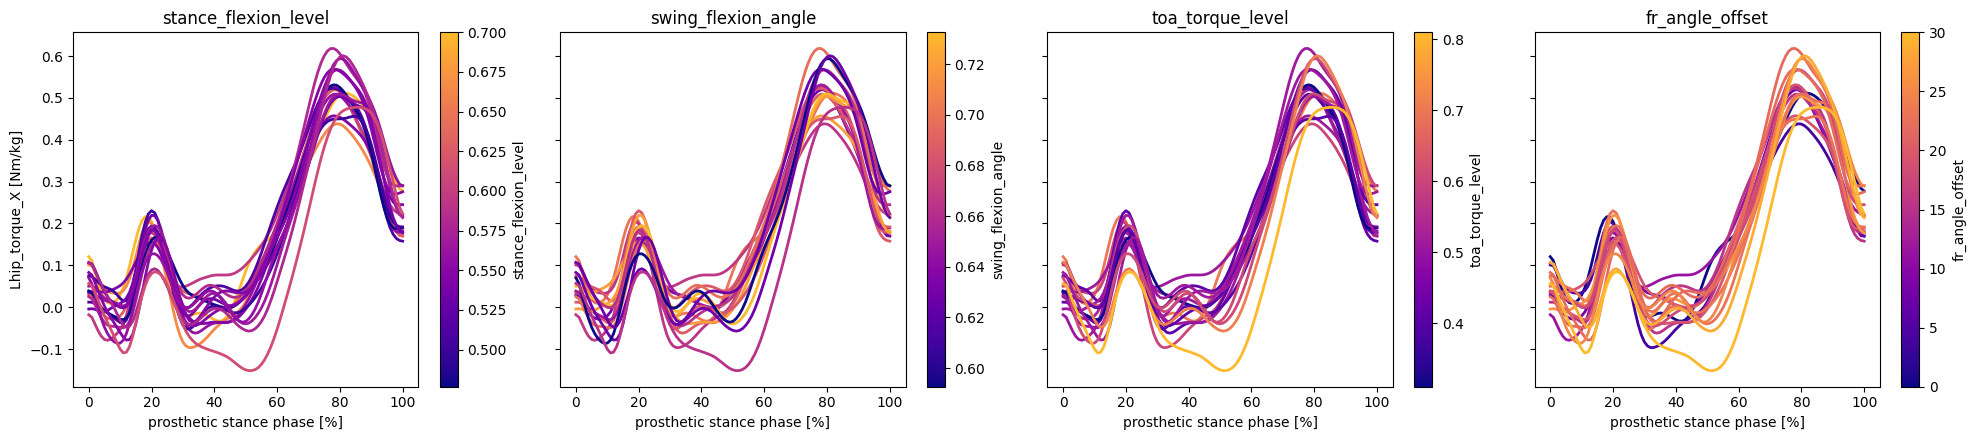

In [156]:
fig, ax = plt.subplots(1, len(PARAMS_VARYING), figsize=(5 * len(PARAMS_VARYING), 4.5), sharey=True)
for a, p in zip(np.atleast_1d(ax), PARAMS_VARYING):
    vals = blk_st[p].to_numpy()
    norm = plt.Normalize(vals.min(), vals.max())
    for c, v in zip(blk_curves_st, vals):
        a.plot(np.arange(101), c, color=CMAP(norm(v)), lw=2)
    fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=CMAP), ax=a, label=p)
    a.set_xlabel("prosthetic stance phase [%]"); a.set_title(p)
np.atleast_1d(ax)[0].set_ylabel(f"{hip_col} [{TORQUE_UNIT}]")
fig.tight_layout(); FIGS["fig5s_profiles_stance"] = fig
plt.show()


## 13. MuJoCo inverse dynamics from the onboard angles
Second, independent estimate of the prosthetic-side swing hip torque, to compare with the Vicon (ground-truth) torque above.

- **Model:** the fixed-hip MuJoCo lower-limb model in `src/modeling` (`get_segment_params` -> `build_lower_limb_model` -> `run_inverse_dynamics`). Inputs are thigh angle, knee angle and ankle = 0; output is the hip torque, divided by body mass to give **Nm/kg**.
- **Onboard inputs:** knee = `ACTUATOR_POSITION`, thigh = `ACTUATOR_POSITION - SHANK_ANGLE` (the repo's `HIP_ANGLE`, `src/utils/utils.py`), both resampled to the Vicon 100 Hz clock with the sync offset `LAG`, low-passed at `ID_LP_HZ` and differentiated twice.
- **Body mass** = mean total vertical force / g (the subject's real mass is not in the file). **Height is an assumption** (`BODY_HEIGHT`), and the segment masses are de Leva values for a sound leg; set `PROSTHESIS_MASS_KG` if you know the shank + foot mass. These change the **scale** of the estimate but not its correlation with Vicon.
- **Reference run:** the same model fed with the *Vicon* angles, so model error and onboard-input error can be told apart.
- **Inputs and sign check:** the onboard and Vicon angles (`ob_thigh`, `ob_knee`, `v_thigh`, `v_knee`) and their agreement are built and checked in section 5d.

In [157]:
import sys
REPO = "/Users/xinyi/Documents/GitHub/ossur_knee"
if REPO not in sys.path:
    sys.path.insert(0, REPO)
from scipy import stats
from scipy.signal import butter, filtfilt
from src.modeling.anthropometrics import get_segment_params
from src.modeling.mujoco_model import build_lower_limb_model
from src.modeling.inverse_dynamics import run_inverse_dynamics

BODY_MASS = float((df["FP1_Z"] + df["FP2_Z"]).dropna().mean() / 9.81)   # kg, from the force plates
BODY_HEIGHT = 1.75          # m, ASSUMPTION
PROSTHESIS_MASS_KG = None   # total shank + foot mass of the prosthesis; None = standard (sound-leg) values
ID_LP_HZ = 4.0              # low-pass before differentiating (see the cut-off sweep below)

segs = get_segment_params(BODY_MASS, BODY_HEIGHT)
if PROSTHESIS_MASS_KG is not None:
    k = PROSTHESIS_MASS_KG / (segs["shank"]["mass"] + segs["foot"]["mass"])
    for s_ in ("shank", "foot"):
        segs[s_]["mass"] *= k
        segs[s_]["I"] *= k
model, mj_data, _ = build_lower_limb_model(segs)
print(f"body mass {BODY_MASS:.1f} kg (from force plates), height {BODY_HEIGHT} m (assumed); "
      f"shank {segs['shank']['mass']:.2f} kg, foot {segs['foot']['mass']:.2f} kg")

body mass 64.8 kg (from force plates), height 1.75 m (assumed); shank 2.81 kg, foot 0.89 kg


In [158]:
def mujoco_hip_torque(thigh_deg, knee_deg, fc=None):
    fc = ID_LP_HZ if fc is None else fc
    b_, a_ = butter(2, fc / (FS_KIN / 2))
    q = np.radians(np.column_stack([filtfilt(b_, a_, thigh_deg), filtfilt(b_, a_, knee_deg), np.zeros(len(knee_deg))]))
    qd = np.gradient(q, 1 / FS_KIN, axis=0)
    qdd = np.gradient(qd, 1 / FS_KIN, axis=0)
    return run_inverse_dynamics(model, mj_data, q, qd, qdd)["tau_hip"] / BODY_MASS   # Nm/kg

def swing_features(sig):
    """Per stride: min over swing, max AFTER the min, and swing curves resampled to 101 points."""
    mn, mx, curves_ = [], [], []
    for t0_, st_, sws_ in zip(cyc.t0, cyc.stride_s, cyc.swing_s):
        t1_ = t0_ + st_
        c = np.interp(np.linspace(t1_ - sws_, t1_, 101), tg, sig)
        i = c.argmin()
        mn.append(c.min()); mx.append(c[i:].max()); curves_.append(c)
    return np.array(mn), np.array(mx), np.array(curves_)

tau_on = mujoco_hip_torque(ob_thigh, ob_knee)       # MuJoCo, onboard angles
tau_vi = mujoco_hip_torque(v_thigh, v_knee)         # MuJoCo, Vicon angles (reference)
cyc["mj_min"], cyc["mj_max"], mj_on_curves = swing_features(tau_on)
cyc["mjv_min"], cyc["mjv_max"], mj_vi_curves = swing_features(tau_vi)
print(f"MuJoCo hip torque computed for {len(cyc)} swings (low-pass {ID_LP_HZ} Hz)")
print(f"mean swing min: Vicon {cyc.swing_peak_min.mean():+.3f}, MuJoCo(onboard) {cyc.mj_min.mean():+.3f}, MuJoCo(Vicon angles) {cyc.mjv_min.mean():+.3f} Nm/kg")

MuJoCo hip torque computed for 105 swings (low-pass 4.0 Hz)
mean swing min: Vicon -0.226, MuJoCo(onboard) -0.440, MuJoCo(Vicon angles) -0.428 Nm/kg


## 14. Figure 7: swing hip-torque profile, MuJoCo vs Vicon
- **Left:** all three on the same axis, so any scale error is visible. Thin lines = individual strides, thick = mean, band = +/- 1 SD.
- **Right:** the three **mean** profiles standardised (zero mean, unit SD over swing) so their **shapes** can be compared regardless of scale.
- 0 % = toe-off, 100 % = next heel strike.

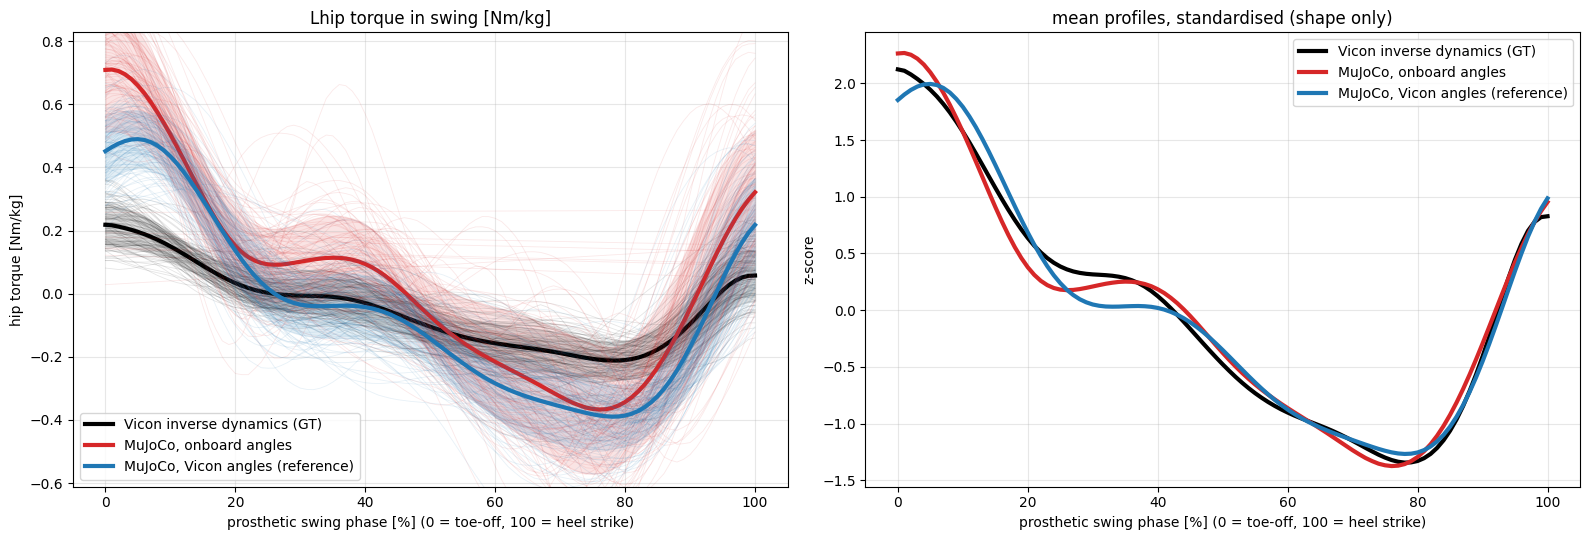

MuJoCo, onboard angles             mean-profile r vs Vicon = +0.99, scale (SD ratio) = 2.4x
MuJoCo, Vicon angles (reference)   mean-profile r vs Vicon = +0.99, scale (SD ratio) = 2.2x


In [159]:
pctx = np.arange(101)
sets = [("Vicon inverse dynamics (GT)", curves, "k"),
        ("MuJoCo, onboard angles", mj_on_curves, "C3"),
        ("MuJoCo, Vicon angles (reference)", mj_vi_curves, "C0")]
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))
for name, c, col in sets:
    ax[0].plot(pctx, c.T, color=col, alpha=0.10, lw=0.6)
    m_, s_ = c.mean(0), c.std(0)
    ax[0].fill_between(pctx, m_ - s_, m_ + s_, color=col, alpha=0.12)
    ax[0].plot(pctx, m_, color=col, lw=3, label=name)
    ax[1].plot(pctx, (m_ - m_.mean()) / m_.std(), color=col, lw=3, label=name)
ax[0].set_ylim(np.percentile(np.concatenate([c.ravel() for _, c, _ in sets]), [0.5, 99.5]))
ax[0].set_title(f"{PROSTHETIC_SIDE}hip torque in swing [{TORQUE_UNIT}]"); ax[0].set_ylabel(f"hip torque [{TORQUE_UNIT}]")
ax[1].set_title("mean profiles, standardised (shape only)"); ax[1].set_ylabel("z-score")
for a in ax:
    a.set_xlabel("prosthetic swing phase [%] (0 = toe-off, 100 = heel strike)"); a.grid(alpha=0.3); a.legend(loc="best")
fig.tight_layout(); FIGS["fig7_mujoco_profiles"] = fig
plt.show()
mv = curves.mean(0)
for name, c, _ in sets[1:]:
    m_ = c.mean(0)
    print(f"{name:34s} mean-profile r vs Vicon = {np.corrcoef(m_, mv)[0, 1]:+.2f}, scale (SD ratio) = {m_.std() / mv.std():.1f}x")

## 15. Figure 8: do the two swing features agree with Vicon?
Features are the same as in section 9: **swing minimum** and **maximum after the minimum** of the swing hip torque.
- **Left column, per stride:** every clean stride is a dot.
- **Right column, per parameter block:** mean over the steady strides of each RL block (this is the level at which the parameter analysis works).
- Colour = time in the trial. `r` is the Pearson correlation; the dashed line is the least-squares fit. Because the estimate has a different scale from Vicon, **only the correlation matters, not how close the points are to the diagonal.**
- The table below also sweeps the low-pass cut-off `ID_LP_HZ`. The default was chosen after seeing this comparison, so treat the best row as slightly optimistic.

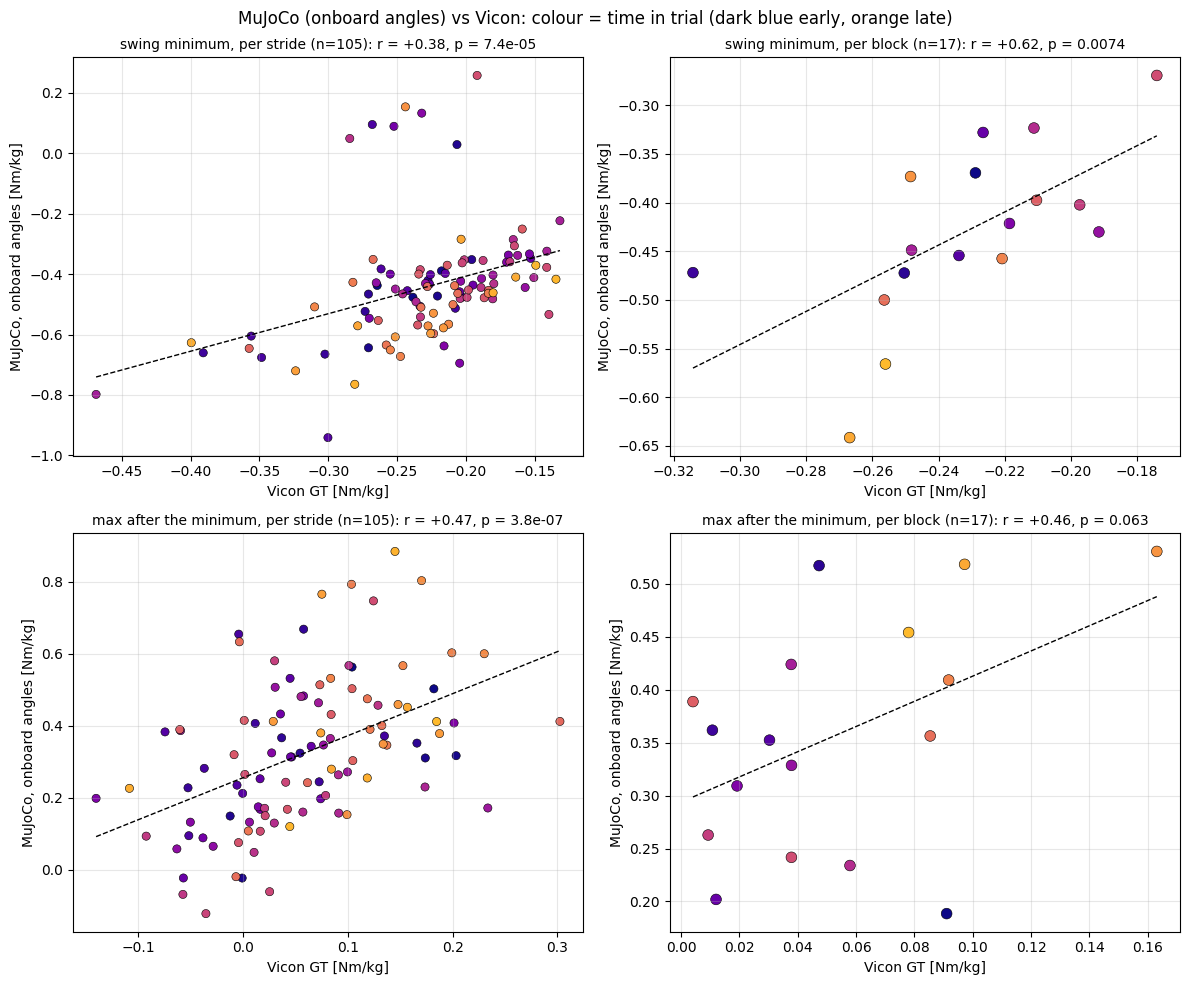

onboard-angle estimate vs Vicon:
              feature      level   n     r     p  slope
        swing minimum per stride 105 0.377 0.000  1.241
        swing minimum  per block  17 0.625 0.007  1.704
max after the minimum per stride 105 0.472 0.000  1.166
max after the minimum  per block  17 0.461 0.063  1.189

reference (MuJoCo fed with Vicon angles):
              feature  stride r (Vicon-angle reference)  block r (Vicon-angle reference)
        swing minimum                              0.77                             0.87
max after the minimum                              0.66                             0.84

low-pass cut-off sweep (onboard angles):


,cutoff_Hz,min: stride r,min: block r,max: stride r,max: block r
0,2,0.36,0.57,0.65,0.74
1,3,0.42,0.64,0.55,0.58
2,4,0.38,0.62,0.47,0.46
3,6,0.27,0.51,0.39,0.32
4,8,0.17,0.40,0.41,0.31


In [160]:
pairs = [("swing minimum", "mj_min", "mjv_min", "swing_peak_min"),
         ("max after the minimum", "mj_max", "mjv_max", "swing_peak_max")]
bk = cyc[steady].groupby("block")
t_blk = bk["t0"].first()
fig, ax = plt.subplots(2, 2, figsize=(12, 10))
rows_ = []
for i, (nm, ec, ecv, vc) in enumerate(pairs):
    for j, level in enumerate(("per stride", "per block")):
        if j == 0:
            x, y, cc = cyc[vc].to_numpy(), cyc[ec].to_numpy(), cyc.t0.to_numpy()
        else:
            x, y, cc = bk[vc].mean().to_numpy(), bk[ec].mean().to_numpy(), t_blk.to_numpy()
        r_, p_ = stats.pearsonr(x, y)
        sl, ic = np.polyfit(x, y, 1)
        a = ax[i, j]
        a.scatter(x, y, c=cc, cmap=CMAP, s=35 if j == 0 else 60, edgecolors="k", linewidths=0.4)
        xx = np.linspace(x.min(), x.max(), 10); a.plot(xx, sl * xx + ic, "k--", lw=1)
        a.set_title(f"{nm}, {level} (n={len(x)}): r = {r_:+.2f}, p = {p_:.2g}", fontsize=10)
        a.set_xlabel(f"Vicon GT [{TORQUE_UNIT}]"); a.set_ylabel(f"MuJoCo, onboard angles [{TORQUE_UNIT}]"); a.grid(alpha=0.3)
        rows_.append({"feature": nm, "level": level, "n": len(x), "r": r_, "p": p_, "slope": sl})
fig.suptitle("MuJoCo (onboard angles) vs Vicon: colour = time in trial (dark blue early, orange late)")
fig.tight_layout(); FIGS["fig8_mujoco_vs_vicon"] = fig
plt.show()

# same comparison for the reference run, and a cut-off sweep for the onboard run
ref = []
for nm, ec, ecv, vc in pairs:
    rs_, _ = stats.pearsonr(cyc[vc], cyc[ecv]); rb_, _ = stats.pearsonr(bk[vc].mean(), bk[ecv].mean())
    ref.append({"feature": nm, "stride r (Vicon-angle reference)": rs_, "block r (Vicon-angle reference)": rb_})
print("onboard-angle estimate vs Vicon:")
print(pd.DataFrame(rows_).round(3).to_string(index=False))
print("\nreference (MuJoCo fed with Vicon angles):")
print(pd.DataFrame(ref).round(2).to_string(index=False))
print("\nlow-pass cut-off sweep (onboard angles):")
sweep = []
for fc in (2, 3, 4, 6, 8):
    mn_, mx_, _ = swing_features(mujoco_hip_torque(ob_thigh, ob_knee, fc))
    d_ = cyc.assign(e_min=mn_, e_max=mx_)[steady].groupby("block")[["e_min", "e_max"]].mean()
    sweep.append({"cutoff_Hz": fc,
                  "min: stride r": stats.pearsonr(mn_, cyc.swing_peak_min)[0], "min: block r": stats.pearsonr(d_.e_min, bk["swing_peak_min"].mean())[0],
                  "max: stride r": stats.pearsonr(mx_, cyc.swing_peak_max)[0], "max: block r": stats.pearsonr(d_.e_max, bk["swing_peak_max"].mean())[0]})
pd.DataFrame(sweep).round(2)

## 16. Figure 9: does the estimate show the same parameter effect as Vicon?
For each feature (rows) and parameter (columns) the block means are standardised (z-score across blocks) so the Vicon (black) and MuJoCo-from-onboard (colour) values share one axis. The title gives the correlation with the parameter for both. If the onboard estimate is a usable substitute for Vicon, the two lines should have the same sign and similar slope.

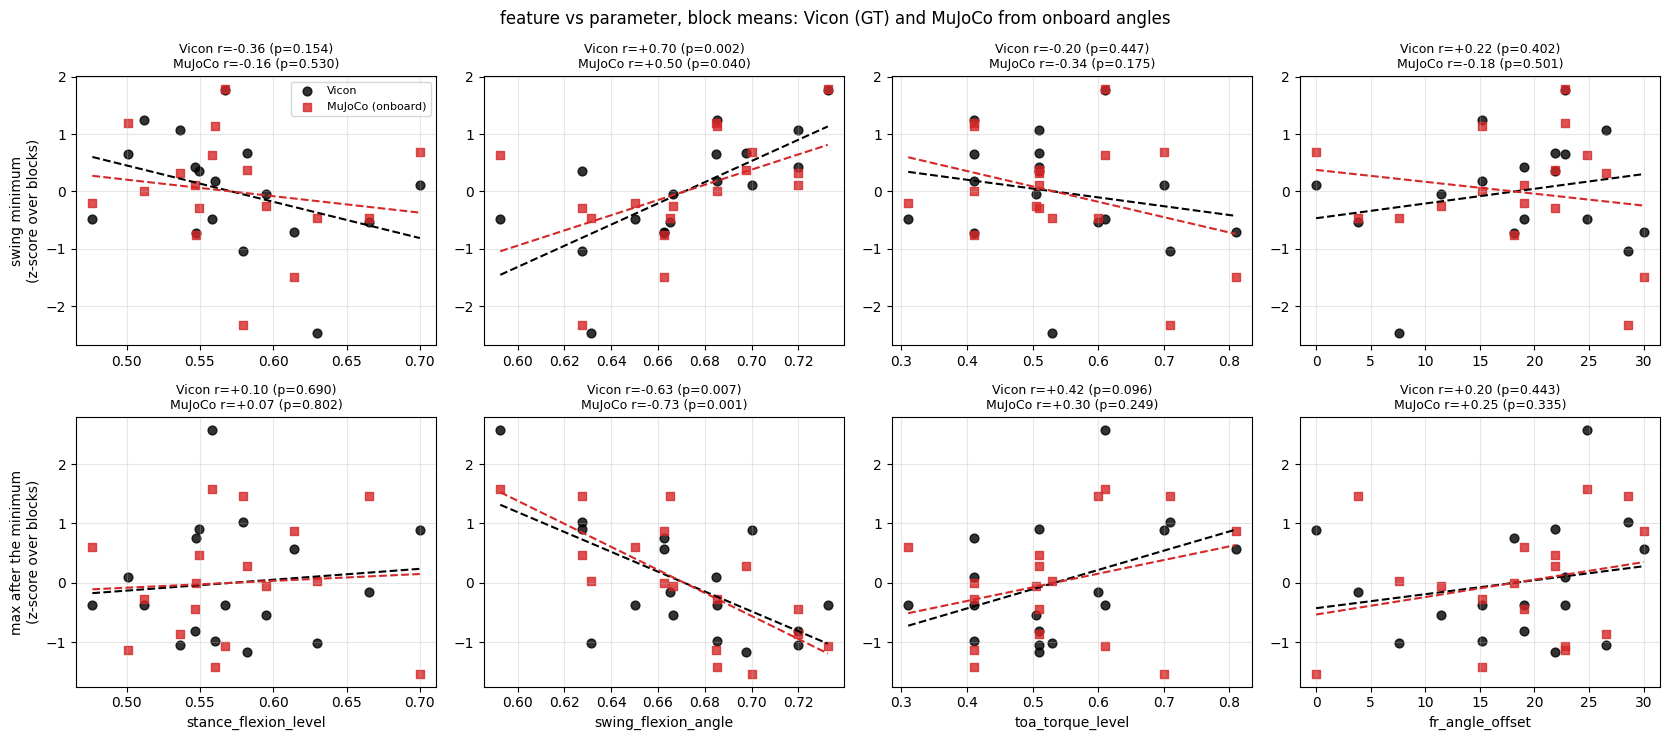

8 tests per source; Bonferroni threshold p < 0.006


,feature,parameter,Vicon r,Vicon p,MuJoCo r,MuJoCo p
0,swing minimum,stance_flexion_level,-0.361,0.154,-0.164,0.530
1,swing minimum,swing_flexion_angle,0.699,0.002,0.501,0.040
2,swing minimum,toa_torque_level,-0.198,0.447,-0.345,0.175
3,swing minimum,fr_angle_offset,0.217,0.402,-0.175,0.501
4,max after the minimum,stance_flexion_level,0.105,0.690,0.066,0.802
5,max after the minimum,swing_flexion_angle,-0.632,0.007,-0.733,0.001
6,max after the minimum,toa_torque_level,0.417,0.096,0.296,0.249
7,max after the minimum,fr_angle_offset,0.199,0.443,0.249,0.335


In [ ]:
fig, ax = plt.subplots(2, len(PARAMS_VARYING), figsize=(4.2 * len(PARAMS_VARYING), 7.5), squeeze=False)
zs_ = lambda s: (s - s.mean()) / s.std()
param_rows = []
for i, (nm, ec, ecv, vc) in enumerate(pairs):
    zv, ze = zs_(bk[vc].mean()), zs_(bk[ec].mean())
    for j, p in enumerate(PARAMS_VARYING):
        a = ax[i, j]; xp = blk[p].loc[zv.index]
        rv, pv = stats.pearsonr(xp, zv); re, pe = stats.pearsonr(xp, ze)
        xx = np.linspace(xp.min(), xp.max(), 10)
        for z_, col, lab, mk in ((zv, "k", "Vicon", "o"), (ze, "C3", "MuJoCo (onboard)", "s")):
            a.scatter(xp, z_, color=col, s=40, marker=mk, alpha=0.8, label=lab)
            k_, b_ = np.polyfit(xp, z_, 1); a.plot(xx, k_ * xx + b_, color=col, lw=1.5, ls="--")
            
        a.set_title(f"Vicon r={rv:+.2f} (p={pv:.3f})\nMuJoCo r={re:+.2f} (p={pe:.3f})", fontsize=9)
        if i == 1: a.set_xlabel(p)
        if j == 0: a.set_ylabel(f"{nm}\n(z-score over blocks)")
        a.grid(alpha=0.3)
        param_rows.append({"feature": nm, "parameter": p, "Vicon r": rv, "Vicon p": pv, "MuJoCo r": re, "MuJoCo p": pe})
ax[0, 0].legend(fontsize=8)
fig.suptitle("feature vs parameter, block means: Vicon (GT) and MuJoCo from onboard angles")
fig.tight_layout(); FIGS["fig9_mujoco_params"] = fig
plt.show()
print("8 tests per source; Bonferroni threshold p < 0.006")
pd.DataFrame(param_rows).round(3)

## 17. Propulsion: anterior-posterior ground reaction force (AP GRF)
**Propulsion** = the maximum *forward* AP force in the second half of stance (push-off). For each stance of each foot (heel strike = vertical force above `FZ_ON`, toe-off = below `FZ_OFF`, 0.4-1.3 s long):
- `prop_peak` = max forward AP force in the 2nd half of stance, `brake_peak` = max backward force in the 1st half;
- `prop_imp`, `brake_imp` = forward and backward impulse (force integrated over time, Ns), `net_imp` = their difference (positive = the foot speeds the body up).
- Only stances during which the knee parameters did **not** change are kept (parameters read from the onboard log at `t + LAG`), and they are grouped into blocks like in section 9.

**Axis and sign:** the plate's `AP_AXIS` (Y) is along the walking direction, and a stance has a backward (braking) phase followed by a forward phase, so **positive = forward**. The cell prints this check (first quarter of stance negative, third quarter positive). Forces are in N; `% BW` uses the body weight from the force plates.

In [162]:
from scipy.integrate import trapezoid
AP_AXIS = "Y"                      # force-plate axis along the walking direction; + = forward (checked below)
MIN_STANCE_S, MAX_STANCE_S = 0.4, 1.3
BW_N = BODY_MASS * 9.81
SOUND_SIDE_FP = RIGHT_FP if PROSTHETIC_SIDE == "L" else LEFT_FP

def stance_ap(fp):
    """One row per clean stance of the foot on plate `fp`, plus the AP force curves (101 points, stance 0-100 %)."""
    _, fz = series(df, f"{fp}_Z")
    _, fy = series(df, f"{fp}_{AP_AXIS}")
    n = min(len(fz), len(fy)); fz, fy = fz[:n], fy[:n]
    hs_i, to_i, loaded = [], [], False
    for i, v in enumerate(fz):
        if not loaded and v > FZ_ON:
            loaded = True; hs_i.append(i)
        elif loaded and v < FZ_OFF:
            loaded = False; to_i.append(i)
    rows, curves_ = [], []
    for a in hs_i:
        nxt = [t_ for t_ in to_i if t_ > a]
        if not nxt or not (MIN_STANCE_S * FS_FP < nxt[0] - a < MAX_STANCE_S * FS_FP):
            continue
        b = nxt[0]
        p0, p1 = params_at(a / FS_FP), params_at(b / FS_FP)
        if not np.allclose(p0[PARAMS].astype(float), p1[PARAMS].astype(float)):
            continue
        y = fy[a:b]; mid = len(y) // 2
        rows.append({"t0": a / FS_FP, "stance_s": (b - a) / FS_FP, "prop_peak": y[mid:].max(), "brake_peak": -y[:mid].min(),
                     "peak_at_pct": 100 * (mid + y[mid:].argmax()) / len(y),
                     "prop_imp": trapezoid(np.clip(y, 0, None), dx=1 / FS_FP), "brake_imp": -trapezoid(np.clip(y, None, 0), dx=1 / FS_FP),
                     "net_imp": trapezoid(y, dx=1 / FS_FP), **{p: float(p0[p]) for p in PARAMS}})
        curves_.append(np.interp(np.linspace(0, len(y) - 1, 101), np.arange(len(y)), y))
    tab = pd.DataFrame(rows)
    tab["block"] = (tab[PARAMS_VARYING].diff().abs().sum(axis=1) > 0).cumsum()
    tab["n_in_block"] = tab.groupby("block").cumcount()
    return tab, np.array(curves_)

AP = {}
for side, fp in ((PROSTHETIC_SIDE, PROSTHETIC_FP), (SOUND_SIDE, SOUND_SIDE_FP)):
    AP[side] = stance_ap(fp)
summ = []
for side, (tab, cv) in AP.items():
    q = len(cv[0]) // 4
    print(f"{side}: {len(tab)} clean stances; sign check: mean AP force, 0-25 % of stance {cv.mean(0)[:q].mean():+.0f} N (braking), 50-75 % {cv.mean(0)[2 * q:3 * q].mean():+.0f} N (propulsion)")
    summ.append({"foot": f"{side} ({'prosthetic' if side == PROSTHETIC_SIDE else 'sound'})", "stances": len(tab),
                 "propulsion peak [N]": f"{tab.prop_peak.mean():.0f} +/- {tab.prop_peak.std():.0f}",
                 "propulsion peak [% BW]": round(100 * tab.prop_peak.mean() / BW_N, 1),
                 "peak at [% stance]": round(tab.peak_at_pct.median()),
                 "braking peak [N]": f"{tab.brake_peak.mean():.0f} +/- {tab.brake_peak.std():.0f}",
                 "propulsive impulse [Ns]": round(tab.prop_imp.mean(), 1), "braking impulse [Ns]": round(tab.brake_imp.mean(), 1),
                 "net impulse [Ns]": round(tab.net_imp.mean(), 1)})
pd.DataFrame(summ).set_index("foot").T

L: 116 clean stances; sign check: mean AP force, 0-25 % of stance -37 N (braking), 50-75 % +10 N (propulsion)
R: 109 clean stances; sign check: mean AP force, 0-25 % of stance -34 N (braking), 50-75 % +12 N (propulsion)


foot,L (prosthetic),R (sound)
stances,116,109
propulsion peak [N],50 +/- 12,107 +/- 15
propulsion peak [% BW],7.9,16.8
peak at [% stance],80,84
braking peak [N],133 +/- 27,80 +/- 20
propulsive impulse [Ns],8.1,22.8
braking impulse [Ns],17.6,15.5
net impulse [Ns],-9.4,7.4


**Figure 10.** (a) AP force over stance, prosthetic vs sound foot (thin = each stance, thick = mean, band = +/- 1 SD; forward positive; dot = median position of the propulsion peak). (b) Mean braking, propulsive and net impulse of each foot: a negative net impulse means the foot, on average, slows the body down.

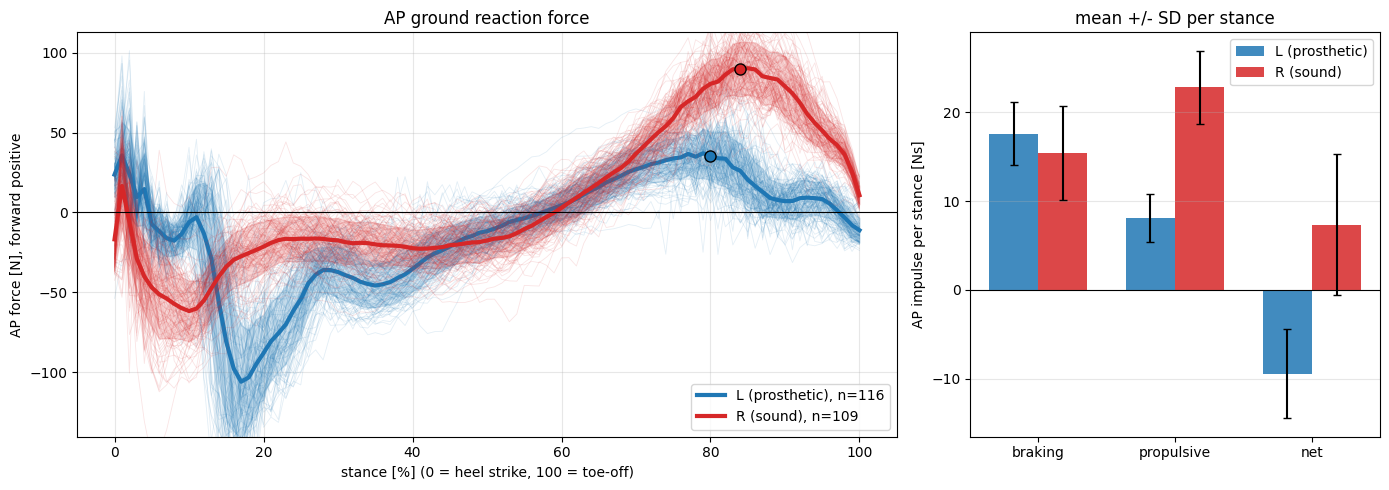

In [163]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2, 1]})
pc = np.arange(101)
lab_ = lambda s: f"{s} ({'prosthetic' if s == PROSTHETIC_SIDE else 'sound'})"
for side in AP:
    cv = AP[side][1]; col = COLORS[side]
    ax[0].plot(pc, cv.T, color=col, alpha=0.12, lw=0.6)
    m_, s_ = cv.mean(0), cv.std(0)
    ax[0].fill_between(pc, m_ - s_, m_ + s_, color=col, alpha=0.18)
    ax[0].plot(pc, m_, color=col, lw=3, label=f"{lab_(side)}, n={len(cv)}")
    pm = int(round(AP[side][0].peak_at_pct.median()))
    ax[0].plot(pm, m_[pm], "o", color=col, mec="k", ms=8, zorder=5)
ax[0].axhline(0, color="k", lw=0.8)
ax[0].set_xlabel("stance [%] (0 = heel strike, 100 = toe-off)"); ax[0].set_ylabel("AP force [N], forward positive")
ax[0].set_ylim(np.percentile(np.concatenate([AP[s][1].ravel() for s in AP]), [0.3, 99.7]))
ax[0].set_title("AP ground reaction force"); ax[0].legend(); ax[0].grid(alpha=0.3)
w_ = 0.36
for i, c_ in enumerate(("brake_imp", "prop_imp", "net_imp")):
    for k_, side in enumerate(AP):
        v_ = AP[side][0][c_]
        ax[1].bar(i + (k_ - 0.5) * w_, v_.mean(), w_, yerr=v_.std(), color=COLORS[side], capsize=3, alpha=0.85,
                  label=lab_(side) if i == 0 else None)
ax[1].set_xticks(range(3), ["braking", "propulsive", "net"]); ax[1].axhline(0, color="k", lw=0.8)
ax[1].set_ylabel("AP impulse per stance [Ns]"); ax[1].set_title("mean +/- SD per stance"); ax[1].legend(); ax[1].grid(alpha=0.3, axis="y")
fig.tight_layout(); FIGS["fig10_ap_force"] = fig
plt.show()

## 18. Propulsion vs knee parameters
Same recipe as section 12: per parameter block, the mean over the steady strides (first `ADAPT_CYCLES` skipped) of `prop_peak` and `prop_imp`, against each parameter. Each correlation comes with checks, because 17 blocks are few:
- **Spearman rho** (rank based, not driven by one extreme block);
- **LOO p max**: the *worst* p-value when each block is left out in turn (a result that depends on one block shows up here);
- **p | time**: p-value of the parameter in a regression that also contains the time in the trial (the parameters drift over the trial, and so could fatigue or adaptation);
- **slope**: change in the feature per unit of the parameter (N per unit for the peak).

A relationship is called **robust** only if all three p-values (Pearson, Spearman, LOO max) are below 0.05. With 2 feet x 2 features x 4 parameters = 16 tests, the Bonferroni threshold is p < 0.003, so even robust ones are leads.

In [164]:
import statsmodels.api as sm
ap_blk, ap_rows = {}, []
for side, (tab, _) in AP.items():
    st_ = tab[tab.n_in_block >= ADAPT_CYCLES]
    b = st_.groupby("block").agg({**{p: "first" for p in PARAMS_VARYING}, "prop_peak": "mean", "prop_imp": "mean", "net_imp": "mean", "t0": "first"})
    ap_blk[side] = b
    for feat in ("prop_peak", "prop_imp"):
        for p in PARAMS_VARYING:
            r_, p_ = stats.pearsonr(b[p], b[feat]); rho, pr_ = stats.spearmanr(b[p], b[feat])
            loo = max(stats.pearsonr(b[p].drop(i), b[feat].drop(i))[1] for i in b.index)
            f_ = sm.OLS(b[feat], sm.add_constant(b[[p, "t0"]])).fit()
            ap_rows.append({"foot": f"{side} ({'prosthetic' if side == PROSTHETIC_SIDE else 'sound'})", "feature": feat, "parameter": p,
                            "n blocks": len(b), "r": r_, "p": p_, "Spearman rho": rho, "Spearman p": pr_, "LOO p max": loo,
                            "p | time": f_.pvalues[p], "slope": np.polyfit(b[p], b[feat], 1)[0],
                            "robust": bool(max(p_, pr_, loo) < 0.05)})
ap_table = pd.DataFrame(ap_rows)
print("time trend of the stance features (block means vs time in trial):")
for side in ap_blk:
    for feat in ("prop_peak", "prop_imp"):
        r_, p_ = stats.pearsonr(ap_blk[side].t0, ap_blk[side][feat])
        print(f"  {side}: {feat} vs time r = {r_:+.2f}, p = {p_:.3f}")
print("\nrelationships with p < 0.1 in any test (all 16 are in ap_table):")
ap_table[(ap_table[["p", "Spearman p"]].min(axis=1) < 0.1)].round(3)

time trend of the stance features (block means vs time in trial):
  L: prop_peak vs time r = -0.22, p = 0.388
  L: prop_imp vs time r = -0.56, p = 0.021
  R: prop_peak vs time r = +0.46, p = 0.064
  R: prop_imp vs time r = +0.43, p = 0.086

relationships with p < 0.1 in any test (all 16 are in ap_table):


,foot,feature,parameter,n blocks,r,p,Spearman rho,Spearman p,LOO p max,p | time,slope,robust
1,L (prosthetic),prop_peak,swing_flexion_angle,17,0.524,0.031,0.456,0.066,0.086,0.054,93.730,False
5,L (prosthetic),prop_imp,swing_flexion_angle,17,0.533,0.028,0.534,0.027,0.076,0.082,20.863,False
10,R (sound),prop_peak,toa_torque_level,17,0.570,0.017,0.434,0.081,0.117,0.039,41.566,False
11,R (sound),prop_peak,fr_angle_offset,17,0.415,0.098,0.519,0.033,0.274,0.947,0.459,False
15,R (sound),prop_imp,fr_angle_offset,17,0.539,0.025,0.658,0.004,0.064,0.145,0.108,False


**Figure 11.** Block-mean propulsion peak (rows: prosthetic and sound foot) against each parameter; colour = time in the trial (dark blue early, orange late), dashed line = least-squares fit. The title gives Pearson r, p and the Spearman p; **bold red** = robust by the criterion above.

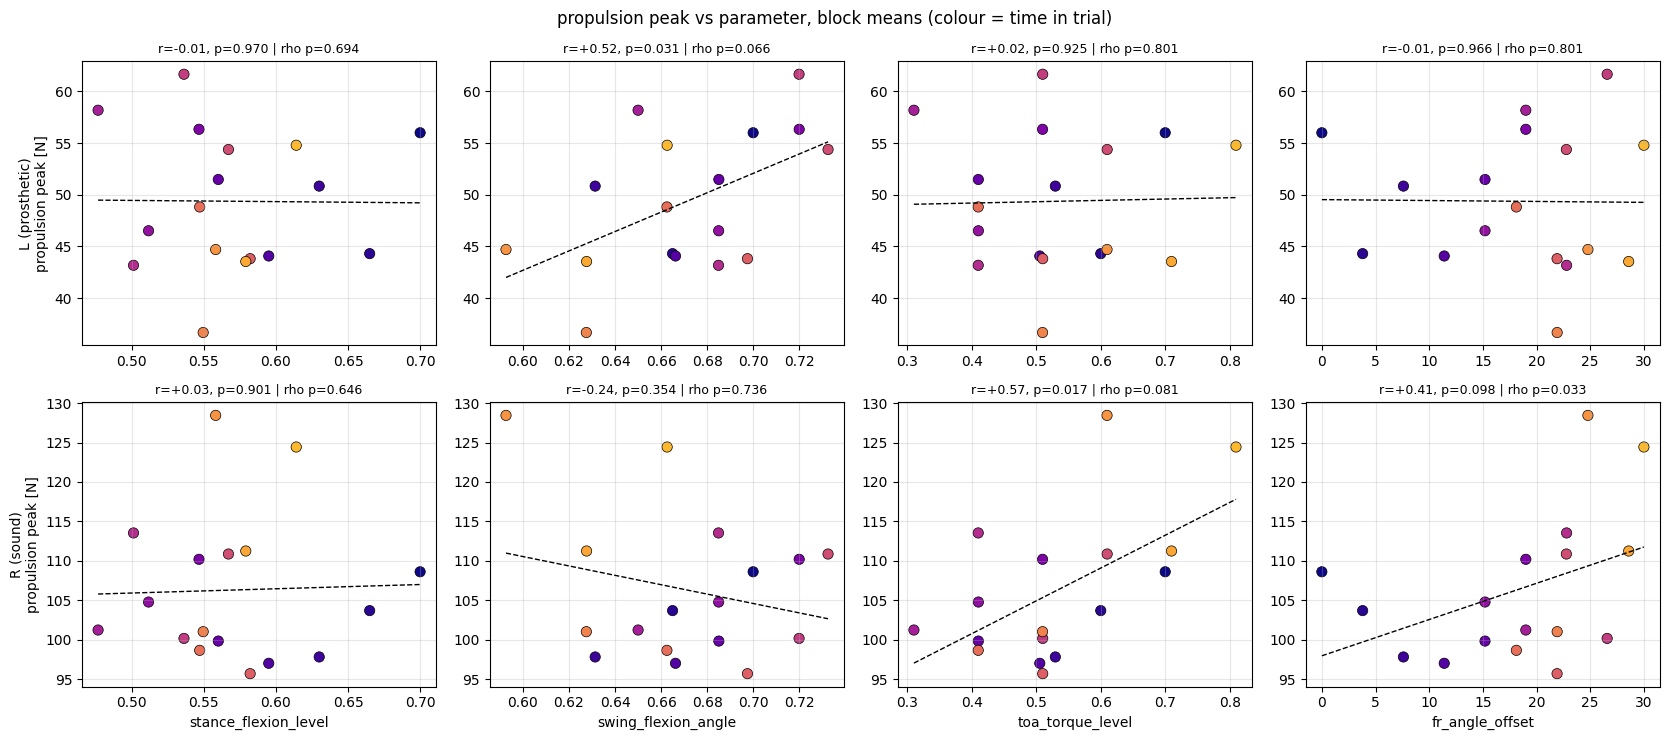

In [165]:
fig, ax = plt.subplots(2, len(PARAMS_VARYING), figsize=(4.2 * len(PARAMS_VARYING), 7.5), squeeze=False)
for i, side in enumerate(ap_blk):
    b = ap_blk[side]
    for j, p in enumerate(PARAMS_VARYING):
        a = ax[i, j]
        a.scatter(b[p], b.prop_peak, c=b.t0, cmap=CMAP, s=55, edgecolors="k", linewidths=0.5)
        k_, c_ = np.polyfit(b[p], b.prop_peak, 1); xx = np.linspace(b[p].min(), b[p].max(), 10)
        a.plot(xx, k_ * xx + c_, "k--", lw=1)
        row = ap_table[(ap_table.foot.str.startswith(side)) & (ap_table.feature == "prop_peak") & (ap_table.parameter == p)].iloc[0]
        a.set_title(f"r={row.r:+.2f}, p={row.p:.3f} | rho p={row['Spearman p']:.3f}", fontsize=9,
                    color="C3" if row.robust else "k", fontweight="bold" if row.robust else "normal")
        if i == 1: a.set_xlabel(p)
        if j == 0: a.set_ylabel(f"{row.foot}\npropulsion peak [N]")
        a.grid(alpha=0.3)
fig.suptitle("propulsion peak vs parameter, block means (colour = time in trial)")
fig.tight_layout(); FIGS["fig11_propulsion_params"] = fig
plt.show()

## 19. Loads, GRF and COP per parameter set (prosthetic foot)
For every prosthetic stride (heel strike to the next heel strike, parameters constant during the stride, same rules as section 9) five signals are resampled to 101 points and averaged over the steady strides of each **parameter set** (block; the first `ADAPT_CYCLES` strides of a block are skipped).
- **Onboard A / P load cell:** `LOADCELL_A1 + LOADCELL_A2` and `LOADCELL_P1 + LOADCELL_P2` from the knee log (raw units, no offset removed), put on the Vicon clock with `LAG`. Strides that touch a logging gap are dropped.
- **Vicon vertical GRF** (`{plate}_Z`, N) and **AP GRF** (`{plate}_Y`, N, forward positive) of the prosthetic plate, over the gait cycle (0 % = heel strike, 100 % = next heel strike).
- **COP in the walking direction (foot frame):** stance only (0 % = heel strike, 100 % = toe-off), the exported `COP_Y` in mm, **the same signal as Figure 2b and section 20**. The export is already in the foot frame (it rises heel to toe by about 0.3 m in every stance, and its Z is at ankle height), so no treadmill term is applied. An earlier version flipped the sign and added `v * (t - t_HS)` as for a lab-frame COP; that gave 0.37 m of travel, more than a foot length, and the curve differed from Figure 2b. Set `COP_IN_FOOT_FRAME = False` to get that conversion back.

**Assumptions:** the exported COP is in the foot frame (not confirmed against the Visual3D model definition). `TREADMILL_SPEED = 0.8` m/s (from `cfg/online_4_params_08_12_default*.jsonc`) is only used when `COP_IN_FOOT_FRAME = False`. The printed check compares the COP travel with one foot length (150-300 mm).

In [166]:
TREADMILL_SPEED = 0.8      # m/s, belt speed (from the RL config; change if trial 09 ran at another speed)
LOAD_CH = {"Onboard A load cell [raw]": ["LOADCELL_A1", "LOADCELL_A2"],
           "Onboard P load cell [raw]": ["LOADCELL_P1", "LOADCELL_P2"]}
COP_IN_FOOT_FRAME = True   # True: the exported COP_Y is already in the foot frame (heel -> toe, as in Figure 2b and section 20): plotted as it is, no belt term.
                           # False: the old conversion (sign flip + treadmill term) that assumed a lab-frame COP; it gives 0.37 m of travel, more than a foot length
COP_FWD_SIGN = -1          # only used when COP_IN_FOOT_FRAME is False
COP_COL = "COP_LFT" if PROSTHETIC_SIDE == "L" else "COP_RFT"
SIG_GC = ["Onboard A load cell [raw]", "Onboard P load cell [raw]", "Vicon vertical GRF [N]", "Vicon AP GRF [N]"]   # gait-cycle signals
SIG_COP = "COP AP, foot frame [mm]" if COP_IN_FOOT_FRAME else "COP AP, overground [mm]"                  # stance signal
SIGNALS = SIG_GC + [SIG_COP]

tf_z, fz_p = series(df, f"{PROSTHETIC_FP}_Z")
tf_y, fy_p = series(df, f"{PROSTHETIC_FP}_{AP_AXIS}")
tc, cy_p = series(df, f"{COP_COL}_Y")

# check: the COP column of the prosthetic foot must be valid exactly while the prosthetic plate is loaded
loaded_at_cop = np.interp(tc, tf_z, fz_p) > FZ_ON
print(f"{COP_COL}: {100 * loaded_at_cop.mean():.0f} % of its valid samples fall while {PROSTHETIC_FP} is loaded (should be ~100)")

rows, S = [], {k: [] for k in SIGNALS}
raw_travel, cor_travel = [], []
for t0, t1 in zip(strikes[PROSTHETIC_SIDE][:-1], strikes[PROSTHETIC_SIDE][1:]):
    if not (MIN_STRIDE_S <= t1 - t0 <= MAX_STRIDE_S):
        continue
    p0, p1 = params_at(t0), params_at(t1)
    if not np.allclose(p0[PARAMS].astype(float), p1[PARAMS].astype(float)):
        continue
    to = toe_off(t0, t1)
    if np.isnan(to) or not (0.4 <= (to - t0) / (t1 - t0) <= 0.8):
        continue
    tg = np.linspace(t0, t1, 101)
    loads = [sum(onboard_at(c, tg, LAG) for c in chs) for chs in LOAD_CH.values()]
    if any(np.isnan(l).any() for l in loads):
        continue                                               # logging gap inside this stride
    ts = np.linspace(t0, to, 101)
    ms = (tc >= t0) & (tc <= to)
    if ms.sum() < 10:
        cop = np.full(101, np.nan)
    else:
        if COP_IN_FOOT_FRAME:
            cop = 1000 * np.interp(ts, tc[ms], cy_p[ms])                          # exported COP, foot frame, mm: absolute position under the foot
            raw_travel.append(cop[-1] - cop[0]); cor_travel.append(cop[-1] - cop[0])
        else:
            raw = COP_FWD_SIGN * np.interp(ts, tc[ms], cy_p[ms])                  # forward-positive lab-frame COP
            cop = 1000 * (raw + TREADMILL_SPEED * (ts - t0))                      # undo the belt: emulated overground
            cop -= cop[0]
            raw_travel.append(1000 * (raw[-1] - raw[0])); cor_travel.append(cop[-1])
    for k, v in zip(SIGNALS, loads + [np.interp(tg, tf_z, fz_p), np.interp(tg, tf_y, fy_p), cop]):
        S[k].append(v)
    rows.append({"t0": t0, "stride_s": t1 - t0, **{p: float(p0[p]) for p in PARAMS_VARYING}})
S = {k: np.array(v) for k, v in S.items()}
st = pd.DataFrame(rows)
st["block"] = (st[PARAMS_VARYING].diff().abs().sum(axis=1) > 0).cumsum()
st["n_in_block"] = st.groupby("block").cumcount()
steady_ld = (st.n_in_block >= ADAPT_CYCLES).to_numpy()
blk_ld = st[steady_ld].groupby("block").agg({**{p: "first" for p in PARAMS_VARYING}, "t0": "first", "stride_s": "count"}).rename(columns={"stride_s": "n_strides"})
BLK_MEAN = {k: np.array([np.nanmean(S[k][(st.block == b).to_numpy() & steady_ld], axis=0) for b in blk_ld.index]) for k in SIGNALS}
BLK_SD = {k: np.array([np.nanstd(S[k][(st.block == b).to_numpy() & steady_ld], axis=0) for b in blk_ld.index]) for k in SIGNALS}
print(f"{len(st)} clean strides, {len(blk_ld)} parameter sets with steady strides")
_trav = np.array(cor_travel)
print(f"COP travel during stance (median, {len(_trav)} strides): {np.median(_trav):.0f} mm, 10-90 %: {np.percentile(_trav, 10):.0f}-{np.percentile(_trav, 90):.0f} mm; "
      f"COP at heel strike {np.median(np.array([c[0] for c in S[SIG_COP] if not np.isnan(c[0])])):.0f} mm, at toe-off {np.median(np.array([c[-1] for c in S[SIG_COP] if not np.isnan(c[-1])])):.0f} mm "
      f"({'exported foot-frame COP' if COP_IN_FOOT_FRAME else 'belt-corrected lab-frame COP'}); expected: one foot length, 150-300 mm: "
      f"{'OK' if 150 <= np.median(_trav) <= 300 else 'CHECK'}")
blk_ld.round(3)

**Figure 15.** Mean curve of each parameter set (one line per set, colour = order in the trial: dark blue early, orange late). Load cells, vertical GRF and AP GRF over the gait cycle; COP over stance.

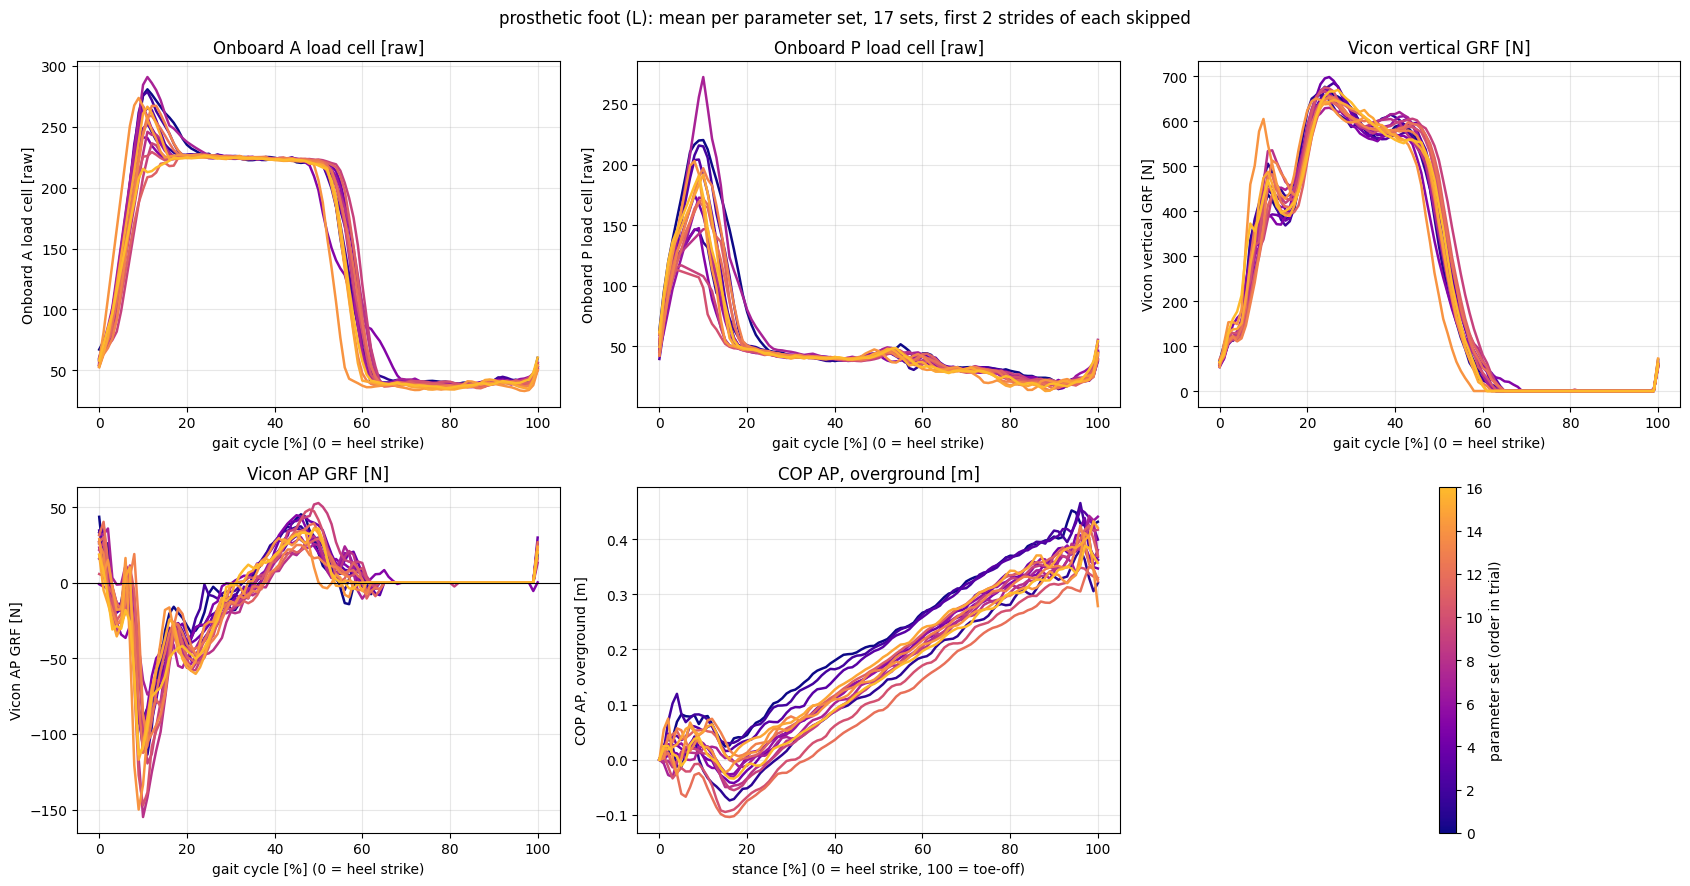

In [167]:
fig, axs = plt.subplots(2, 3, figsize=(17, 9))
axs = axs.ravel()
norm_b = plt.Normalize(0, len(blk_ld) - 1)
xl = {k: (np.arange(101), "gait cycle [%] (0 = heel strike)") for k in SIG_GC}
xl[SIG_COP] = (np.arange(101), "stance [%] (0 = heel strike, 100 = toe-off)")
for a, k in zip(axs, SIGNALS):
    x, xlab = xl[k]
    for i, c in enumerate(BLK_MEAN[k]):
        a.plot(x, c, color=CMAP(norm_b(i)), lw=1.8)
    a.set_xlabel(xlab); a.set_ylabel(k); a.set_title(k); a.grid(alpha=0.3)
    if k == "Vicon AP GRF [N]":
        a.axhline(0, color="k", lw=0.8)
ax_cb = axs[-1]; ax_cb.axis("off")
fig.colorbar(plt.cm.ScalarMappable(norm=norm_b, cmap=CMAP), ax=ax_cb, fraction=0.5, label="parameter set (order in trial)")
fig.suptitle(f"prosthetic foot ({PROSTHETIC_SIDE}): mean per parameter set, {len(blk_ld)} sets, first {ADAPT_CYCLES} strides of each skipped")
fig.tight_layout(); FIGS["fig15_loads_per_block"] = fig
plt.show()

**Figure 15b.** Same block means, one row per signal and one column per knee parameter; the colour is the parameter value of the set, so an ordering of the colours shows an effect of that parameter.

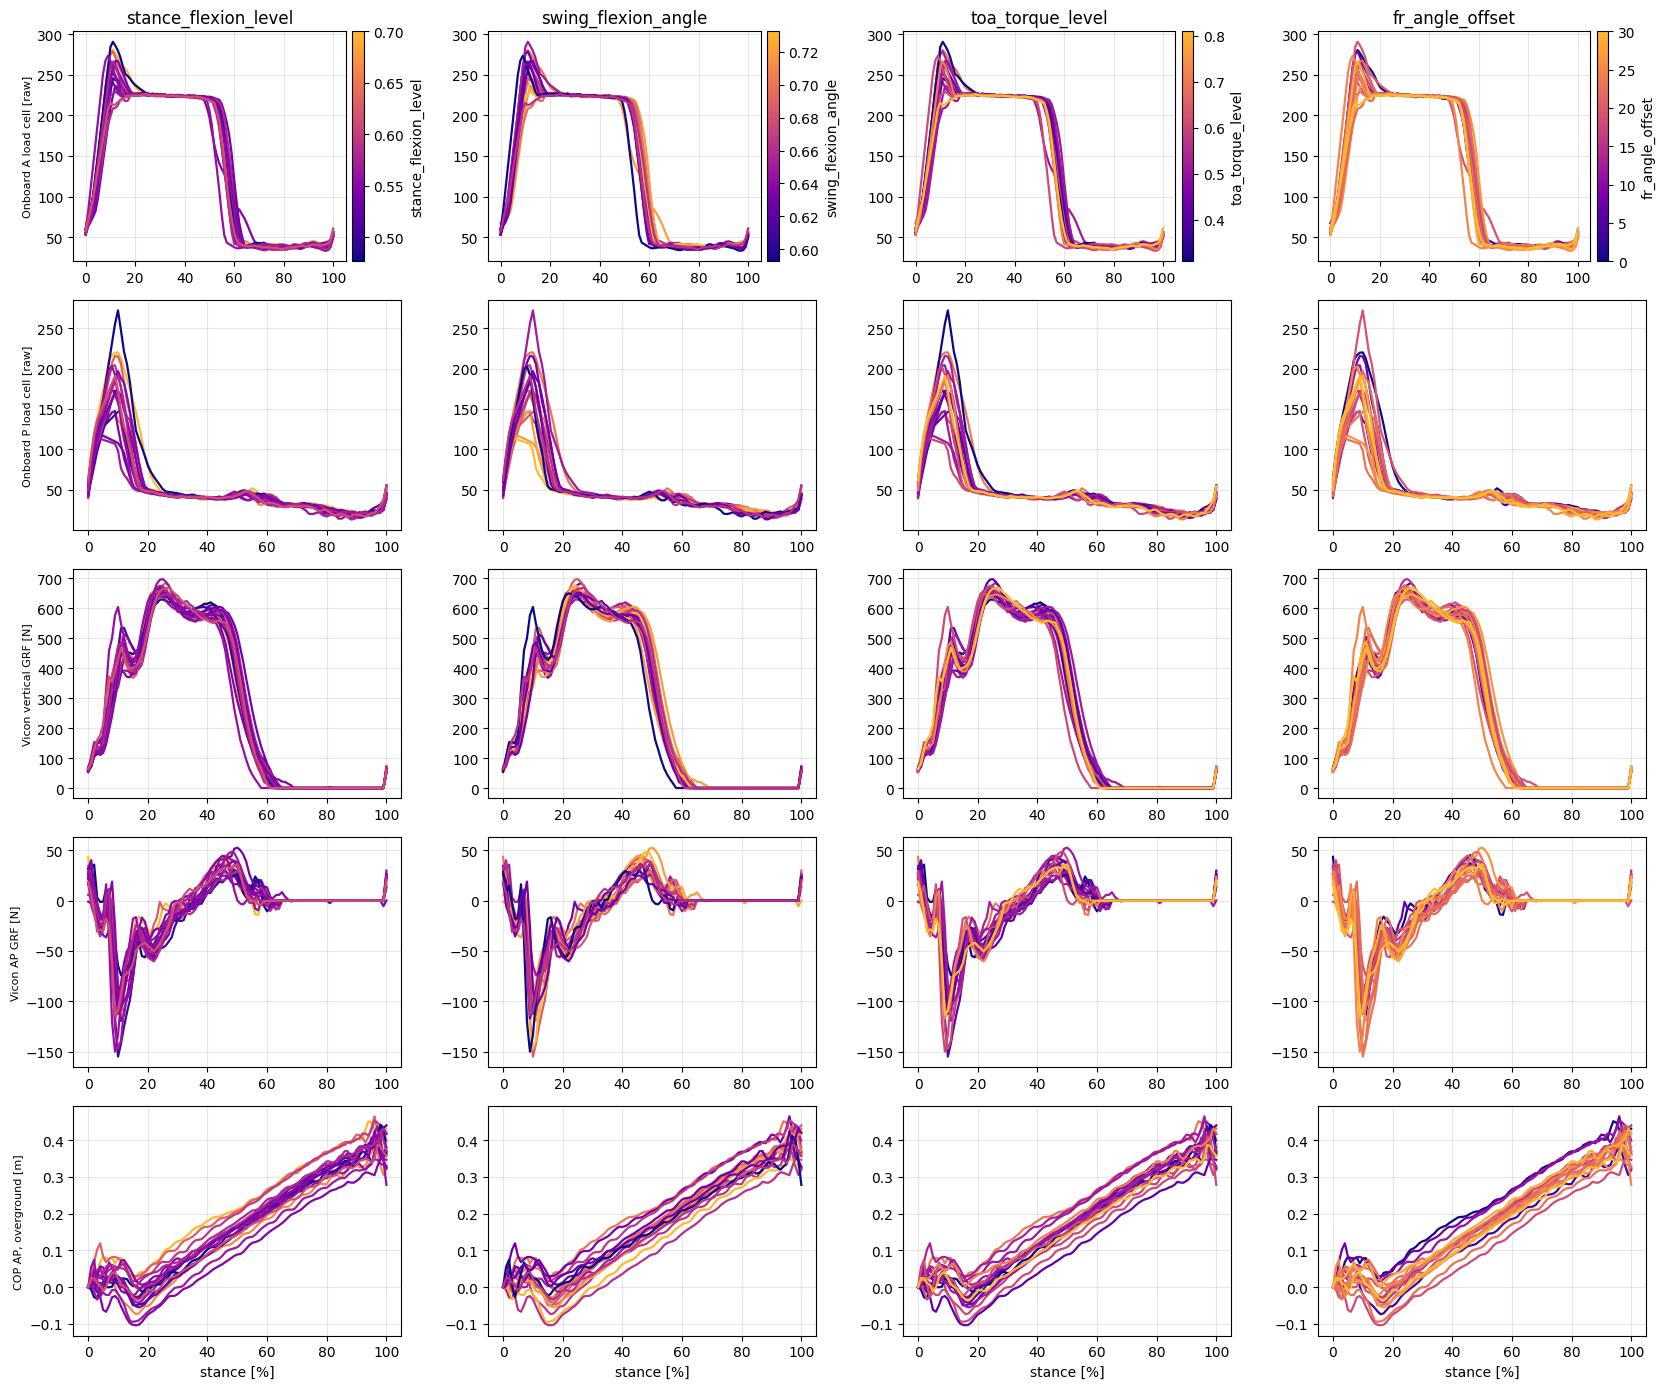

In [168]:
fig, ax = plt.subplots(len(SIGNALS), len(PARAMS_VARYING), figsize=(4.2 * len(PARAMS_VARYING), 2.8 * len(SIGNALS)), squeeze=False, sharex="row")
for i, k in enumerate(SIGNALS):
    for j, p in enumerate(PARAMS_VARYING):
        a = ax[i, j]; vals = blk_ld[p].to_numpy(); nrm = plt.Normalize(vals.min(), vals.max())
        for c, v in zip(BLK_MEAN[k], vals):
            a.plot(np.arange(101), c, color=CMAP(nrm(v)), lw=1.6)
        if j == 0: a.set_ylabel(k, fontsize=8)
        if i == 0:
            a.set_title(p)
            fig.colorbar(plt.cm.ScalarMappable(norm=nrm, cmap=CMAP), ax=a, label=p, pad=0.02)
        if i == len(SIGNALS) - 1:
            a.set_xlabel("stance [%]" if k == SIG_COP else "gait cycle [%]")
        a.grid(alpha=0.3)
fig.tight_layout(); FIGS["fig15b_loads_by_param"] = fig
plt.show()

## 20. COP in the foot frame from the onboard load cells
Can the four load cells (`LOADCELL_A1/A2/P1/P2`) predict the centre of pressure that Vicon measures? **Target:** the exported `COP_LFT` / `COP_RFT` of the prosthetic foot, Y = anterior-posterior (AP, about 0.25 m of travel per stance, heel to toe) and X = mediolateral (ML, about 10 mm SD). The exported COP appears to be in the foot frame already (Z about -0.058 m), so no treadmill correction is applied here.
- **Data:** prosthetic stances with constant parameters, 100 Hz on the Vicon clock; inputs go through `onboard_at`, so stances touching removed or interpolated samples are dropped. The first and last `COP_EDGE_S` (50 ms) of each stance are dropped, where force is low and COP unstable. Load cells are logged raw: each is offset by its median level in swing.
- **Models:** ridge regression (linear, quadratic, with 0-80 ms of load-cell history, and one physics-style moment-ratio feature); a Koopman model (extended DMD with control, written in NumPy, scored as a free rollout over the stance, driven only by the load cells); gradient boosting and a small MLP.
- **Baseline:** gradient boosting on stance phase only. A walking COP moves heel to toe with time, so phase alone already scores high; **only the gain over this baseline says the load cells carry information.**
- **Evaluation:** `stance CV` = 5-fold, whole stances held out; `last 30 %` = train on the first 70 % of the stances, test on the rest (drift check). Phase-based inputs use the toe-off time, which is not known online; the load-cell-only rows are causal apart from the cross-validation.

In [169]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor as GBM
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold

COP_EDGE_S = 0.05          # s dropped at both ends of every stance (COP unstable at low force)
N_LAGS, LAG_STEP = 5, 2    # load-cell history: 5 samples, every 2nd (0-80 ms at 100 Hz)
CV_FOLDS = 5
TIME_SPLIT = 0.7           # time split: train on the first 70 % of the stances, test on the last 30 %
COP_COL = "COP_LFT" if PROSTHETIC_SIDE == "L" else "COP_RFT"   # exported COP of the prosthetic foot (Y = AP, X = ML)
LC = ["LOADCELL_A1", "LOADCELL_A2", "LOADCELL_P1", "LOADCELL_P2"]

# offset of every load cell = its median level in swing (foot unloaded); the cells are logged raw
tgrid = np.arange(N) / FS_KIN
lc_off = {c: float(np.nanmedian(onboard_at(c, tgrid[sw_ok], LAG))) for c in LC}
print("load cell offsets (swing median, raw units):", {k: round(v) for k, v in lc_off.items()})

# dataset: every stance of the prosthetic foot, 100 Hz samples on the Vicon clock
tcx, cx_p = series(df, f"{COP_COL}_X")
tcy, cy_p = series(df, f"{COP_COL}_Y")
rows_d = []
for t0_, t1_ in zip(strikes[PROSTHETIC_SIDE][:-1], strikes[PROSTHETIC_SIDE][1:]):
    if not (MIN_STRIDE_S <= t1_ - t0_ <= MAX_STRIDE_S):
        continue
    p0_, p1_ = params_at(t0_), params_at(t1_)
    if not np.allclose(p0_[PARAMS].astype(float), p1_[PARAMS].astype(float)):
        continue
    to_ = toe_off(t0_, t1_)
    if np.isnan(to_) or not (0.4 <= (to_ - t0_) / (t1_ - t0_) <= 0.8):
        continue
    ts_ = np.arange(np.ceil((t0_ + COP_EDGE_S) * FS_KIN), np.floor((to_ - COP_EDGE_S) * FS_KIN) + 1) / FS_KIN
    if len(ts_) < 20:
        continue
    lcs = [np.column_stack([onboard_at(c, ts_ - k * LAG_STEP / FS_KIN, LAG) - lc_off[c] for c in LC]) for k in range(N_LAGS)]
    kn, sh = onboard_at("ACTUATOR_POSITION", ts_, LAG), onboard_at("SHANK_ANGLE", ts_, LAG + SHANK_DELAY)
    if any(np.isnan(l).any() for l in lcs) or np.isnan(kn).any() or np.isnan(sh).any():
        continue                                                    # logging gap / filtered samples inside this stance
    rows_d.append(dict(n=len(ts_), lc=lcs, knee=kn, shank=sh, t_since=ts_ - t0_, phase=(ts_ - t0_) / (to_ - t0_),
                       cop_y=np.interp(ts_, tcy, cy_p), cop_x=np.interp(ts_, tcx, cx_p), t0=t0_))
print(f"{len(rows_d)} usable stances, {sum(r['n'] for r in rows_d)} samples")
gid = np.concatenate([np.full(r["n"], i) for i, r in enumerate(rows_d)])
cat = lambda key: np.concatenate([r[key] for r in rows_d])
Y_AP, Y_ML = cat("cop_y") * 1000, cat("cop_x") * 1000             # mm
LC0 = np.vstack([r["lc"][0] for r in rows_d])                      # (n, 4) current load cells
LCH = np.hstack([np.vstack([r["lc"][k] for r in rows_d]) for k in range(1, N_LAGS)])   # older samples
A_, P_ = LC0[:, 0] + LC0[:, 1], LC0[:, 2] + LC0[:, 3]
RATIO = (A_ - P_) / np.maximum(np.abs(A_ + P_), 1.0)               # moment-balance style ratio
F_LC = np.column_stack([LC0, A_ - P_, A_ + P_, RATIO])
F_PH = np.column_stack([cat("phase"), cat("t_since")])
F_ANG = np.column_stack([cat("knee"), cat("shank")])


load cell offsets (swing median, raw units): {'LOADCELL_A1': 21, 'LOADCELL_A2': 18, 'LOADCELL_P1': 14, 'LOADCELL_P2': 14}
85 usable stances, 6483 samples


In [172]:
mk_ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0))
mk_poly = lambda: make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(), Ridge(alpha=10.0))
mk_gbm = lambda: GBM(max_iter=200, learning_rate=0.08, max_leaf_nodes=15, random_state=0)
mk_mlp = lambda: make_pipeline(StandardScaler(), MLPRegressor((32, 32), alpha=1e-2, max_iter=400, early_stopping=True, random_state=0))


class EDMD:
    """Koopman model (extended DMD with control) of the COP, the load cells being the input.
    Lift psi(c) = [s, s^2, s^3, sin s, cos s], s = standardised COP. Fit z_{k+1} = A z_k + B u_k + b by ridge least squares on
    consecutive samples of a stance. The reported prediction is the free ROLLOUT over each stance: the state is propagated
    linearly in the lifted space from the training-mean initial COP, driven only by the load cells; COP = readout of z."""
    def __init__(self, order=3, lam=1e-2):
        self.order, self.lam = order, lam
    def _psi(self, c):
        s = (np.asarray(c, float) - self.cm) / self.cs
        return np.column_stack([s ** k for k in range(1, self.order + 1)] + [np.sin(s), np.cos(s)])
    def fit(self, U, c, g):
        self.sc, self.cm, self.cs = StandardScaler().fit(U), c.mean(), c.std()
        Un, Psi = self.sc.transform(U), self._psi(c)
        ok = g[1:] == g[:-1]
        Z, Zn, Uk = Psi[:-1][ok], Psi[1:][ok], Un[:-1][ok]
        G = np.hstack([Z, Uk, np.ones((len(Z), 1))])
        W = np.linalg.solve(G.T @ G + self.lam * len(G) * np.eye(G.shape[1]), G.T @ Zn)
        nz = Z.shape[1]
        self.A, self.B, self.b = W[:nz].T, W[nz:-1].T, W[-1]
        self.Cr = np.linalg.lstsq(Psi, c, rcond=None)[0]
        self.z0 = np.mean([Psi[g == i][0] for i in np.unique(g)], axis=0)
        return self
    def predict(self, U, g):
        Un, out = self.sc.transform(U), np.zeros(len(U))
        for i in np.unique(g):
            z = self.z0.copy()
            for k in np.flatnonzero(g == i):
                z = self.A @ z + self.B @ Un[k] + self.b
                out[k] = z @ self.Cr
        return out


def fit_predict(make, Xtr, ytr, gtr, Xte, gte):
    m = make()
    if isinstance(m, EDMD):
        return m.fit(Xtr, ytr, gtr).predict(Xte, gte)
    return m.fit(Xtr, ytr).predict(Xte)


def cv_predict(make, X, y, g, kind):
    """Predictions for held-out stances: 'group' = 5-fold CV over stances; 'time' = train on the first 70 %, test on the rest."""
    pred = np.full(len(y), np.nan)
    if kind == "group":
        for tr, te in GroupKFold(CV_FOLDS).split(X, y, g):
            pred[te] = fit_predict(make, X[tr], y[tr], g[tr], X[te], g[te])
    else:
        tr = g < int(TIME_SPLIT * len(rows_d)); te = ~tr
        pred[te] = fit_predict(make, X[tr], y[tr], g[tr], X[te], g[te])
    return pred


XH = np.column_stack([F_LC, LCH]) # load cells + history
MODELS = {   # name: (features, factory)
    "baseline: phase only (GBM)": (F_PH, mk_gbm),
    # "Ridge, load cells": (F_LC, mk_ridge),
    # "Ridge, quadratic load cells": (F_LC, mk_poly),
    # "Ridge, load cells + history": (XH, mk_ridge),
    # "Physics: moment ratio only": (F_LC[:, [6]], mk_ridge),
    # "Koopman EDMD (rollout)": (F_LC, EDMD),
    # "GBM, load cells": (F_LC, mk_gbm),
    # "GBM, load cells + history": (XH, mk_gbm),
    "MLP, load cells + history": (XH, mk_mlp),
    # "GBM, load cells + knee/shank": (np.column_stack([F_LC, F_ANG]), mk_gbm),
    # "GBM, load cells + phase": (np.column_stack([F_LC, F_PH]), mk_gbm),
}
rows_r, PRED = [], {}
for tgt, y in (("AP (COP_Y)", Y_AP), ("ML (COP_X)", Y_ML)):
    for nm, (X, make) in MODELS.items():
        for kind, sp in (("group", "stance CV"), ("time", "last 30 %")):
            p = cv_predict(make, X, y, gid, kind)
            ok = ~np.isnan(p)
            rmse = float(np.sqrt(np.mean((p[ok] - y[ok]) ** 2)))
            r2 = 1 - np.sum((p[ok] - y[ok]) ** 2) / np.sum((y[ok] - y[ok].mean()) ** 2)
            rows_r.append({"target": tgt, "model": nm, "split": sp, "RMSE [mm]": rmse, "R2": r2})
            PRED[(tgt, nm, kind)] = p
res20 = pd.DataFrame(rows_r)
print(f"target SD: AP {Y_AP.std():.0f} mm, ML {Y_ML.std():.0f} mm")
res20.pivot_table(index="model", columns=["target", "split"], values=["RMSE [mm]", "R2"], sort=False).round(2)


python(57514) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(57515) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


target SD: AP 59 mm, ML 10 mm


RMSE [mm]                                 \
target                     AP (COP_Y)           ML (COP_X)             
split                       stance CV last 30 %  stance CV last 30 %   
model                                                                  
baseline: phase only (GBM)      16.21     16.21       6.30      6.41   
MLP, load cells + history       14.34     13.39       6.07      6.87   

                                   R2                                 
target                     AP (COP_Y)           ML (COP_X)            
split                       stance CV last 30 %  stance CV last 30 %  
model                                                                 
baseline: phase only (GBM)       0.93      0.93       0.63      0.62  
MLP, load cells + history        0.94      0.95       0.65      0.56

KeyError: ('AP (COP_Y)', 'GBM, load cells + history', 'group')

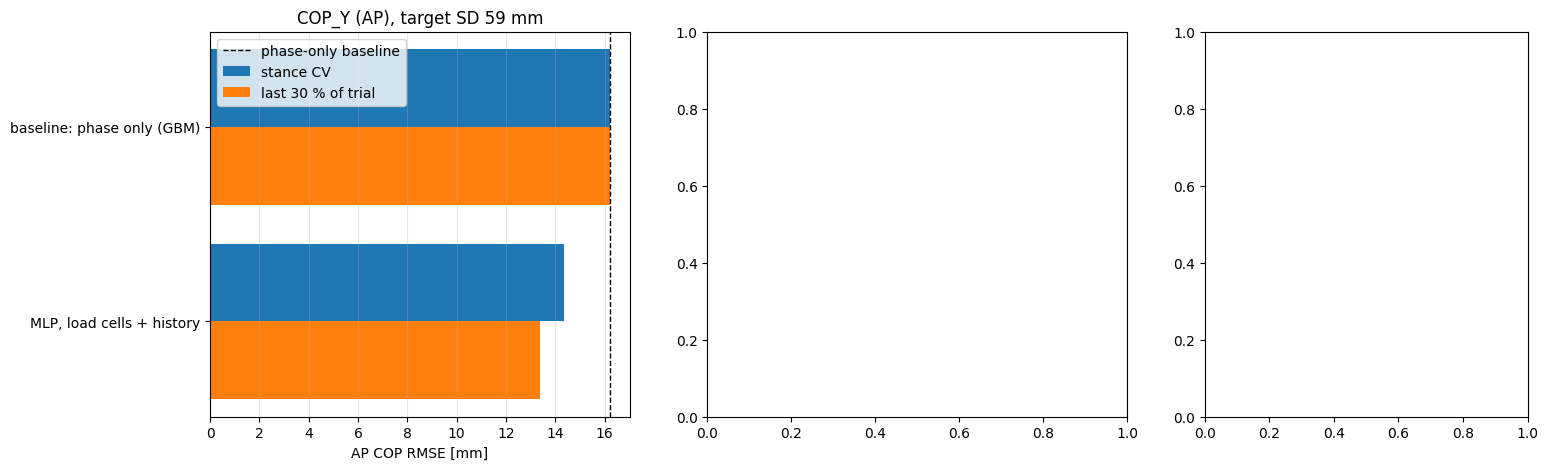

In [174]:
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.3, 1.3, 1]})
base_ap = res20[(res20.target == "AP (COP_Y)") & (res20.model.str.startswith("baseline")) & (res20.split == "stance CV")]["RMSE [mm]"].iloc[0]
for a, tgt in zip(ax[:1], ["AP (COP_Y)"]):
    d = res20[(res20.target == tgt)].pivot(index="model", columns="split", values="RMSE [mm]").loc[list(MODELS)]
    yy = np.arange(len(d))
    a.barh(yy - 0.2, d["stance CV"], 0.4, label="stance CV", color="C0")
    a.barh(yy + 0.2, d["last 30 %"], 0.4, label="last 30 % of trial", color="C1")
    a.axvline(base_ap, color="k", ls="--", lw=1, label="phase-only baseline")
    a.set_yticks(yy, d.index); a.invert_yaxis(); a.set_xlabel("AP COP RMSE [mm]"); a.legend(); a.grid(alpha=0.3, axis="x")
    a.set_title(f"COP_Y (AP), target SD {Y_AP.std():.0f} mm")
best_nm = "GBM, load cells + history"
p_best = PRED[("AP (COP_Y)", best_nm, "group")]
pick = np.linspace(0, len(rows_d) - 1, 6).astype(int)
cols_ = plt.cm.tab10(np.arange(6))
for c_, i in zip(cols_, pick):
    m = gid == i; x = np.arange(m.sum()) / FS_KIN * 1000
    ax[1].plot(x, Y_AP[m], color=c_, lw=2); ax[1].plot(x, p_best[m], color=c_, lw=1.5, ls="--")
ax[1].set_xlabel("time since first usable sample of the stance [ms]"); ax[1].set_ylabel("COP_Y [mm]")
ax[1].set_title(f"6 stances: measured (solid) vs {best_nm} (dashed)"); ax[1].grid(alpha=0.3)
ax[2].scatter(Y_AP, p_best, s=4, alpha=0.3)
lim = [Y_AP.min(), Y_AP.max()]; ax[2].plot(lim, lim, "k--", lw=1)
ax[2].set_xlabel("measured COP_Y [mm]"); ax[2].set_ylabel("predicted [mm]"); ax[2].set_title("stance CV, all samples"); ax[2].grid(alpha=0.3)
fig.tight_layout(); FIGS["fig16_cop_from_loadcells"] = fig
plt.show()


## 20b. Stance hip torque from the onboard load cells and knee / shank angles
Same idea as the swing estimate (section 13) and the COP fit (section 20), for the **prosthetic stance** (heel strike to toe-off, same stride filters as section 12b). **Target:** the Vicon hip inverse-dynamics torque (6 Hz low-pass `yh`), Nm/kg.
- **Why MuJoCo alone cannot work in stance:** the fixed-hip model has no ground reaction force, so in stance it only sees the leg's own inertia and gravity. It is reported as `MuJoCo, no ground force` (raw) and with a fitted gain / offset, to show this.
- **Inputs:** the four load cells (swing offset removed) plus A - P and A + P; knee, shank and thigh angle with their velocity and acceleration (4 Hz low-pass); load-cell history (0-80 ms); the MuJoCo torque as an extra feature (hybrid); the **knee torque reading**, the firmware's `TORQUE_ESTIMATE` (it correlates r = 0.92 with the Vicon knee torque over the prosthetic stance), alone and added to the load cells and angles.
- **Methods:** ridge (linear, quadratic, with history), gradient boosting, a small MLP. Koopman is not repeated: it did not beat the other methods in section 20 and needs a state to roll out.
- **Baseline:** gradient boosting on stance phase only (needs the toe-off time, so it is not available online). A stance torque is mostly a function of phase, so **only the gain over this baseline says the load cells or angles carry information.**
- **Evaluation:** stride CV = 5-fold with whole strides held out; last 30 % = train on the first 70 % of the strides. The second part checks the two stance features of section 12b (early max, late max) on the held-out estimates, per stride and per parameter block.

In [175]:
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor as GBM
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupKFold
from scipy.signal import butter, filtfilt

CV_FOLDS, TIME_SPLIT = 5, 0.7          # as in section 20: 5-fold over strides; train on the first 70 % of the strides, test on the rest
HIST_N, HIST_STEP = 5, 2               # load-cell history: 5 samples, every 2nd (0-80 ms)
LC = ["LOADCELL_A1", "LOADCELL_A2", "LOADCELL_P1", "LOADCELL_P2"]

# --- inputs on the 100 Hz Vicon grid: load cells (swing offset removed), knee / shank / thigh angle, their velocity / acceleration, MuJoCo torque
tgrid = np.arange(N) / FS_KIN
lc_off = {c: float(np.nanmedian(onboard_at(c, tgrid[sw_ok], LAG))) for c in LC}
lc_full = np.column_stack([onboard_at(c, tgrid, LAG) - lc_off[c] for c in LC])
lc_hist = np.column_stack([np.column_stack([onboard_at(c, tgrid - k * HIST_STEP / FS_KIN, LAG) - lc_off[c] for c in LC]) for k in range(1, HIST_N)])
b4, a4 = butter(2, 4.0 / (FS_KIN / 2))
vel_ = lambda x: np.gradient(filtfilt(b4, a4, x), 1 / FS_KIN)
ang_full = np.column_stack([ob_knee, ob_shank, ob_thigh, vel_(ob_knee), vel_(ob_shank), vel_(ob_thigh),
                            vel_(vel_(ob_knee)), vel_(vel_(ob_thigh))])   # angles [deg], velocities [deg/s], accelerations [deg/s^2]
tq_full = onboard_at("TORQUE_ESTIMATE", tgrid, LAG)                      # onboard knee torque estimate (firmware), a reading of the knee torque
mj_full = tau_on                                                          # MuJoCo hip torque from the onboard angles (section 13), Nm/kg, no ground force
hip_full = np.full(N, np.nan)                                             # Vicon hip ID torque (6 Hz low-pass `yh`) on the same grid
ii = np.round(th * FS_KIN).astype(int); k_ = ii < N
hip_full[ii[k_]] = yh[k_]

# --- stance samples of every prosthetic stride (heel strike -> toe-off), same stride filters as section 9 / 12b
parts, meta = [], []
for t0, t1 in zip(hs[:-1], hs[1:]):
    if not (MIN_STRIDE_S <= t1 - t0 <= MAX_STRIDE_S):
        continue
    p0, p1 = params_at(t0), params_at(t1)
    if not np.allclose(p0[PARAMS].astype(float), p1[PARAMS].astype(float)):
        continue
    to = toe_off(t0, t1)
    if np.isnan(to) or not (0.4 <= (to - t0) / (t1 - t0) <= 0.8):
        continue
    idx = np.arange(int(np.ceil(t0 * FS_KIN)), int(np.floor(to * FS_KIN)) + 1)
    if idx[-1] >= N or len(idx) < 20 or not valid[idx].all():
        continue                                                        # logging gap / filtered samples inside this stance
    if np.isnan(lc_full[idx]).any() or np.isnan(lc_hist[idx]).any() or np.isnan(hip_full[idx]).any() or np.isnan(tq_full[idx]).any():
        continue
    parts.append(idx)
    meta.append({"t0": t0, "stance_s": to - t0, **{p: float(p0[p]) for p in PARAMS_VARYING}})
meta = pd.DataFrame(meta)
meta["block"] = (meta[PARAMS_VARYING].diff().abs().sum(axis=1) > 0).cumsum()
meta["n_in_block"] = meta.groupby("block").cumcount()
gid_s = np.concatenate([np.full(len(ix), i) for i, ix in enumerate(parts)])
IDX = np.concatenate(parts)
t_in = np.concatenate([(ix - ix[0]) / FS_KIN for ix in parts])
ph_in = np.concatenate([(ix - ix[0]) / (ix[-1] - ix[0]) for ix in parts])
Y_H = hip_full[IDX]                                                     # target, Nm/kg
A_, P_ = lc_full[IDX, 0] + lc_full[IDX, 1], lc_full[IDX, 2] + lc_full[IDX, 3]
F_LC_S = np.column_stack([lc_full[IDX], A_ - P_, A_ + P_])
F_ANG_S = ang_full[IDX]
F_HIST_S = lc_hist[IDX]
F_PH_S = np.column_stack([ph_in, t_in])
F_MJ_S = mj_full[IDX][:, None]
F_KT_S = tq_full[IDX][:, None]                                          # knee torque reading
print(f"{len(parts)} usable stances, {len(IDX)} samples (hip torque SD {Y_H.std():.2f} Nm/kg); load-cell offsets {({k: round(v) for k, v in lc_off.items()})}")


In [ ]:
mk_ridge = lambda: make_pipeline(StandardScaler(), Ridge(alpha=1.0))
mk_poly = lambda: make_pipeline(StandardScaler(), PolynomialFeatures(2), StandardScaler(), Ridge(alpha=10.0))
mk_gbm = lambda: GBM(max_iter=200, learning_rate=0.08, max_leaf_nodes=15, random_state=0)
mk_mlp = lambda: make_pipeline(StandardScaler(), MLPRegressor((32, 32), alpha=1e-2, max_iter=400, early_stopping=True, random_state=0))

def cv_pred_s(make, X, y, g, kind):
    """Held-out predictions: 'group' = 5-fold over strides, 'time' = train on the first 70 % of the strides, test on the rest."""
    pred = np.full(len(y), np.nan)
    if kind == "group":
        for tr, te in GroupKFold(CV_FOLDS).split(X, y, g):
            pred[te] = make().fit(X[tr], y[tr]).predict(X[te])
    else:
        tr = g < int(TIME_SPLIT * len(parts)); te = ~tr
        pred[te] = make().fit(X[tr], y[tr]).predict(X[te])
    return pred

F_ALL = np.column_stack([F_LC_S, F_ANG_S])
F_ALLK = np.column_stack([F_ALL, F_KT_S])                                  # load cells + angles + knee torque reading
MODELS_S = {   # name: (features, factory); None = no fitting, the MuJoCo torque itself
    # "MuJoCo, no ground force": (None, None),
    # "MuJoCo + gain / offset (ridge)": (F_MJ_S, mk_ridge),
    "baseline: stance phase only (GBM)": (F_PH_S, mk_gbm),
    "Ridge, load cells": (F_LC_S, mk_ridge),
    "Ridge, angles (knee/shank/thigh)": (F_ANG_S, mk_ridge),
    "Ridge, load cells + angles": (F_ALL, mk_ridge),
    "Ridge, quadratic, load cells + angles": (F_ALL, mk_poly),
    "Ridge, load cells + history + angles": (np.column_stack([F_ALL, F_HIST_S]), mk_ridge),
    "GBM, load cells": (F_LC_S, mk_gbm),
    "GBM, angles": (F_ANG_S, mk_gbm),
    "GBM, load cells + angles": (F_ALL, mk_gbm),
    "GBM, load cells + angles + MuJoCo": (np.column_stack([F_ALL, F_MJ_S]), mk_gbm),
    "Ridge, knee torque only": (F_KT_S, mk_ridge),
    "GBM, knee torque only": (F_KT_S, mk_gbm),
    "GBM, angles + knee torque": (np.column_stack([F_ANG_S, F_KT_S]), mk_gbm),
    "Ridge, quadratic, load cells + angles + knee torque": (F_ALLK, mk_poly),
    "GBM, load cells + angles + knee torque": (F_ALLK, mk_gbm),
    "MLP, load cells + angles + history": (np.column_stack([F_ALL, F_HIST_S]), mk_mlp),
}
rows_s2, PRED_S = [], {}
for nm, (X, make) in MODELS_S.items():
    for kind, sp in (("group", "stride CV"), ("time", "last 30 %")):
        if X is None:
            p = mj_full[IDX].copy()
            if kind == "time":
                p[gid_s < int(TIME_SPLIT * len(parts))] = np.nan
        else:
            p = cv_pred_s(make, X, Y_H, gid_s, kind)
        ok = ~np.isnan(p)
        rmse = float(np.sqrt(np.mean((p[ok] - Y_H[ok]) ** 2)))
        rows_s2.append({"model": nm, "split": sp, "RMSE [Nm/kg]": rmse, "R2": 1 - np.sum((p[ok] - Y_H[ok]) ** 2) / np.sum((Y_H[ok] - Y_H[ok].mean()) ** 2),
                        "r": np.corrcoef(p[ok], Y_H[ok])[0, 1]})
        PRED_S[(nm, kind)] = p
res_st = pd.DataFrame(rows_s2)
print(f"target SD {Y_H.std():.2f} Nm/kg")
res_st.pivot_table(index="model", columns="split", values=["RMSE [Nm/kg]", "R2", "r"], sort=False).round(2)


In [ ]:
# Do the estimates follow the stride-to-stride and block-to-block changes of the two stance features (as in sections 12b / 15)?
# Per stride: early max (first half of stance) and late max (second half), measured on the held-out predictions of each model.
def stance_feats(sig):
    out = []
    for i in range(len(parts)):
        c = np.interp(np.linspace(0, 1, 101), ph_in[gid_s == i], sig[gid_s == i])
        out.append((c[:50].max(), c[50:].max()))
    return np.array(out)
truth = stance_feats(Y_H)
steady_s = (meta.n_in_block >= ADAPT_CYCLES).to_numpy()
cmp_models = ["baseline: stance phase only (GBM)", "Ridge, quadratic, load cells + angles", "GBM, angles", "GBM, load cells + angles", "MLP, load cells + angles + history",
              "GBM, knee torque only", "GBM, angles + knee torque", "Ridge, quadratic, load cells + angles + knee torque", "GBM, load cells + angles + knee torque"]
rows_f = []
for nm in cmp_models:
    est = stance_feats(PRED_S[(nm, "group")])
    for j, fname in enumerate(("early max (loading)", "late max (push-off)")):
        rs_ = stats.pearsonr(truth[:, j], est[:, j])[0]
        tb = pd.Series(truth[steady_s, j]).groupby(meta.block[steady_s].to_numpy()).mean()
        eb = pd.Series(est[steady_s, j]).groupby(meta.block[steady_s].to_numpy()).mean()
        rows_f.append({"model": nm, "feature": fname, "stride r": rs_, "block r": stats.pearsonr(tb, eb)[0],
                       "mean error [Nm/kg]": float(np.mean(est[:, j] - truth[:, j])), "RMSE [Nm/kg]": float(np.sqrt(np.mean((est[:, j] - truth[:, j]) ** 2)))})
feat_table = pd.DataFrame(rows_f)
print("agreement of the stance features with Vicon, held-out strides (stride = every stride, block = mean of the steady strides of each parameter block):")
print(feat_table.round(2).to_string(index=False))




### 20c. Does the parameter effect on the stance peaks survive the reconstruction from onboard sensing?
The two stance features of section 12b (early max = loading response, late max = push-off) are computed from **Vicon** and from the **reconstructed** hip torque, and each is correlated with every varying parameter over the parameter blocks, as in section 12 / 16.
- **Two ways to hold data out.** `stride CV` is the estimate of section 20b: other strides of the same parameter block can be in the training set. `block CV` holds out **whole parameter blocks**, so the reconstruction has never seen that parameter setting. Only the second is a fair test of a parameter effect.
- **Strides:** only strides with clean onboard data (the same 84 strides as in 20b), so the Vicon numbers differ a little from section 12b (which used all 105 strides).
- **Reading the figure:** block means are z-scored so Vicon (black) and the reconstruction (colour) share one axis; the title gives r and p for Vicon and for the block-CV reconstruction. Bonferroni threshold for 8 tests: p < 0.006.

In [ ]:
# Does the parameter effect on the stance hip-torque peaks survive when the torque is reconstructed from onboard sensing?
# Vicon = measured hip ID torque; estimate = held-out prediction from load cells + angles (section 20b).
# Two ways to hold data out: 'stride CV' (section 20b; other strides of the same parameter block can be in the training set) and
# 'block CV' (whole parameter blocks held out, so the estimate has never seen that parameter setting: the honest test of a parameter effect).
blk_id = meta.block.to_numpy()[gid_s]                         # parameter block of every sample
def cv_pred_block(make, X, y, groups):
    pred = np.full(len(y), np.nan)
    for tr, te in GroupKFold(CV_FOLDS).split(X, y, groups):
        pred[te] = make().fit(X[tr], y[tr]).predict(X[te])
    return pred

EST = {"GBM, load cells + angles": F_ALL, "GBM, angles only": F_ANG_S, "GBM, load cells only": F_LC_S}
SIGS = {"Vicon": Y_H}
for nm, X in EST.items():
    SIGS[f"{nm} | stride CV"] = PRED_S[(nm, "group")] if (nm, "group") in PRED_S else cv_pred_s(mk_gbm, X, Y_H, gid_s, "group")
    SIGS[f"{nm} | block CV"] = cv_pred_block(mk_gbm, X, Y_H, blk_id)

FEATS = ("early max (loading)", "late max (push-off)")
feat_by = {k: stance_feats(v) for k, v in SIGS.items()}              # (n strides, 2)
blocks = meta.block[steady_s].to_numpy()
pblk = meta[steady_s].groupby("block")[PARAMS_VARYING].first()       # parameter values of each block
blk_feat = {k: [pd.Series(v[steady_s, j]).groupby(blocks).mean() for j in range(2)] for k, v in feat_by.items()}
print(f"{len(pblk)} blocks with steady strides ({int(steady_s.sum())} strides)")

rows_p = []
for k in SIGS:
    for j, fn in enumerate(FEATS):
        for p in PARAMS_VARYING:
            r_, p_ = stats.pearsonr(pblk[p], blk_feat[k][j].loc[pblk.index]); rho, ps_ = stats.spearmanr(pblk[p], blk_feat[k][j].loc[pblk.index])
            rows_p.append({"signal": k, "feature": fn, "parameter": p, "r": r_, "p": p_, "Spearman p": ps_,
                           "slope": np.polyfit(pblk[p], blk_feat[k][j].loc[pblk.index], 1)[0]})
param_est = pd.DataFrame(rows_p)

# --- figure: one row per feature, one column per parameter; z-scored block means, Vicon (black) against the block-CV estimate (colour)
zs = lambda s: (s - s.mean()) / s.std()
show = "GBM, load cells + angles"
fig, ax = plt.subplots(2, len(PARAMS_VARYING), figsize=(4.2 * len(PARAMS_VARYING), 7.5), squeeze=False)
for j, fn in enumerate(FEATS):
    zv = zs(blk_feat["Vicon"][j].loc[pblk.index])
    for c_, key, lab, mk in (("C3", f"{show} | block CV", "reconstructed (block CV)", "s"), ("C0", f"{show} | stride CV", "reconstructed (stride CV)", "^")):
        ze = zs(blk_feat[key][j].loc[pblk.index])
        for i, p in enumerate(PARAMS_VARYING):
            a = ax[j, i]; xx = np.linspace(pblk[p].min(), pblk[p].max(), 10)
            a.scatter(pblk[p], ze, color=c_, s=34, marker=mk, alpha=0.75, label=lab)
            k_, b_ = np.polyfit(pblk[p], ze, 1); a.plot(xx, k_ * xx + b_, color=c_, lw=1.4, ls="--")
    for i, p in enumerate(PARAMS_VARYING):
        a = ax[j, i]; xx = np.linspace(pblk[p].min(), pblk[p].max(), 10)
        a.scatter(pblk[p], zv, color="k", s=40, label="Vicon")
        k_, b_ = np.polyfit(pblk[p], zv, 1); a.plot(xx, k_ * xx + b_, color="k", lw=1.8)
        t = param_est[(param_est.feature == fn) & (param_est.parameter == p)].set_index("signal")
        a.set_title(f"Vicon r={t.loc['Vicon', 'r']:+.2f} (p={t.loc['Vicon', 'p']:.3f})\nblock CV r={t.loc[show + ' | block CV', 'r']:+.2f} (p={t.loc[show + ' | block CV', 'p']:.3f})", fontsize=9)
        if j == 1: a.set_xlabel(p)
        if i == 0: a.set_ylabel(f"{fn}\n(z-score over blocks)")
        a.grid(alpha=0.3)
ax[0, 0].legend(fontsize=7)
fig.suptitle("stance hip-torque peak vs parameter, block means: Vicon and the reconstruction from onboard sensing")
fig.tight_layout(); FIGS["fig18_stance_peak_params"] = fig
plt.show()

print("correlation with each parameter, block means (Bonferroni: 8 tests per signal, p < 0.006):")
print(param_est.pivot_table(index=["feature", "parameter"], columns="signal", values="r", sort=False).round(2).to_string())
print()
print("p values:")
print(param_est.pivot_table(index=["feature", "parameter"], columns="signal", values="p", sort=False).round(3).to_string())
print("\nstride-level and block-level agreement of the peaks with Vicon:")
rows_a2 = []
for k in SIGS:
    if k == "Vicon":
        continue
    for j, fn in enumerate(FEATS):
        rows_a2.append({"signal": k, "feature": fn, "stride r": stats.pearsonr(feat_by["Vicon"][:, j], feat_by[k][:, j])[0],
                        "block r": stats.pearsonr(blk_feat["Vicon"][j], blk_feat[k][j])[0]})
agree = pd.DataFrame(rows_a2)
agree.round(2)


### 20d. Multi-output GPR: the whole stance hip-torque profile from onboard sensing
Sections 20b / 20c estimated the torque sample by sample. Here **one stride is one data point**: the input is its onboard profile over stance (load cells, A - P, knee / shank / thigh angle, each resampled to 101 points, standardised, reduced to `N_PC` = 8 PCA components fitted on the training strides only) and the output is the **whole 101-point Vicon hip-torque profile at once**. A Gaussian process regressor with one shared RBF kernel (+ white noise) gives the mean profile and an uncertainty band (`GPR, ARD` uses one length scale per component).
- **Comparisons:** the training-mean profile (no input), ridge on the same PCA inputs, and GPR with three input sets (load cells + angles, angles only, load cells only).
- **Splits:** `stride CV` = random 5-fold over strides; `block CV` = whole parameter blocks held out (the parameter setting was never seen). `within 2 SD` is the share of profile points inside the GPR +/- 2 SD band (about 0.95 if the uncertainty is calibrated).

In [ ]:
from sklearn.gaussian_process import GaussianProcessRegressor as GPR
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel as C
from sklearn.decomposition import PCA
from sklearn.model_selection import KFold

# Multi-input multi-output GPR: one stride in -> the whole stance hip-torque profile (101 points) out, with an uncertainty band.
# Input of a stride = its onboard profiles over stance (resampled to 101 points): load cells, A - P, knee / shank / thigh angle,
# flattened, standardised per channel, reduced by PCA (fitted on the training strides only). Output = the Vicon hip torque profile.
N_PC = 8                                                       # PCA components of the input profile
def stride_profile(sig2d):
    """(n samples, n channels) over the strides in `parts` -> (n strides, 101 * n channels)."""
    out = []
    for i in range(len(parts)):
        m = gid_s == i
        out.append(np.column_stack([np.interp(np.linspace(0, 1, 101), ph_in[m], sig2d[m][:, j]) for j in range(sig2d.shape[1])]).T.ravel())
    return np.array(out)
Y_PROF = np.array([np.interp(np.linspace(0, 1, 101), ph_in[gid_s == i], Y_H[gid_s == i]) for i in range(len(parts))])   # (n strides, 101)
XS = {"load cells + angles": stride_profile(F_ALL[:, [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10]]),
      "angles only": stride_profile(F_ANG_S[:, :3]),
      "load cells only": stride_profile(F_LC_S)}
G_BLK = meta.block.to_numpy()                                   # parameter block of every stride

class ProfileModel:
    """kind: 'gpr' (isotropic RBF), 'gpr_ard' (one length scale per PCA component), 'ridge', 'mean' (training mean profile)."""
    def __init__(self, kind):
        self.kind = kind
    def fit(self, X, Y):
        self.ym = Y.mean(0)
        if self.kind == "mean":
            return self
        self.sc = StandardScaler().fit(X); self.pca = PCA(N_PC, random_state=0).fit(self.sc.transform(X))
        Z = self.pca.transform(self.sc.transform(X)); self.zs = StandardScaler().fit(Z); Z = self.zs.transform(Z)
        if self.kind == "ridge":
            self.m = Ridge(alpha=10.0).fit(Z, Y)
        else:
            ls = np.ones(N_PC) * 3.0 if self.kind == "gpr_ard" else 3.0
            self.m = GPR(C(1.0, (1e-2, 1e2)) * RBF(ls, (0.1, 1e2)) + WhiteKernel(0.3, (1e-3, 2.0)), normalize_y=True, n_restarts_optimizer=2, random_state=0).fit(Z, Y)
        return self
    def predict(self, X, return_std=False):
        if self.kind == "mean":
            return np.tile(self.ym, (len(X), 1)), np.zeros((len(X), 101))
        Z = self.zs.transform(self.pca.transform(self.sc.transform(X)))
        if self.kind == "ridge":
            return self.m.predict(Z), np.zeros((len(X), 101))
        mu, sd = self.m.predict(Z, return_std=True)
        return mu, np.broadcast_to(np.reshape(sd, (len(X), -1)), mu.shape)

def cv_profile(kind, X, Y, kind_cv):
    pred, sd = np.full(Y.shape, np.nan), np.full(Y.shape, np.nan)
    splits = GroupKFold(CV_FOLDS).split(X, Y, G_BLK) if kind_cv == "block CV" else KFold(CV_FOLDS, shuffle=True, random_state=0).split(X)
    for tr, te in splits:
        pred[te], sd[te] = ProfileModel(kind).fit(X[tr], Y[tr]).predict(X[te])
    return pred, sd

PROF = {}
rows_e = []
for xn, X in XS.items():
    for kind in ("mean", "ridge", "gpr", "gpr_ard"):
        if kind == "mean" and xn != "load cells + angles":
            continue
        for cv in ("stride CV", "block CV"):
            p, s = cv_profile(kind, X, Y_PROF, cv)
            PROF[(xn, kind, cv)] = (p, s)
            err = p - Y_PROF
            cov = float(np.mean(np.abs(err) <= 2 * np.maximum(s, 1e-9))) if kind.startswith("gpr") else np.nan   # share inside the +-2 SD band
            rows_e.append({"inputs": xn if kind != "mean" else "(none)", "model": {"mean": "mean profile", "ridge": "ridge on PCA", "gpr": "GPR, isotropic", "gpr_ard": "GPR, ARD"}[kind], "split": cv,
                           "RMSE [Nm/kg]": float(np.sqrt(np.mean(err ** 2))), "R2": 1 - np.sum(err ** 2) / np.sum((Y_PROF - Y_PROF.mean()) ** 2),
                           "profile r": float(np.mean([np.corrcoef(p[i], Y_PROF[i])[0, 1] for i in range(len(p))])), "within 2 SD": cov})
res_gpr = pd.DataFrame(rows_e)
print(f"{len(Y_PROF)} strides, {N_PC} PCA components, target profile SD {Y_PROF.std():.2f} Nm/kg")
res_gpr.round(3)


### 20e. Peaks and parameter effect from the GPR profile
The stance peaks of section 12b are read from the GPR profile (block CV) and compared with Vicon at stride and block level, and correlated with each parameter as in 20c. The figure shows 6 held-out strides with the +/- 2 SD band, where in stance the error sits, and the peak per stride.

In [ ]:
# Peaks and parameter effect from the GPR profile estimate (block CV: the parameter setting of a stride was never in the training set).
GP_SEL = ("angles only", "gpr", "block CV")                 # best GPR variant (lowest RMSE); also shown with load cells + angles
GP_ALT = ("load cells + angles", "gpr", "block CV")
def prof_feats(P):
    return np.column_stack([P[:, :50].max(1), P[:, 50:].max(1)])
truth_g = prof_feats(Y_PROF)
steady_g = (meta.n_in_block >= ADAPT_CYCLES).to_numpy()
blocks_g = meta.block[steady_g].to_numpy()
pblk_g = meta[steady_g].groupby("block")[PARAMS_VARYING].first()
def blk_means(F):
    return [pd.Series(F[steady_g, j]).groupby(blocks_g).mean().loc[pblk_g.index] for j in range(2)]
GP_SIGS = {"Vicon": truth_g, "GPR (angles only)": prof_feats(PROF[GP_SEL][0]), "GPR (load cells + angles)": prof_feats(PROF[GP_ALT][0]),
           "mean profile": prof_feats(PROF[("load cells + angles", "mean", "block CV")][0])}
bm = {k: blk_means(v) for k, v in GP_SIGS.items()}
rows_g = []
for k in GP_SIGS:
    for j, fn in enumerate(FEATS):
        for p in PARAMS_VARYING:
            r_, p_ = stats.pearsonr(pblk_g[p], bm[k][j])
            rows_g.append({"signal": k, "feature": fn, "parameter": p, "r": r_, "p": p_})
gp_param = pd.DataFrame(rows_g)
print(f"GPR stance profiles, {len(pblk_g)} blocks. Peak agreement with Vicon (block CV):")
rows_ag = []
for k in ("GPR (angles only)", "GPR (load cells + angles)", "mean profile"):
    for j, fn in enumerate(FEATS):
        rows_ag.append({"signal": k, "feature": fn, "stride r": stats.pearsonr(truth_g[:, j], GP_SIGS[k][:, j])[0], "block r": stats.pearsonr(bm["Vicon"][j], bm[k][j])[0],
                        "mean error [Nm/kg]": float(np.mean(GP_SIGS[k][:, j] - truth_g[:, j]))})
gp_agree = pd.DataFrame(rows_ag)
print(gp_agree.round(2).to_string(index=False))
print("\nr (p) with each parameter, block means:")
piv = gp_param.assign(v=lambda d: d.r.map("{:+.2f}".format) + " (" + d.p.map("{:.3f}".format) + ")").pivot_table(index=["feature", "parameter"], columns="signal", values="v", aggfunc="first", sort=False)
print(piv[["Vicon", "GPR (angles only)", "GPR (load cells + angles)", "mean profile"]].to_string())

# --- figure: GPR profile with its uncertainty band for 6 held-out strides, and profile RMSE per sample of the stance
mu, sd = PROF[GP_SEL]
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
x100 = np.arange(101)
for c_, i in zip(plt.cm.tab10(np.arange(6)), np.linspace(0, len(Y_PROF) - 1, 6).astype(int)):
    ax[0].plot(x100, Y_PROF[i], color=c_, lw=2)
    ax[0].plot(x100, mu[i], color=c_, lw=1.5, ls="--")
    ax[0].fill_between(x100, mu[i] - 2 * sd[i], mu[i] + 2 * sd[i], color=c_, alpha=0.12, lw=0)
ax[0].set_xlabel("prosthetic stance [%]"); ax[0].set_ylabel(f"hip torque [{TORQUE_UNIT}]"); ax[0].grid(alpha=0.3)
ax[0].set_title("6 held-out strides: Vicon (solid), GPR from angles only, block CV (dashed, band = +/- 2 SD)", fontsize=9)
for key, lab, col in ((("load cells + angles", "mean", "block CV"), "mean profile", "0.5"), (("angles only", "gpr", "block CV"), "GPR, angles only", "C3"),
                      (("load cells + angles", "gpr", "block CV"), "GPR, load cells + angles", "C0"), (("load cells only", "gpr", "block CV"), "GPR, load cells only", "C2")):
    ax[1].plot(x100, np.sqrt(np.mean((PROF[key][0] - Y_PROF) ** 2, axis=0)), color=col, lw=2, label=lab)
ax[1].set_xlabel("prosthetic stance [%]"); ax[1].set_ylabel("RMSE over strides [Nm/kg]"); ax[1].legend(fontsize=8); ax[1].grid(alpha=0.3); ax[1].set_title("where in stance the error is (block CV)", fontsize=9)
for j, (c_, fn) in enumerate((("C3", "early max (loading)"), ("C0", "late max (push-off)"))):
    ax[2].scatter(truth_g[:, j], GP_SIGS["GPR (angles only)"][:, j], s=14, color=c_, alpha=0.6, label=fn)
lim = [truth_g.min(), truth_g.max()]; ax[2].plot(lim, lim, "k--", lw=1)
ax[2].set_xlabel("Vicon peak [Nm/kg]"); ax[2].set_ylabel("GPR peak [Nm/kg]"); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3); ax[2].set_title("peak per stride, block CV", fontsize=9)
fig.tight_layout(); FIGS["fig19_gpr_stance_profile"] = fig
plt.show()
gp_agree.round(2)


### 20f. Timing of the stance peaks
Peak **timing** is a different test from peak height: an estimate can get the height wrong and still catch when the peak happens. For every stride the position (% of stance, 1 % steps) of the early peak (maximum of the first half, loading response) and of the late peak (maximum of the second half, push-off) is taken from Vicon and from the block-CV estimates of 20b / 20d (whole parameter blocks held out).
- **Reference:** the mean profile (no input) always puts the peak at one fixed position, so its stride-level correlation is undefined; its error shows how much is gained by using the onboard signals at all.
- **Metrics:** stride and block correlation with Vicon, bias and mean absolute error in % of stance and in ms (1 % of stance is about 9 ms), and the share of strides within 5 % of stance.
- **Parameter effect:** correlation of the block-mean timing with each parameter, for Vicon and for the estimates, as in 20c / 20e.

In [ ]:
# Timing of the two stance peaks (position in % of stance), Vicon vs the reconstruction from onboard sensing.
# early peak = argmax over the first half of stance (loading response), late peak = argmax over the second half (push-off).
# Estimates use block CV (the parameter setting of a stride was never in the training set): multi-output GPR and the sample-wise GBM of 20b.
def to_profiles(sig):
    return np.array([np.interp(np.linspace(0, 1, 101), ph_in[gid_s == i], sig[gid_s == i]) for i in range(len(parts))])
def peak_timing(P):
    return np.column_stack([P[:, :50].argmax(1), 50 + P[:, 50:].argmax(1)]).astype(float)       # % of stance, 1 % steps

TSIGS = {"Vicon": Y_PROF,
         "GPR (angles only)": PROF[("angles only", "gpr", "block CV")][0],
         "GPR (load cells + angles)": PROF[("load cells + angles", "gpr", "block CV")][0],
         "GBM (load cells + angles)": to_profiles(SIGS["GBM, load cells + angles | block CV"]),
         "mean profile": PROF[("load cells + angles", "mean", "block CV")][0]}
T = {k: peak_timing(v) for k, v in TSIGS.items()}
stance_ms = meta.stance_s.to_numpy() * 1000
tb = {k: [pd.Series(v[steady_g, j]).groupby(blocks_g).mean().loc[pblk_g.index] for j in range(2)] for k, v in T.items()}

def safe_r(a, b):
    return np.nan if np.std(a) < 1e-9 or np.std(b) < 1e-9 else stats.pearsonr(a, b)[0]
_v = T["Vicon"]
print(f"Vicon peak timing [pct of stance]: early {_v[:, 0].mean():.0f} +/- {_v[:, 0].std():.0f} (median {np.median(_v[:, 0]):.0f}), late {_v[:, 1].mean():.0f} +/- {_v[:, 1].std():.0f} (median {np.median(_v[:, 1]):.0f}); stance {np.median(stance_ms):.0f} ms median")
rows_t = []
for k in list(TSIGS)[1:]:
    for j, fn in enumerate(FEATS):
        e = T[k][:, j] - T["Vicon"][:, j]
        rows_t.append({"signal": k, "peak": fn, "stride r": safe_r(T["Vicon"][:, j], T[k][:, j]), "block r": safe_r(tb["Vicon"][j], tb[k][j]),
                       "bias [% stance]": e.mean(), "MAE [% stance]": np.abs(e).mean(), "MAE [ms]": float(np.mean(np.abs(e) / 100 * stance_ms)),
                       "within 5 %": float(np.mean(np.abs(e) <= 5))})
timing_agree = pd.DataFrame(rows_t)
print("\nagreement of the peak timing with Vicon (block CV):")
print(timing_agree.round(2).to_string(index=False))

rows_tp = []
for k in ("Vicon", "GPR (angles only)", "GBM (load cells + angles)"):
    for j, fn in enumerate(FEATS):
        for p in PARAMS_VARYING:
            r_ = safe_r(pblk_g[p], tb[k][j]); rows_tp.append({"signal": k, "peak": fn, "parameter": p, "r": r_, "p": stats.pearsonr(pblk_g[p], tb[k][j])[1] if not np.isnan(r_) else np.nan})
timing_param = pd.DataFrame(rows_tp)
print("\nr (p) of the block-mean peak timing with each parameter:")
v = timing_param.assign(v=lambda d: d.r.map("{:+.2f}".format) + " (" + d.p.map("{:.3f}".format) + ")").pivot_table(index=["peak", "parameter"], columns="signal", values="v", aggfunc="first", sort=False)
print(v[["Vicon", "GPR (angles only)", "GBM (load cells + angles)"]].to_string())

fig, ax = plt.subplots(1, 3, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1, 1, 1.2]})
for j, (a, fn, lo_, hi_) in enumerate(((ax[0], "early peak (loading)", 0, 50), (ax[1], "late peak (push-off)", 50, 100))):
    for k, c_, mk in (("GPR (angles only)", "C3", "o"), ("GBM (load cells + angles)", "C0", "^")):
        a.scatter(T["Vicon"][:, j] + np.random.default_rng(0).uniform(-0.3, 0.3, len(parts)), T[k][:, j], s=16, color=c_, marker=mk, alpha=0.6, label=k)
    a.plot([lo_, hi_], [lo_, hi_], "k--", lw=1); a.set_xlim(lo_, hi_); a.set_ylim(lo_, hi_)
    a.set_xlabel("Vicon peak position [% of stance]"); a.set_ylabel("estimated [% of stance]"); a.set_title(fn + ", block CV, per stride", fontsize=9); a.grid(alpha=0.3)
ax[0].legend(fontsize=8)
sel = [("early max (loading)", "swing_flexion_angle"), ("late max (push-off)", "toa_torque_level")]   # the parameter with the strongest Vicon timing effect for each peak
for i_, (fn, p) in enumerate(sel):
    j = FEATS.index(fn); a = ax[2]
    xx = pblk_g[p].to_numpy(); xn = (xx - xx.min()) / (xx.max() - xx.min()) + i_ * 1.2
    for k, c_, mk in (("Vicon", "k", "o"), ("GPR (angles only)", "C3", "s")):
        z = (tb[k][j] - tb["Vicon"][j].mean()) / tb["Vicon"][j].std()
        a.scatter(xn, z, color=c_, s=28, marker=mk, alpha=0.8, label=k if i_ == 0 else None)
        a.plot(xn, np.polyval(np.polyfit(xn, z, 1), xn), color=c_, lw=1.3, ls="--")
    a.text(i_ * 1.2 + 0.5, 2.3, f"{fn}\nvs {p}", ha="center", fontsize=8)
ax[2].set_xticks([0, 1, 1.2, 2.2], ["min", "max", "min", "max"]); ax[2].set_ylim(-2.6, 3.2); ax[2].set_ylabel("block-mean timing (z of Vicon)"); ax[2].legend(fontsize=8); ax[2].grid(alpha=0.3)
ax[2].set_title("timing vs the most promising parameter, per block", fontsize=9)
fig.tight_layout(); FIGS["fig20_peak_timing"] = fig
plt.show()
timing_agree.round(2)


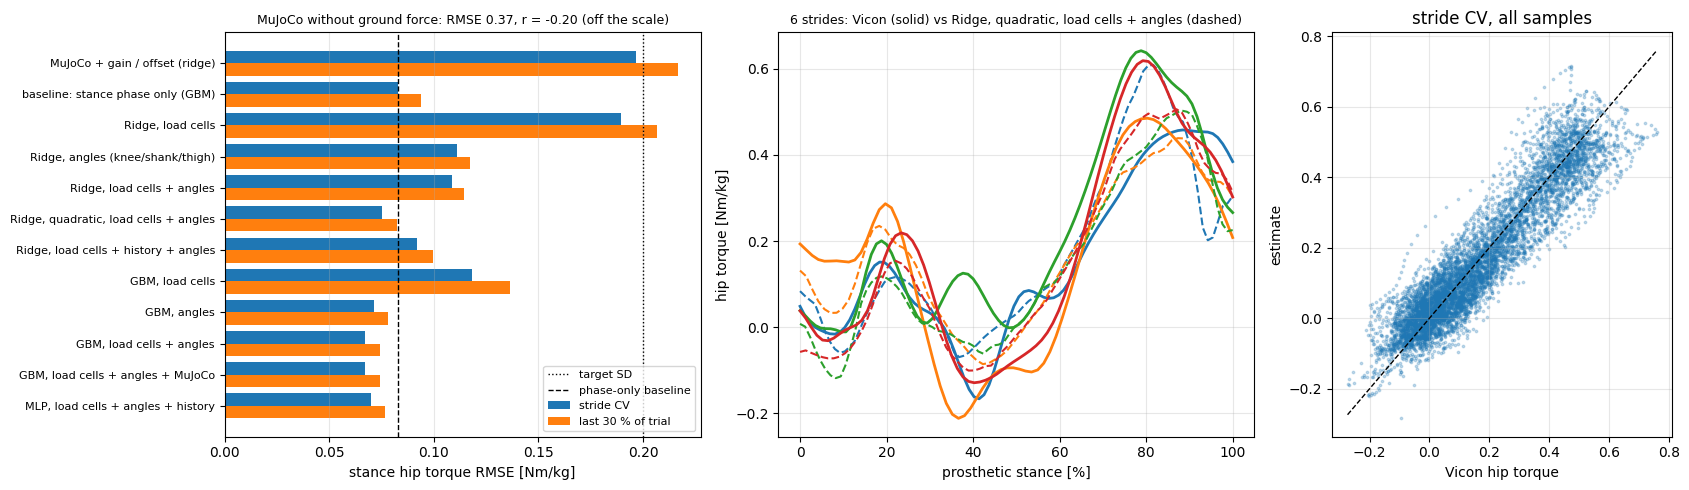

,model,feature,stride r,block r,mean error [Nm/kg],RMSE [Nm/kg]
0,baseline: stance phase only (GBM),early max (loading),-0.19,-0.06,-0.02,0.06
1,baseline: stance phase only (GBM),late max (push-off),0.30,0.30,-0.01,0.08
2,"Ridge, quadratic, load cells + angles",early max (loading),0.47,0.63,-0.03,0.06
3,"Ridge, quadratic, load cells + angles",late max (push-off),0.12,0.13,-0.00,0.09
4,"GBM, angles",early max (loading),0.63,0.73,-0.02,0.05
5,"GBM, angles",late max (push-off),0.10,0.25,-0.00,0.08
6,"GBM, load cells + angles",early max (loading),0.63,0.61,-0.02,0.05
7,"GBM, load cells + angles",late max (push-off),0.21,0.58,0.00,0.08
8,"MLP, load cells + angles + history",early max (loading),0.48,0.30,-0.01,0.05
9,"MLP, load cells + angles + history",late max (push-off),0.09,-0.16,-0.00,0.08


In [186]:
best_s = "GBM, load cells + angles"
# best_s = "baseline: stance phase only (GBM)"
best_s = "Ridge, quadratic, load cells + angles"
fig, ax = plt.subplots(1, 3, figsize=(17, 5), gridspec_kw={"width_ratios": [1.4, 1.4, 1]})
d = res_st[res_st.model != "MuJoCo, no ground force"].pivot(index="model", columns="split", values="RMSE [Nm/kg]").loc[[m for m in MODELS_S if m != "MuJoCo, no ground force"]]
yy = np.arange(len(d))
ax[0].barh(yy - 0.2, d["stride CV"], 0.4, label="stride CV", color="C0"); ax[0].barh(yy + 0.2, d["last 30 %"], 0.4, label="last 30 % of trial", color="C1")
ax[0].axvline(Y_H.std(), color="k", ls=":", lw=1, label="target SD"); ax[0].axvline(float(d.loc["baseline: stance phase only (GBM)", "stride CV"]), color="k", ls="--", lw=1, label="phase-only baseline")
ax[0].set_yticks(yy, d.index, fontsize=8); ax[0].invert_yaxis(); ax[0].set_xlabel("stance hip torque RMSE [Nm/kg]"); ax[0].legend(fontsize=8); ax[0].grid(alpha=0.3, axis="x")
ax[0].set_title("MuJoCo without ground force: RMSE %.2f, r = %.2f (off the scale)" % (res_st[(res_st.model == "MuJoCo, no ground force") & (res_st.split == "stride CV")]["RMSE [Nm/kg]"].iloc[0], res_st[(res_st.model == "MuJoCo, no ground force") & (res_st.split == "stride CV")]["r"].iloc[0]), fontsize=9)
pb = PRED_S[(best_s, "group")]
for c_, i in zip(plt.cm.tab10(np.arange(6)), np.linspace(0, len(parts) - 1, 4).astype(int)):
    m = gid_s == i
    ax[1].plot(100 * ph_in[m], Y_H[m], color=c_, lw=2); ax[1].plot(100 * ph_in[m], pb[m], color=c_, lw=1.5, ls="--")
ax[1].set_xlabel("prosthetic stance [%]"); ax[1].set_ylabel(f"hip torque [{TORQUE_UNIT}]"); ax[1].grid(alpha=0.3)
ax[1].set_title(f"6 strides: Vicon (solid) vs {best_s} (dashed)", fontsize=9)
ax[2].scatter(Y_H, pb, s=3, alpha=0.25); lim = [Y_H.min(), Y_H.max()]; ax[2].plot(lim, lim, "k--", lw=1)
ax[2].set_xlabel("Vicon hip torque"); ax[2].set_ylabel("estimate"); ax[2].set_title("stride CV, all samples"); ax[2].grid(alpha=0.3)
fig.tight_layout(); FIGS["fig17_stance_hip_estimate"] = fig
plt.show()
feat_table.round(2)

## 21. Save the figures (optional)
All figures in `FIGS` are written as PNG next to the trial file.

In [ ]:
import os
out_dir = os.path.dirname(TRIAL)
for name, f in FIGS.items():
    p = os.path.join(out_dir, f"trial_09_{name}.png")
    f.savefig(p, dpi=150)
    print("saved", p)

saved /Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0/trial_09_fig1_overview.png
saved /Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0/trial_09_fig2_gait_cycles.png
saved /Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0/trial_09_fig3_sync.png
saved /Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0/trial_09_fig3b_angles_vs_vicon.png
saved /Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0/trial_09_fig4_timeline.png
saved /Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0/trial_09_fig5_profiles.png
saved /Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0/trial_09_fig6_scatter.png
saved /Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0/trial_09_fig7_mujoco_profiles.png
saved /Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0/trial_09_fig8_mujoco_vs_vicon.png
saved /Users/xinyi/Documents/Data/ossur/OT_08_12/0927_vicon/vicon_0/trial_09_fig9_mujoco_params.png
saved /Users/xinyi/Docume